# Modélisation

## Objectif de la modélisation

À l'issue des étapes d'exploration, de visualisation et de prétraitement des données, le jeu de données est désormais prêt à être exploité dans le cadre de la phase de modélisation.

L'objectif de cette étape est de construire un ou plusieurs modèles de régression capables de prédire les émissions de dioxyde de carbone (CO₂) des véhicules à partir de leurs caractéristiques techniques et énergétiques.

Plusieurs modèles de régression seront entraînés puis comparés afin d'identifier celui offrant les meilleures performances prédictives. L'évaluation reposera principalement sur les métriques MAE (Mean Absolute Error), RMSE (Root Mean Squared Error) et R² (coefficient de détermination). La MAPE (Mean Absolute Percentage Error) pourra également être utilisée à titre complémentaire.

Conformément aux objectifs du projet, une attention particulière sera portée aux performances des modèles. Leur interprétabilité sera également prise en compte afin de faciliter l'analyse des résultats et la compréhension de l'influence des variables explicatives sur les émissions de CO₂.

In [1]:
# Import des bibliothèques

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import shap
import tensorflow as tf

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import learning_curve
from sklearn.model_selection import cross_val_score

from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

/home/iadi3280/Projet_CO2/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1791748685.653522    4035 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791748685.656761    4035 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791748685.717479    4035 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:179

## Chargement des jeux de données prétraités

Les jeux de données préparés lors de la phase de prétraitement sont chargés afin d'être utilisés pour l'entraînement et l'évaluation des différents modèles de régression.

In [2]:
# Chargement des jeux de données

X_train = pd.read_csv("../data/X_train_final.csv")
X_test = pd.read_csv("../data/X_test_final.csv")

y_train = pd.read_csv("../data/y_train.csv")["co2"]
y_test = pd.read_csv("../data/y_test.csv")["co2"]

## Vérification des jeux de données

Avant de débuter l'entraînement des modèles, une vérification des dimensions des jeux de données est réalisée afin de s'assurer de leur cohérence.

In [3]:
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)

print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test  :", y_test.shape)

Dimensions de X_train : (44002, 93)
Dimensions de X_test  : (11001, 93)
Dimensions de y_train : (44002,)
Dimensions de y_test  : (11001,)


In [4]:
X_train.head()

,puiss_max,conso_mixte,co_typ_1,nox,ptcl,masse_ordma_min,masse_ordma_max,rapport_puissance_masse,lib_mrq_ASTON MARTIN,lib_mrq_AUDI,...,typ_boite_nb_rapp_A 9,typ_boite_nb_rapp_D 5,typ_boite_nb_rapp_D 6,typ_boite_nb_rapp_D 7,typ_boite_nb_rapp_M 5,typ_boite_nb_rapp_M 6,typ_boite_nb_rapp_M 7,typ_boite_nb_rapp_S 6,typ_boite_nb_rapp_V .,typ_boite_nb_rapp_V 0
0,120.0,7.2,0.046,0.197,0.000,2076,2185,0.057803,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,125.0,5.2,0.440,0.030,0.001,1380,1380,0.090580,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,120.0,7.4,0.401,0.213,0.001,2246,2709,0.053428,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,120.0,7.7,0.175,0.226,0.001,2186,2355,0.054895,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,120.0,7.7,0.046,0.197,0.000,2186,2350,0.054895,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Présentation des jeux de données

Les jeux de données utilisés pour la modélisation sont désormais entièrement numériques et prêts à être exploités par les différents algorithmes de Machine Learning.

Le jeu d'entraînement (`X_train`) est utilisé pour apprendre les relations entre les variables explicatives et les émissions de CO₂, tandis que le jeu de test (`X_test`) permet d'évaluer les performances des modèles sur des données jamais vues pendant l'entraînement.

Les variables catégorielles ont été transformées par encodage One-Hot lors de la phase de prétraitement, ce qui permet à l'ensemble des modèles de travailler exclusivement sur des variables numériques.

In [5]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44002 entries, 0 to 44001
Data columns (total 93 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   puiss_max                        44002 non-null  float64
 1   conso_mixte                      44002 non-null  float64
 2   co_typ_1                         44002 non-null  float64
 3   nox                              44002 non-null  float64
 4   ptcl                             44002 non-null  float64
 5   masse_ordma_min                  44002 non-null  int64  
 6   masse_ordma_max                  44002 non-null  int64  
 7   rapport_puissance_masse          44002 non-null  float64
 8   lib_mrq_ASTON MARTIN             44002 non-null  float64
 9   lib_mrq_AUDI                     44002 non-null  float64
 10  lib_mrq_BENTLEY                  44002 non-null  float64
 11  lib_mrq_BMW                      44002 non-null  float64
 12  lib_mrq_CADILLAC  

In [6]:
X_train.describe()

,puiss_max,conso_mixte,co_typ_1,nox,ptcl,masse_ordma_min,masse_ordma_max,rapport_puissance_masse,lib_mrq_ASTON MARTIN,lib_mrq_AUDI,...,typ_boite_nb_rapp_A 9,typ_boite_nb_rapp_D 5,typ_boite_nb_rapp_D 6,typ_boite_nb_rapp_D 7,typ_boite_nb_rapp_M 5,typ_boite_nb_rapp_M 6,typ_boite_nb_rapp_M 7,typ_boite_nb_rapp_S 6,typ_boite_nb_rapp_V .,typ_boite_nb_rapp_V 0
count,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,...,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000,44002.000000
mean,118.888580,7.765620,0.180790,0.299221,0.000898,2103.413208,2343.264056,0.057724,0.001409,0.006113,...,0.000591,0.001136,0.000523,0.000455,0.018181,0.578246,0.000341,0.000023,0.000045,0.005568
std,45.091507,1.379192,0.144731,0.417127,0.000969,293.418196,422.748496,0.024769,0.037511,0.077949,...,0.024301,0.033690,0.022857,0.021315,0.133607,0.493845,0.018460,0.004767,0.006742,0.074411
min,28.000000,0.600000,0.005000,0.000000,0.000000,825.000000,825.000000,0.020144,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,100.000000,7.300000,0.061000,0.197000,0.000000,1982.000000,2075.000000,0.045746,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,120.000000,7.800000,0.137000,0.214000,0.001000,2076.000000,2355.000000,0.052016,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,120.000000,8.300000,0.296000,0.228000,0.001000,2246.000000,2709.000000,0.059172,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,585.000000,24.500000,0.968000,1.846000,0.023000,2760.000000,3094.000000,0.373802,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Vérification finale des jeux de données

Avant d'entraîner les modèles, une dernière vérification est réalisée afin de confirmer l'absence de valeurs manquantes dans les jeux d'entraînement et de test. Cette étape garantit que les données sont prêtes pour la modélisation.

In [7]:
# Vérification finale des valeurs manquantes

print("Nombre total de NaN dans X_train :", X_train.isna().sum().sum())
print("Nombre total de NaN dans X_test  :", X_test.isna().sum().sum())

print("Nombre total de NaN dans y_train :", y_train.isna().sum())
print("Nombre total de NaN dans y_test  :", y_test.isna().sum())

Nombre total de NaN dans X_train : 0
Nombre total de NaN dans X_test  : 0
Nombre total de NaN dans y_train : 0
Nombre total de NaN dans y_test  : 0


## Régression linéaire

La régression linéaire constitue le modèle de référence (baseline) de notre étude. Son principe repose sur l'hypothèse d'une relation linéaire entre les variables explicatives et les émissions de CO₂.

Ce modèle présente plusieurs avantages : il est rapide à entraîner, simple à interpréter et permet d'identifier l'influence des différentes variables sur la variable cible. Il servira de point de comparaison pour évaluer les performances des modèles plus complexes étudiés par la suite.

## Évaluation du modèle

### Entraînement du modèle

In [8]:
# Initialisation du modèle
reg_lin = LinearRegression()

# Entraînement
reg_lin.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Prédictions

In [9]:
y_pred_lin = reg_lin.predict(X_test)

### Performances du modèle

In [10]:
mae_lin = mean_absolute_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)
mape_lin = mean_absolute_percentage_error(y_test, y_pred_lin)

print(f"MAE  : {mae_lin:.2f}")
print(f"RMSE : {rmse_lin:.2f}")
print(f"R²   : {r2_lin:.4f}")
print(f"MAPE : {mape_lin:.4f}")

MAE  : 1.09
RMSE : 1.74
R²   : 0.9974
MAPE : 0.0059


### Comparaison avec un modèle de référence (DummyRegressor)

In [11]:
# Initialisation du DummyRegressor
dummy = DummyRegressor(strategy="mean")

# Entraînement
dummy.fit(X_train, y_train)

# Prédictions
y_pred_dummy = dummy.predict(X_test)

# Évaluation
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
r2_dummy = r2_score(y_test, y_pred_dummy)
mape_dummy = mean_absolute_percentage_error(y_test, y_pred_dummy)

# ============================================================
# TABLEAU COMPARATIF DES PERFORMANCES
# ============================================================

comparaison_dummy_lineaire = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Régression linéaire"],
    "MAE": [mae_dummy, mae_lin],
    "RMSE": [rmse_dummy, rmse_lin],
    "R²": [r2_dummy, r2_lin],
    "MAPE": [mape_dummy, mape_lin]
})

# Affichage avec 4 décimales
display(comparaison_dummy_lineaire.round(4))

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Régression linéaire,1.0922,1.7402,0.9974,0.0059


Le DummyRegressor constitue un modèle de référence qui prédit systématiquement la moyenne des émissions de CO₂ observées dans le jeu d'entraînement, sans exploiter les variables explicatives.

Les résultats obtenus montrent des performances très limitées (MAE = 22,45 g/km, RMSE = 34,16 g/km, R² ≈ 0), ce qui confirme qu'une prédiction basée uniquement sur la moyenne ne permet pas de représenter correctement les émissions de CO₂.

En comparaison, la régression linéaire réduit considérablement les erreurs de prédiction (MAE = 1,09 g/km, RMSE = 1,74 g/km) et explique 99,74 % de la variabilité des émissions (R² = 0,9974). Cette amélioration très importante démontre que la régression linéaire exploite efficacement les informations contenues dans les variables explicatives pour prédire les émissions de CO₂.

### Analyse de la capacité de généralisation

In [12]:
print("Score R² sur le jeu d'entraînement :", reg_lin.score(X_train, y_train))
print("Score R² sur le jeu de test         :", reg_lin.score(X_test, y_test))

Score R² sur le jeu d'entraînement : 0.9971944479710525
Score R² sur le jeu de test         : 0.9974042518995572


Les coefficients de détermination obtenus sur les jeux d'entraînement (R² = 0,9972) et de test (R² = 0,9974) sont quasiment identiques.

Cette proximité montre que le modèle généralise correctement aux données non vues et ne présente pas de signe apparent de surapprentissage. Les excellentes performances observées sur le jeu de test traduisent une forte relation linéaire entre les variables explicatives retenues et les émissions de CO₂.

### Valeurs réelles vs valeurs prédites

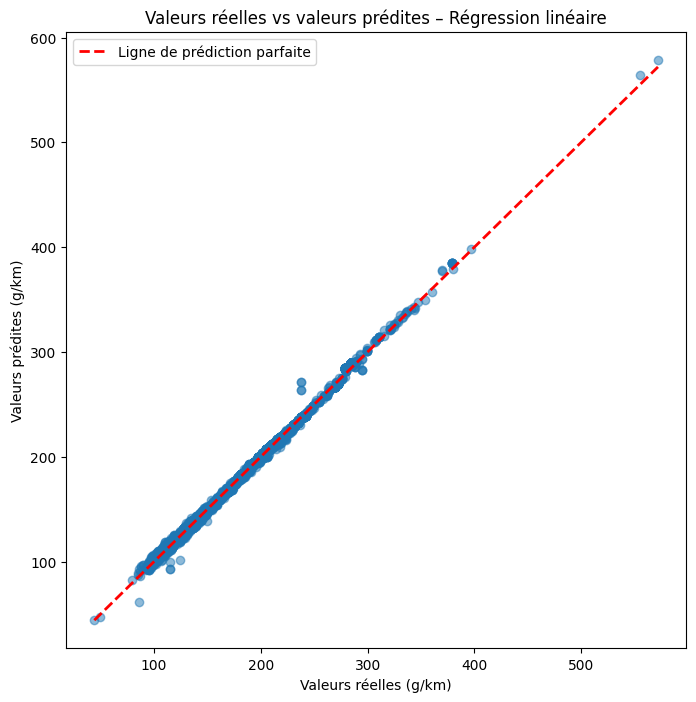

In [13]:
plt.figure(figsize=(8, 8))

# Valeurs réelles vs prédites
plt.scatter(
    y_test,
    y_pred_lin,
    alpha=0.5
)

# Ligne idéale
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Régression linéaire")
plt.legend()

plt.show()

La régression linéaire obtient d'excellentes performances sur le jeu de test, avec un coefficient de détermination de 0,9974, indiquant que le modèle explique près de 99,74 % de la variabilité des émissions de CO₂. Les erreurs de prédiction restent très faibles, comme en témoignent le MAE (1,09 g/km), le RMSE (1,74 g/km) et le MAPE (0,59 %).

Le nuage de points met en évidence une très forte concordance entre les valeurs réelles et les valeurs prédites. La grande majorité des observations est alignée le long de la diagonale représentant une prédiction parfaite, ce qui confirme visuellement l'excellente qualité des prédictions.

Quelques écarts sont observés pour un nombre limité de véhicules, notamment pour certaines valeurs élevées des émissions de CO₂. Toutefois, ces écarts restent faibles au regard de l'ensemble des observations et n'affectent pas significativement la qualité globale du modèle.

La comparaison avec le DummyRegressor montre également que la régression linéaire surpasse très largement un modèle naïf prédisant uniquement la moyenne des émissions de CO₂. L'ensemble de ces résultats confirme que le modèle exploite efficacement les informations contenues dans les variables explicatives et constitue une excellente référence (baseline) pour comparer les modèles plus complexes étudiés par la suite.

### Analyse des résidus

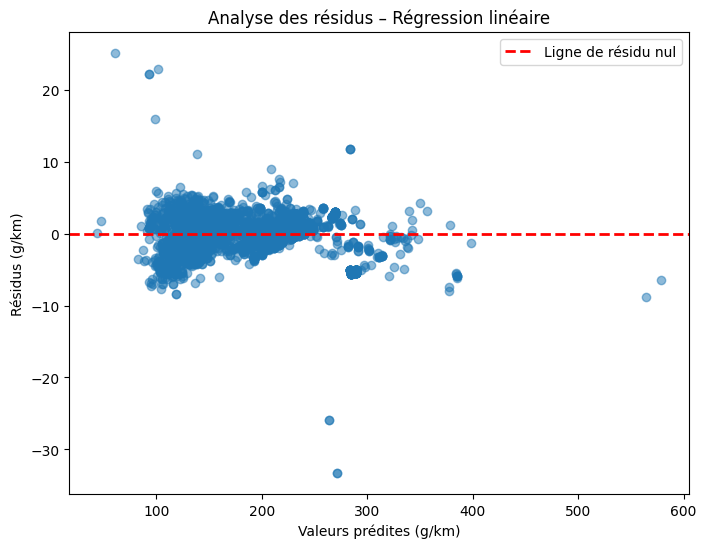

In [14]:
# Calcul des résidus
residus = y_test - y_pred_lin

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_lin,
    residus,
    alpha=0.5
)

# Ligne horizontale représentant un résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – Régression linéaire")
plt.legend()

plt.show()

Le graphique des résidus montre que les erreurs de prédiction sont globalement concentrées autour de la ligne de résidu nul, sans tendance systématique clairement identifiable. Cette répartition suggère que le modèle ne présente pas de biais majeur de surestimation ou de sous-estimation des émissions de CO₂.

La majorité des observations présente des résidus de faible amplitude, ce qui confirme la précision globale des prédictions. Quelques valeurs atypiques sont toutefois observées, avec des écarts plus importants pour certains véhicules. La dispersion des résidus varie également légèrement selon les valeurs prédites, sans remettre en cause les bonnes performances globales du modèle.

Cette analyse confirme la bonne qualité d'ajustement de la régression linéaire et complète les excellents résultats obtenus avec les métriques d'évaluation (R² = 0,9974, RMSE = 1,74 g/km et MAE = 1,09 g/km).

### Courbe d'apprentissage

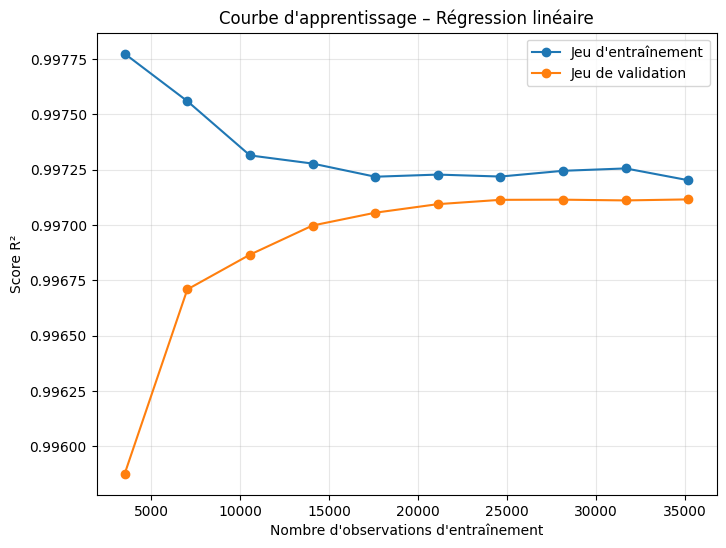

In [15]:
# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=reg_lin,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyennes des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – Régression linéaire")
plt.legend()

plt.grid(alpha=0.3)

plt.show()

La courbe d'apprentissage montre que les scores obtenus sur les jeux d'entraînement et de validation convergent progressivement vers des valeurs très élevées et deviennent très proches à mesure que le nombre d'observations augmente.

L'écart très faible entre les deux courbes indique que la régression linéaire généralise correctement aux données non vues et ne présente pas de signe notable de surapprentissage. Les performances se stabilisent à partir d'environ 20 000 observations, avec des scores R² proches de 0,9972 pour l'entraînement et 0,9971 pour la validation. Cette stabilisation suggère que le modèle exploite efficacement les informations disponibles et que l'ajout de données supplémentaires apporterait probablement un gain limité dans les mêmes conditions.

Cette analyse confirme les excellents résultats observés précédemment avec les différentes métriques d'évaluation ainsi que les graphiques des valeurs prédites et des résidus.

## Régression Ridge

La régression Ridge est une extension de la régression linéaire qui intègre une pénalisation de type L2 sur les coefficients du modèle.

Cette régularisation permet de limiter l'influence des variables fortement corrélées et de réduire le risque de surapprentissage. Elle est particulièrement adaptée lorsque le jeu de données comporte un grand nombre de variables explicatives, comme c'est le cas après l'encodage One-Hot des variables catégorielles.

L'objectif est d'évaluer si cette pénalisation améliore les performances prédictives par rapport à la régression linéaire classique.

### Entraînement du modèle

In [16]:
# Initialisation du modèle avec standardisation
ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

# Entraînement
ridge.fit(X_train, y_train)

,steps,"[('scaler', ...), ('ridge', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None


### Prédictions

In [17]:
# Prédictions sur le jeu de test
y_pred_ridge = ridge.predict(X_test)

### Performances du modèle

In [18]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)
mape_ridge = mean_absolute_percentage_error(y_test, y_pred_ridge)

print(f"MAE  : {mae_ridge:.2f}")
print(f"RMSE : {rmse_ridge:.2f}")
print(f"R²   : {r2_ridge:.4f}")
print(f"MAPE : {mape_ridge:.4f}")

MAE  : 1.09
RMSE : 1.74
R²   : 0.9974
MAPE : 0.0060


### Comparaison avec le DummyRegressor

In [19]:
comparaison_dummy_ridge = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Ridge"],
    "MAE": [mae_dummy, mae_ridge],
    "RMSE": [rmse_dummy, rmse_ridge],
    "R²": [r2_dummy, r2_ridge],
    "MAPE": [mape_dummy, mape_ridge]
})

comparaison_dummy_ridge = comparaison_dummy_ridge.round(4)
comparaison_dummy_ridge

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Ridge,1.0925,1.7401,0.9974,0.0060


Le DummyRegressor constitue un modèle de référence qui prédit systématiquement la moyenne des émissions de CO₂ observées dans le jeu d'entraînement, sans exploiter les variables explicatives.

Les performances obtenues avec Ridge sont très largement supérieures à celles du DummyRegressor. Alors que le modèle de référence obtient un coefficient de détermination proche de zéro (R² ≈ 0), Ridge explique 99,74 % de la variabilité des émissions de CO₂ et réduit fortement les erreurs de prédiction (MAE = 1,09 g/km, RMSE = 1,74 g/km).

Cette comparaison confirme que le modèle Ridge, associé à une standardisation des variables et à une régularisation L2, exploite efficacement les informations contenues dans les variables explicatives pour prédire les émissions de CO₂.

### Analyse de la capacité de généralisation

In [20]:
print("Score R² sur le jeu d'entraînement :", ridge.score(X_train, y_train))
print("Score R² sur le jeu de test         :", ridge.score(X_test, y_test))

Score R² sur le jeu d'entraînement : 0.9971944423356989
Score R² sur le jeu de test         : 0.9974044197695677


La régression Ridge obtient d'excellentes performances sur le jeu de test.

Le coefficient de détermination (R² = 0,9974) montre que le modèle explique près de 99,74 % de la variabilité des émissions de CO₂. Les erreurs de prédiction restent très faibles, avec un MAE de 1,09 g/km, un RMSE de 1,74 g/km et un MAPE de 0,60 %.

Les scores obtenus sur les jeux d'entraînement (R² = 0,9972) et de test (R² = 0,9974) sont très proches, ce qui indique que le modèle généralise correctement et ne présente pas de signe de surapprentissage.

Les performances sont quasiment identiques à celles de la régression linéaire. Sur ce jeu de données, l'ajout d'une pénalisation L2 n'apporte donc pas de gain significatif de performance par rapport au modèle linéaire de référence.

### Valeurs réelles vs valeurs prédites

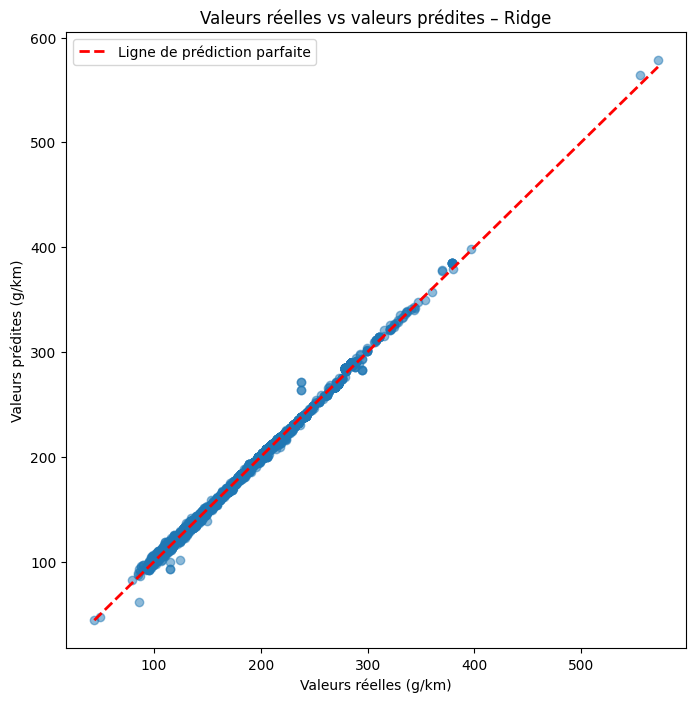

In [21]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_pred_ridge,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Ridge")
plt.legend()

plt.show()

Le nuage de points met en évidence une très forte concordance entre les valeurs réelles et les valeurs prédites par le modèle Ridge. La quasi-totalité des observations est alignée le long de la diagonale représentant une prédiction parfaite, ce qui traduit une excellente qualité de prédiction.

Quelques écarts sont observés pour un nombre limité de véhicules, notamment pour certaines valeurs élevées des émissions de CO₂. Toutefois, ces écarts restent limités au regard de l'ensemble des observations et n'affectent pas significativement la qualité globale du modèle.

Cette représentation graphique est cohérente avec les excellentes performances obtenues par le modèle (R² = 0,9974, RMSE = 1,74 g/km) et montre que la régularisation L2 conserve une très bonne capacité de prédiction des émissions de CO₂.

### Analyse des résidus

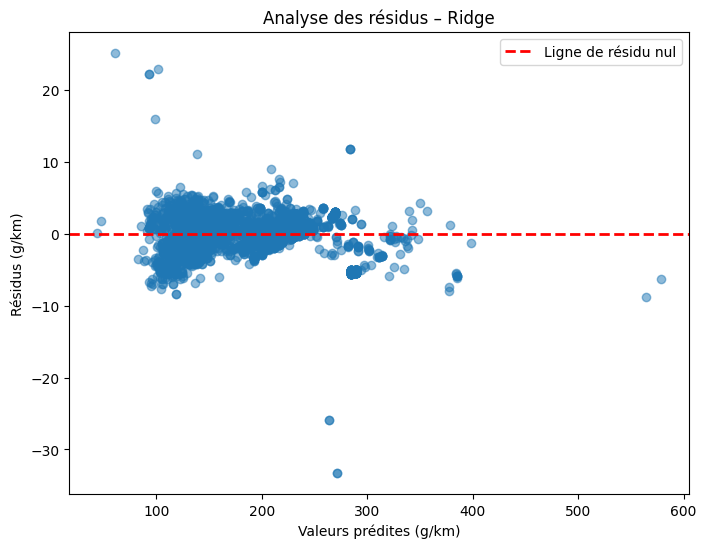

In [22]:
# Calcul des résidus
residus_ridge = y_test - y_pred_ridge

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_ridge,
    residus_ridge,
    alpha=0.5
)

# Ligne horizontale représentant un résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – Ridge")
plt.legend()

plt.show()

Le graphique des résidus montre que les erreurs de prédiction du modèle Ridge sont globalement concentrées autour de la ligne de résidu nul. Cette répartition indique que le modèle présente des erreurs généralement faibles, sans tendance systématique marquée à surestimer ou à sous-estimer les émissions de CO₂.

Quelques observations présentent des résidus plus importants, mais elles restent peu nombreuses au regard de l'ensemble des données. La dispersion des résidus varie légèrement selon les valeurs prédites, notamment pour certains véhicules présentant des émissions plus élevées. Toutefois, la majorité des observations reste proche de la ligne de résidu nul, ce qui traduit une bonne qualité d'ajustement du modèle.

Cette analyse est cohérente avec les excellentes performances obtenues précédemment (R² = 0,9974, RMSE = 1,74 g/km) et confirme que Ridge conserve une très bonne capacité de prédiction sur les données de test.

### Courbe d'apprentissage

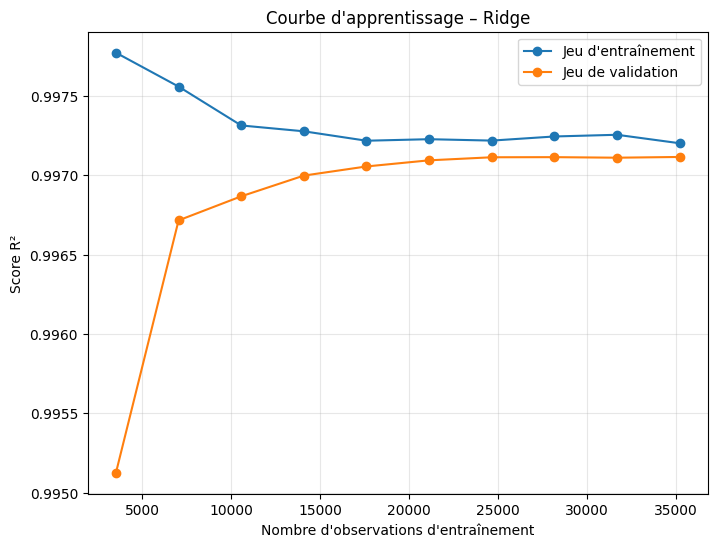

In [23]:

# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=ridge,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyennes des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – Ridge")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

La courbe d'apprentissage montre que les scores obtenus sur les jeux d'entraînement et de validation convergent rapidement vers des valeurs très élevées et restent très proches l'un de l'autre à mesure que le nombre d'observations augmente.

L'écart très faible entre les deux courbes indique que le modèle Ridge généralise correctement aux données non vues et ne présente pas de signe notable de surapprentissage. Les performances se stabilisent à partir d'environ 20 000 observations, ce qui suggère que le modèle exploite efficacement les informations disponibles et que l'ajout d'un plus grand nombre d'observations n'apporterait probablement qu'un gain marginal de performance.

Cette analyse confirme les excellentes performances observées précédemment (R² = 0,9974, RMSE = 1,74 g/km), ainsi que les résultats des graphiques des valeurs prédites et des résidus.

## Régression Lasso

La régression Lasso est une variante de la régression linéaire qui applique une pénalisation de type L1 sur les coefficients du modèle.

Contrairement à la régression Ridge, cette pénalisation peut réduire certains coefficients exactement à zéro, réalisant ainsi une sélection automatique des variables les moins pertinentes. Cette propriété permet d'obtenir des modèles plus simples et potentiellement plus interprétables.

L'objectif est d'évaluer si cette régularisation améliore les performances prédictives tout en simplifiant le modèle.

### Entraînement du modèle

In [24]:
# Initialisation du modèle Lasso avec standardisation
lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=1.0, max_iter=10000))
])

# Entraînement
lasso.fit(X_train, y_train)

,steps,"[('scaler', ...), ('lasso', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True


### Prédictions

In [25]:
# Prédictions sur le jeu de test
y_pred_lasso = lasso.predict(X_test)

### Performances du modèle

In [26]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)
mape_lasso = mean_absolute_percentage_error(y_test, y_pred_lasso)

print(f"MAE  : {mae_lasso:.2f}")
print(f"RMSE : {rmse_lasso:.2f}")
print(f"R²   : {r2_lasso:.4f}")
print(f"MAPE : {mape_lasso:.4f}")

MAE  : 1.91
RMSE : 3.01
R²   : 0.9923
MAPE : 0.0102


### Comparaison avec le DummyRegressor

In [27]:
comparaison_dummy_lasso = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Lasso"],
    "MAE": [mae_dummy, mae_lasso],
    "RMSE": [rmse_dummy, rmse_lasso],
    "R²": [r2_dummy, r2_lasso],
    "MAPE": [mape_dummy, mape_lasso]
})

comparaison_dummy_lasso = comparaison_dummy_lasso.round(4)
comparaison_dummy_lasso

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Lasso,1.9067,3.0057,0.9923,0.0102


Le DummyRegressor constitue un modèle de référence qui prédit systématiquement la moyenne des émissions de CO₂ observées dans le jeu d'entraînement, sans exploiter les variables explicatives.

Les performances obtenues avec Lasso sont très largement supérieures à celles du DummyRegressor. Alors que le modèle de référence obtient un coefficient de détermination proche de zéro (R² ≈ 0), Lasso explique 99,23 % de la variabilité des émissions de CO₂ et réduit fortement les erreurs de prédiction (MAE = 1,91 g/km, RMSE = 3,01 g/km).

En revanche, les performances de Lasso restent inférieures à celles de la régression linéaire et de Ridge. Ce résultat est cohérent avec le principe de la régularisation L1, qui favorise la simplification du modèle en pouvant annuler certains coefficients afin de réaliser une sélection automatique des variables. Cette simplification peut améliorer l'interprétabilité du modèle, mais s'accompagne ici d'une perte de précision.

### Analyse de la capacité de généralisation

In [28]:
print("Score R² sur le jeu d'entraînement :", lasso.score(X_train, y_train))
print("Score R² sur le jeu de test         :", lasso.score(X_test, y_test))

Score R² sur le jeu d'entraînement : 0.9906434777350548
Score R² sur le jeu de test         : 0.9922559723667375


La régression Lasso obtient de très bonnes performances sur le jeu de test, avec un coefficient de détermination de 0,9923, indiquant que le modèle explique environ 99,23 % de la variabilité des émissions de CO₂.

Les scores obtenus sur les jeux d'entraînement (R² = 0,9907) et de test (R² = 0,9923) sont très proches. Cette proximité montre que le modèle généralise correctement aux données non vues et ne présente pas de signe de surapprentissage.

Toutefois, les performances restent inférieures à celles de la régression linéaire et de Ridge (R² ≈ 0,9974). Sur ce jeu de données, la régularisation L1 entraîne donc une perte de précision par rapport aux deux autres modèles, tout en favorisant la simplification du modèle.

### Valeurs réelles vs valeurs prédites

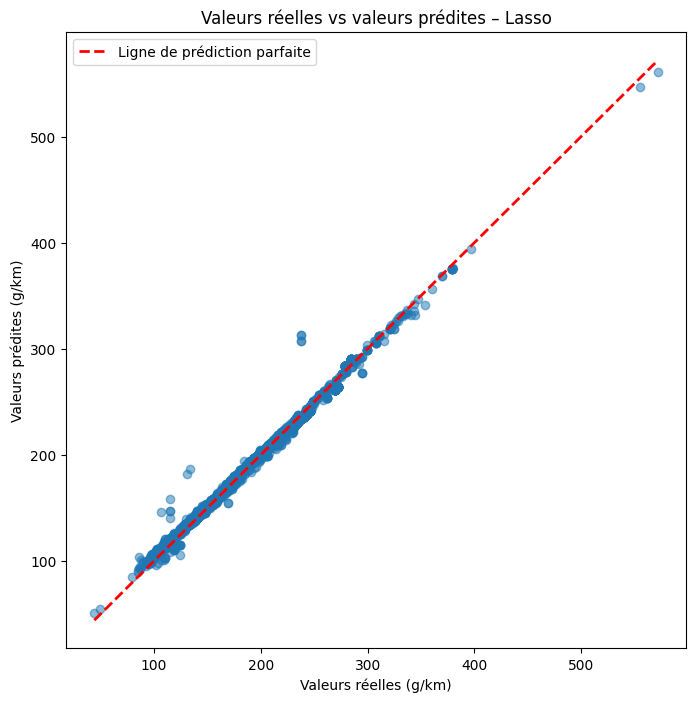

In [29]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_lasso,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Lasso")

plt.legend()

plt.show()

Le nuage de points met en évidence une très bonne concordance entre les valeurs réelles et les valeurs prédites par le modèle Lasso. La grande majorité des observations reste proche de la diagonale représentant une prédiction parfaite, ce qui confirme que le modèle conserve une bonne capacité de prédiction.

Toutefois, la dispersion des points est légèrement plus importante que pour la régression linéaire et Ridge. Quelques écarts à la diagonale sont observés, notamment pour certaines valeurs intermédiaires et pour les émissions les plus élevées, qui semblent être légèrement sous-estimées.

Cette représentation graphique est cohérente avec les performances du modèle (R² = 0,9923, RMSE = 3,01 g/km) et illustre le compromis introduit par la régularisation L1 : une simplification potentielle du modèle grâce à la sélection automatique de variables, au prix d'une perte de précision par rapport à la régression linéaire et à Ridge.

### Analyse des résidus

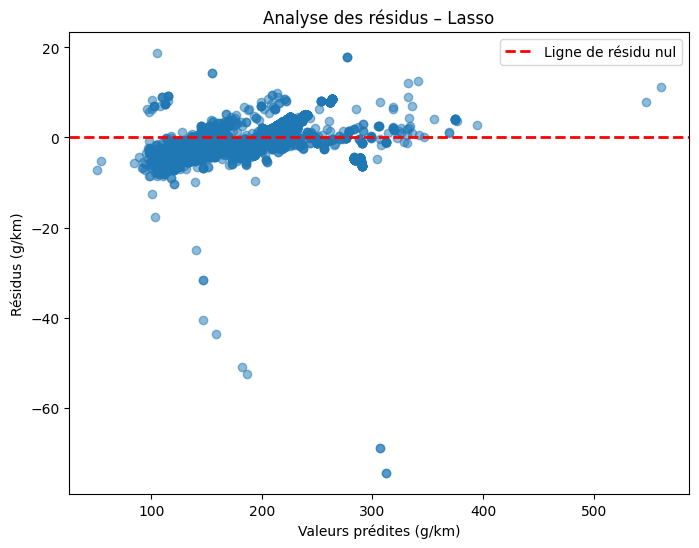

In [30]:
# Calcul des résidus
residus_lasso = y_test - y_pred_lasso

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_lasso,
    residus_lasso,
    alpha=0.5
)

# Ligne de résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – Lasso")

plt.legend()

plt.show()

Le graphique des résidus montre que les erreurs de prédiction du modèle Lasso restent majoritairement concentrées autour de la ligne de résidu nul, ce qui traduit une bonne qualité d'ajustement globale.

Toutefois, la dispersion des résidus est plus importante que pour la régression linéaire et Ridge. Plusieurs observations présentent des erreurs de prédiction élevées, notamment pour certaines valeurs intermédiaires des émissions de CO₂. Quelques résidus négatifs particulièrement importants montrent que le modèle surestime sensiblement les émissions de certains véhicules.

Cette analyse est cohérente avec les performances obtenues précédemment (R² = 0,9923, RMSE = 3,01 g/km) et illustre le compromis introduit par la régularisation L1 : une simplification potentielle du modèle grâce à la sélection automatique de variables, au prix d'une augmentation des erreurs de prédiction par rapport à la régression linéaire et à Ridge.

### Courbe d'apprentissage

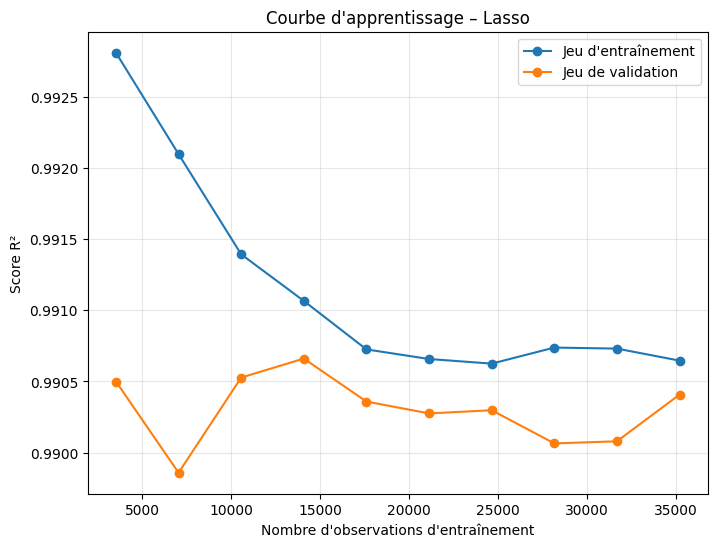

In [31]:
# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=lasso,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyenne des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – Lasso")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

La courbe d'apprentissage montre que les scores obtenus sur les jeux d'entraînement et de validation se rapprochent progressivement et restent très élevés tout au long de l'apprentissage.

L'écart très faible entre les deux courbes indique que le modèle Lasso généralise correctement aux données non vues et ne présente pas de signe de surapprentissage important. Les performances se stabilisent à partir d'environ 20 000 observations, ce qui suggère que l'ajout de données supplémentaires apporterait probablement un gain limité dans les conditions actuelles.

En revanche, les deux courbes se stabilisent à un niveau inférieur à celui observé pour la régression linéaire et Ridge. Ce résultat est cohérent avec le principe de la régularisation L1, qui favorise la simplification du modèle en pouvant annuler certains coefficients, au prix d'une diminution de la précision des prédictions.

## Arbre de décision

L'arbre de décision est un modèle non linéaire capable de capturer des relations complexes entre les variables explicatives et la variable cible.

Contrairement aux modèles de régression linéaire, Ridge et Lasso, il ne suppose aucune relation linéaire entre les variables. Il segmente progressivement les données en fonction des variables les plus discriminantes afin de minimiser l'erreur de prédiction.

L'objectif est d'évaluer si cette approche permet d'améliorer les performances prédictives par rapport aux modèles linéaires.

### Entraînement du modèle

In [32]:
# Initialisation du modèle
tree = DecisionTreeRegressor(random_state=42)

# Entraînement
tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


### Prédictions

In [33]:
# Prédictions sur le jeu de test
y_pred_tree = tree.predict(X_test)

### Performances du modèle

In [34]:
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)
mape_tree = mean_absolute_percentage_error(y_test, y_pred_tree)

print(f"MAE  : {mae_tree:.4f}")
print(f"RMSE : {rmse_tree:.4f}")
print(f"R²   : {r2_tree:.4f}")
print(f"MAPE : {mape_tree:.4f}")

MAE  : 0.0872
RMSE : 1.0377
R²   : 0.9991
MAPE : 0.0007


### Comparaison avec le DummyRegressor

In [35]:
comparaison_dummy_tree = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Arbre de décision"],
    "MAE": [mae_dummy, mae_tree],
    "RMSE": [rmse_dummy, rmse_tree],
    "R²": [r2_dummy, r2_tree],
    "MAPE": [mape_dummy, mape_tree]
})

comparaison_dummy_tree = comparaison_dummy_tree.round(4)
comparaison_dummy_tree

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Arbre de décision,0.0872,1.0377,0.9991,0.0007


Le DummyRegressor constitue un modèle de référence qui prédit systématiquement la moyenne des émissions de CO₂ observées dans le jeu d'entraînement, sans exploiter les variables explicatives.

Les performances obtenues par l'Arbre de décision sont très largement supérieures à celles du DummyRegressor. Le modèle explique 99,91 % de la variabilité des émissions de CO₂ et réduit considérablement les erreurs de prédiction (MAE = 0,09 g/km, RMSE = 1,04 g/km), ce qui confirme sa très forte capacité à modéliser les relations entre les caractéristiques des véhicules et leurs émissions.

Cette comparaison met en évidence que l'Arbre de décision est le modèle le plus performant parmi ceux évalués jusqu'à présent dans cette étude. Toutefois, les excellentes performances observées devront être complétées par l'analyse de la capacité de généralisation, des résidus et de la courbe d'apprentissage afin d'identifier un éventuel surapprentissage.

### Analyse de la capacité de généralisation

In [36]:
print("Score R² sur le jeu d'entraînement :", tree.score(X_train, y_train))
print("Score R² sur le jeu de test         :", tree.score(X_test, y_test))

Score R² sur le jeu d'entraînement : 0.9999902979276046
Score R² sur le jeu de test         : 0.9990769912832347


L'arbre de décision obtient les meilleures performances parmi les modèles évalués jusqu'à présent.

Le coefficient de détermination (R² = 0,9991) montre que le modèle explique plus de 99,9 % de la variabilité des émissions de CO₂. Les erreurs de prédiction sont les plus faibles de cette étude, avec un MAE de 0,09 g/km, un RMSE de 1,04 g/km et un MAPE de 0,07 %.

Les scores obtenus sur les jeux d'entraînement (R² = 0,99999) et de test (R² = 0,99908) restent très élevés, bien qu'un léger écart apparaisse entre les deux. Cela suggère un léger surapprentissage, phénomène classique pour un arbre de décision non élagué, sans pour autant dégrader significativement les performances sur le jeu de test.

### Valeurs réelles vs valeurs prédites

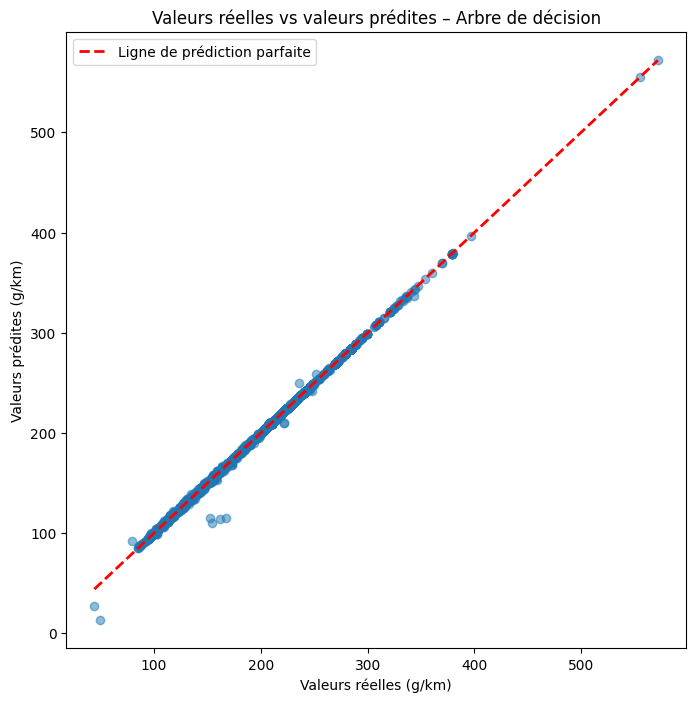

In [37]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_tree,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Arbre de décision")

plt.legend()

plt.show()

Le nuage de points met en évidence une excellente concordance entre les valeurs réelles et les valeurs prédites par l'Arbre de décision. La quasi-totalité des observations est alignée le long de la diagonale représentant une prédiction parfaite, ce qui traduit une très grande précision des prédictions.

Seules quelques observations présentent un écart plus marqué par rapport à la diagonale, notamment pour certaines valeurs faibles et intermédiaires des émissions de CO₂. Ces écarts restent toutefois très peu nombreux au regard de l'ensemble des données. Les valeurs les plus élevées des émissions de CO₂ sont également correctement prédites, ce qui confirme la bonne capacité du modèle à prédire sur une large plage de valeurs.

Cette représentation graphique est cohérente avec les excellentes performances obtenues par le modèle (R² = 0,9991, RMSE = 1,04 g/km) et confirme que l'Arbre de décision présente les meilleures performances parmi les modèles évalués jusqu'à présent dans cette étude.

### Analyse des résidus

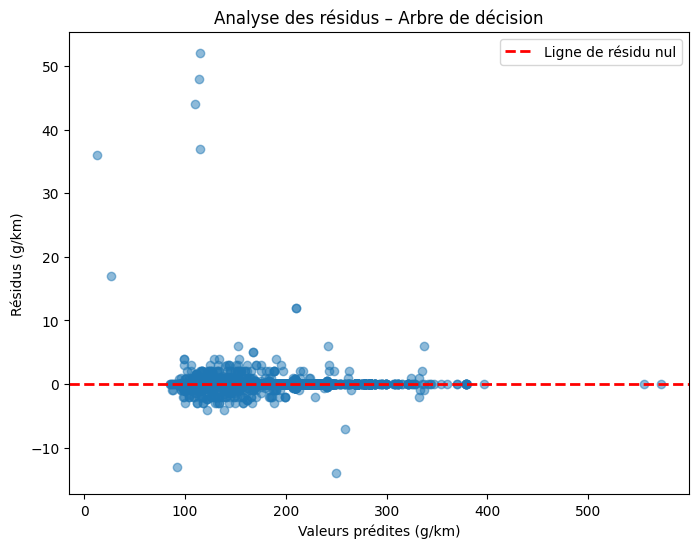

In [38]:
# Calcul des résidus
residus_tree = y_test - y_pred_tree

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_tree,
    residus_tree,
    alpha=0.5
)

# Ligne représentant un résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – Arbre de décision")

plt.legend()

plt.show()

Le graphique des résidus montre que les erreurs de prédiction de l'Arbre de décision sont très majoritairement concentrées autour de la ligne de résidu nul. Cette répartition traduit une excellente qualité d'ajustement et ne met pas en évidence de biais systématique marqué dans les prédictions.

La dispersion des résidus est très faible pour la majorité des observations, ce qui est cohérent avec les excellentes performances obtenues (R² = 0,9991, RMSE = 1,04 g/km). Quelques observations isolées présentent toutefois des résidus plus importants, principalement positifs, notamment pour certaines valeurs faibles et intermédiaires des émissions prédites. Ces observations restent très peu nombreuses au regard de l'ensemble des données et leur influence sur les performances globales demeure limitée.

Cette analyse confirme que l'Arbre de décision présente une excellente capacité de prédiction sur le jeu de test. Toutefois, le léger écart observé entre les scores d'entraînement et de test suggère un possible surapprentissage. La courbe d'apprentissage permettra de compléter cette analyse et de mieux évaluer la capacité de généralisation du modèle.

### Courbe d'apprentissage

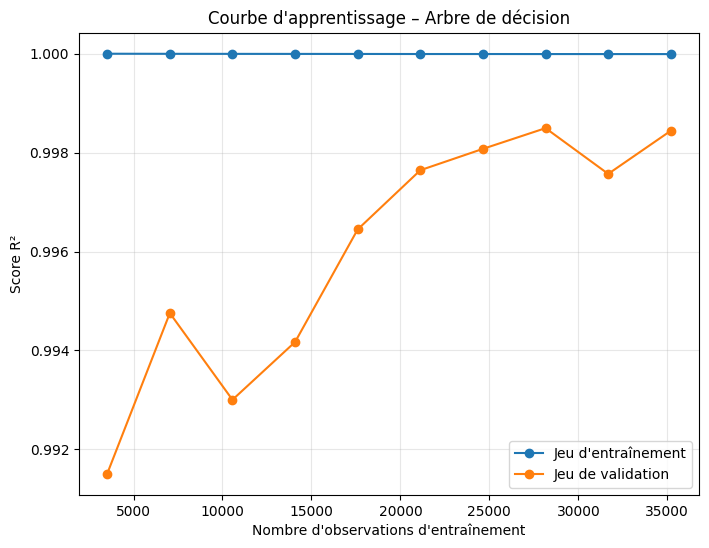

In [39]:

# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=tree,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyenne des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – Arbre de décision")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

La courbe d'apprentissage montre que le score obtenu sur le jeu d'entraînement reste quasiment parfait (R² ≈ 1,00) tout au long de l'apprentissage, tandis que le score du jeu de validation augmente progressivement avec la taille du jeu de données pour atteindre environ 0,9985.

Un léger écart persiste entre les deux courbes en fin d'apprentissage, ce qui traduit un léger phénomène de surapprentissage, fréquent pour un arbre de décision non élagué. Toutefois, cet écart reste très faible et n'altère pas significativement la qualité globale des prédictions.

Cette analyse confirme que l'Arbre de décision présente les meilleures performances parmi les modèles évalués jusqu'à présent, tout en conservant une excellente capacité de généralisation. Les performances observées sur le jeu de validation montrent que le modèle bénéficie de l'augmentation du nombre d'observations et reste particulièrement performant pour prédire les émissions de CO₂.

### Importance des variables

In [40]:
importance = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": tree.feature_importances_
})

importance.sort_values("Importance", ascending=False).head(15)

,Variable,Importance
1,conso_mixte,0.976381
3,nox,0.007972
60,cod_cbr_GO,0.007833
6,masse_ordma_max,0.002215
0,puiss_max,0.001412
59,cod_cbr_GN/ES,0.000750
52,cod_cbr_ES,0.000650
5,masse_ordma_min,0.000578
68,Carrosserie_MINIBUS,0.000432
87,typ_boite_nb_rapp_M 5,0.000360


L'analyse de l'importance des variables montre que la consommation mixte (`conso_mixte`) constitue de loin le principal facteur utilisé par l'arbre de décision. À elle seule, cette variable représente environ 97,64 % de l'importance totale du modèle.

Les autres variables, notamment les émissions de NOx (`nox`), le type de carburant (`cod_cbr`), la masse maximale (`masse_ordma_max`) et la puissance maximale (`puiss_max`), contribuent de manière beaucoup plus limitée à la prédiction.

Ces résultats sont cohérents avec l'analyse exploratoire réalisée précédemment, qui avait déjà mis en évidence une très forte corrélation entre la consommation mixte et les émissions de CO₂. Cette importance très élevée contribue à expliquer les excellentes performances obtenues par l'Arbre de décision.

Toutefois, elle montre également que le modèle repose très largement sur une seule variable explicative. Cette observation justifie les expérimentations réalisées ultérieurement sans `conso_mixte`, afin d'évaluer les performances du modèle en son absence et d'examiner un éventuel risque de fuite d'information.

## Comparaison des modèles

Les performances des différents modèles de régression sont comparées à l'aide de quatre indicateurs : le MAE (Mean Absolute Error), le RMSE (Root Mean Squared Error), le coefficient de détermination (R²) et le MAPE (Mean Absolute Percentage Error).

Cette comparaison permet d'identifier le modèle offrant le meilleur compromis entre précision des prédictions et capacité de généralisation.

In [41]:
comparaison = pd.DataFrame({
    "Modèle": [
        "Régression linéaire",
        "Ridge",
        "Lasso",
        "Arbre de décision"
    ],
    "MAE": [
        mae_lin,
        mae_ridge,
        mae_lasso,
        mae_tree
    ],
    "RMSE": [
        rmse_lin,
        rmse_ridge,
        rmse_lasso,
        rmse_tree
    ],
    "R²": [
        r2_lin,
        r2_ridge,
        r2_lasso,
        r2_tree
    ],
    "MAPE": [
        mape_lin,
        mape_ridge,
        mape_lasso,
        mape_tree
    ]
})

comparaison = comparaison.round({
    "MAE": 2,
    "RMSE": 2,
    "R²": 4,
    "MAPE": 4
})

comparaison

,Modèle,MAE,RMSE,R²,MAPE
0,Régression linéaire,1.09,1.74,0.9974,0.0059
1,Ridge,1.09,1.74,0.9974,0.0060
2,Lasso,1.91,3.01,0.9923,0.0102
3,Arbre de décision,0.09,1.04,0.9991,0.0007


### Analyse comparative des modèles

Les résultats montrent que les quatre modèles obtiennent des performances élevées sur ce jeu de données, mais avec des différences notables.

La régression linéaire constitue une excellente référence. Malgré sa simplicité, elle explique près de 99,7 % de la variabilité des émissions de CO₂ et présente des erreurs de prédiction très faibles (MAE = 1,09 g/km, RMSE = 1,74 g/km).

La régression Ridge obtient des performances quasiment identiques à celles de la régression linéaire (R² = 0,9974). Dans ce contexte, la pénalisation L2 n'apporte pas d'amélioration significative des performances.

La régression Lasso présente des performances légèrement inférieures à celles des deux modèles précédents (R² = 0,9923, RMSE = 3,01 g/km). La pénalisation L1 favorise la simplification du modèle en réduisant l'influence de certaines variables, voire en annulant certains coefficients, ce qui s'accompagne ici d'une diminution de la précision des prédictions.

L'Arbre de décision présente les meilleures performances parmi les modèles évalués, avec les erreurs de prédiction les plus faibles (MAE = 0,09 g/km, RMSE = 1,04 g/km) et le coefficient de détermination le plus élevé (R² = 0,9991). Les analyses graphiques confirment la très bonne qualité de ses prédictions. Bien qu'un léger surapprentissage soit observé sur la courbe d'apprentissage, les performances sur le jeu de validation restent excellentes, ce qui confirme une très bonne capacité de généralisation.

## Exploration automatique des modèles de régression avec LazyRegressor

Afin d'élargir la comparaison à un plus grand nombre d'algorithmes, une exploration automatique est réalisée à l'aide de LazyRegressor. Cet outil entraîne plusieurs modèles de régression avec leurs paramètres par défaut afin d'identifier les approches les plus prometteuses avant une éventuelle phase d'optimisation.

### Préparation de l'environnement d'exécution

Certaines variables d'environnement sont définies afin de limiter le nombre de threads utilisés par les bibliothèques numériques. Cette configuration améliore la stabilité de l'exécution de LazyRegressor dans l'environnement de travail utilisé.

### Interprétation des résultats de LazyRegressor

L'exploration automatique réalisée à l'aide de LazyRegressor a permis de comparer rapidement un large ensemble de modèles de régression en utilisant leurs paramètres par défaut. Cette approche constitue une première étape exploratoire visant à identifier les algorithmes les plus prometteurs avant une éventuelle phase d'optimisation des hyperparamètres.

Les résultats mettent en évidence les excellentes performances de plusieurs modèles d'ensemble, notamment ExtraTreesRegressor, RandomForestRegressor, BaggingRegressor et ExtraTreeRegressor, qui obtiennent des coefficients de détermination (R²) très élevés ainsi que des erreurs de prédiction (RMSE) particulièrement faibles. Ces résultats montrent que les caractéristiques techniques des véhicules permettent de prédire avec une grande précision les émissions de CO₂.

Les modèles linéaires, tels que LinearRegression, Ridge, RidgeCV et BayesianRidge, obtiennent également d'excellentes performances, avec des coefficients de détermination supérieurs à 0,99. Cela confirme que la relation entre les variables explicatives retenues et les émissions de CO₂ est largement linéaire lorsque les variables les plus informatives sont conservées.

À l'inverse, certains modèles comme DummyRegressor, Lars ou SGDRegressor affichent des performances nettement plus faibles. Ces résultats montrent que ces approches sont moins adaptées à la structure de ce jeu de données ou nécessiteraient un réglage plus fin de leurs hyperparamètres pour atteindre un niveau de performance comparable.

Ces résultats doivent toutefois être interprétés avec prudence. Plusieurs variables de consommation de carburant présentent une corrélation très forte avec la variable cible (CO₂), ce qui peut contribuer à ces excellentes performances. Afin d'évaluer la robustesse des modèles et de limiter le risque de dépendance à des variables fortement corrélées, des expérimentations complémentaires ont été réalisées en supprimant successivement certaines variables telles que conso_mixte, co_typ_1 et nox.

Il convient également de rappeler que LazyRegressor constitue un outil d'aide à la décision et non un outil de sélection définitive du modèle. Son objectif est de fournir une comparaison rapide de nombreux algorithmes afin d'orienter les expérimentations et les analyses plus approfondies.

Enfin, les performances présentées correspondent aux paramètres par défaut des différents algorithmes. Elles devront être confirmées et éventuellement améliorées lors d'une phase d'optimisation des hyperparamètres (GridSearchCV ou RandomizedSearchCV). Le choix du modèle final reposera non seulement sur ses performances prédictives, mais également sur sa robustesse, son interprétabilité, son coût de calcul et sa capacité de généralisation sur des données inédites.

## Conclusion générale de la modélisation

Cette phase de modélisation a permis d'évaluer plusieurs approches de régression afin de prédire les émissions de CO₂ des véhicules à partir de leurs caractéristiques techniques. Quatre modèles ont été étudiés en détail : la régression linéaire, Ridge, Lasso et l'Arbre de décision, à partir d'un jeu de données comprenant 93 variables explicatives après prétraitement et encodage.

Dans l'ensemble, les modèles obtiennent d'excellentes performances, confirmant l'existence d'une relation très forte entre les variables explicatives retenues et les émissions de CO₂. La régression linéaire constitue un excellent modèle de référence. Malgré sa simplicité, elle explique près de 99,7 % de la variabilité des émissions de CO₂ (R² = 0,9974) et présente des erreurs de prédiction très faibles (MAE = 1,09 g/km, RMSE = 1,74 g/km), ainsi qu'une très bonne capacité de généralisation.

La régression Ridge produit des performances quasiment identiques, montrant que l'ajout d'une régularisation L2 n'apporte pas de gain significatif sur ce jeu de données. À l'inverse, la régression Lasso obtient des résultats légèrement moins performants (R² = 0,9923, RMSE = 3,01 g/km). La pénalisation L1 favorise la simplification du modèle en réduisant l'influence de certaines variables explicatives, voire en annulant certains coefficients, mais cette simplification s'accompagne ici d'une diminution de la précision des prédictions.

Parmi ces quatre modèles, l'Arbre de décision présente les meilleures performances, avec un coefficient de détermination de 0,9991, un MAE de 0,09 g/km et un RMSE de 1,04 g/km. Les analyses quantitatives et graphiques (valeurs réelles vs valeurs prédites, résidus et courbes d'apprentissage) confirment la très bonne qualité de ses prédictions et sa capacité de généralisation, malgré un léger surapprentissage observé sur la courbe d'apprentissage.

Un premier test complémentaire réalisé avec LazyRegressor a également mis en évidence les excellentes performances d'ExtraTreesRegressor (R² = 0,9999, RMSE = 0,39 g/km), supérieures à celles de l'Arbre de décision. L'exploration complète des autres algorithmes reste à actualiser avec le nouveau jeu de données prétraité, afin d'identifier les modèles les plus prometteurs pour les phases d'optimisation.

L'analyse de l'importance des variables a par ailleurs montré que la consommation mixte (`conso_mixte`) domine très largement les prédictions de l'Arbre de décision, avec environ 97,64 % de l'importance totale. Ce résultat est cohérent avec la forte corrélation observée lors de l'analyse exploratoire. Il souligne néanmoins l'intérêt de poursuivre les expérimentations sans certaines variables fortement liées aux émissions de CO₂, notamment `conso_mixte`, `co_typ_1` et `nox`, afin d'évaluer leur influence sur les performances et d'examiner un éventuel risque de fuite d'information.

La suite du projet consistera à optimiser les modèles les plus prometteurs, à approfondir leur interprétabilité à l'aide de SHAP et à retenir le modèle offrant le meilleur compromis entre précision, robustesse, interprétabilité et capacité de généralisation.

## Interprétabilité des modèles avec SHAP

### Introduction

Afin de compléter l'évaluation des performances des différents modèles, une analyse d'interprétabilité est réalisée à l'aide de la méthode SHAP (SHapley Additive exPlanations).

Contrairement aux mesures classiques d'importance des variables, SHAP permet de quantifier la contribution de chaque caractéristique aux prédictions du modèle. Cette approche offre une interprétation à la fois globale et locale, permettant de mieux comprendre les facteurs qui influencent les émissions de CO₂ prédites.

L'objectif de cette analyse est d'identifier les variables les plus influentes, de comprendre leur effet sur les prédictions et de compléter l'évaluation des modèles par une analyse de leur fonctionnement.

### Régression linéaire

Une première analyse SHAP est réalisée sur le modèle de régression linéaire, qui présente d'excellentes performances prédictives sur le jeu de test (R² = 0,9974).

Trois représentations complémentaires sont proposées :

- une analyse de l'importance globale des variables ;
- un graphique illustrant l'effet des variables sur les prédictions ;
- une explication détaillée d'une prédiction individuelle.

Ces représentations permettent d'examiner les contributions des différentes caractéristiques techniques des véhicules et de mieux comprendre les prédictions produites par le modèle.

Dimension des valeurs SHAP : (1000, 93)


,Variable,Importance SHAP moyenne
1,conso_mixte,22.051776
60,cod_cbr_GO,9.178650
52,cod_cbr_ES,4.794883
75,gamme_MOY-INFER,1.667453
77,gamme_MOY-SUPER,1.531801
68,Carrosserie_MINIBUS,1.410071
7,rapport_puissance_masse,1.261877
0,puiss_max,1.257309
88,typ_boite_nb_rapp_M 6,0.774012
6,masse_ordma_max,0.459875


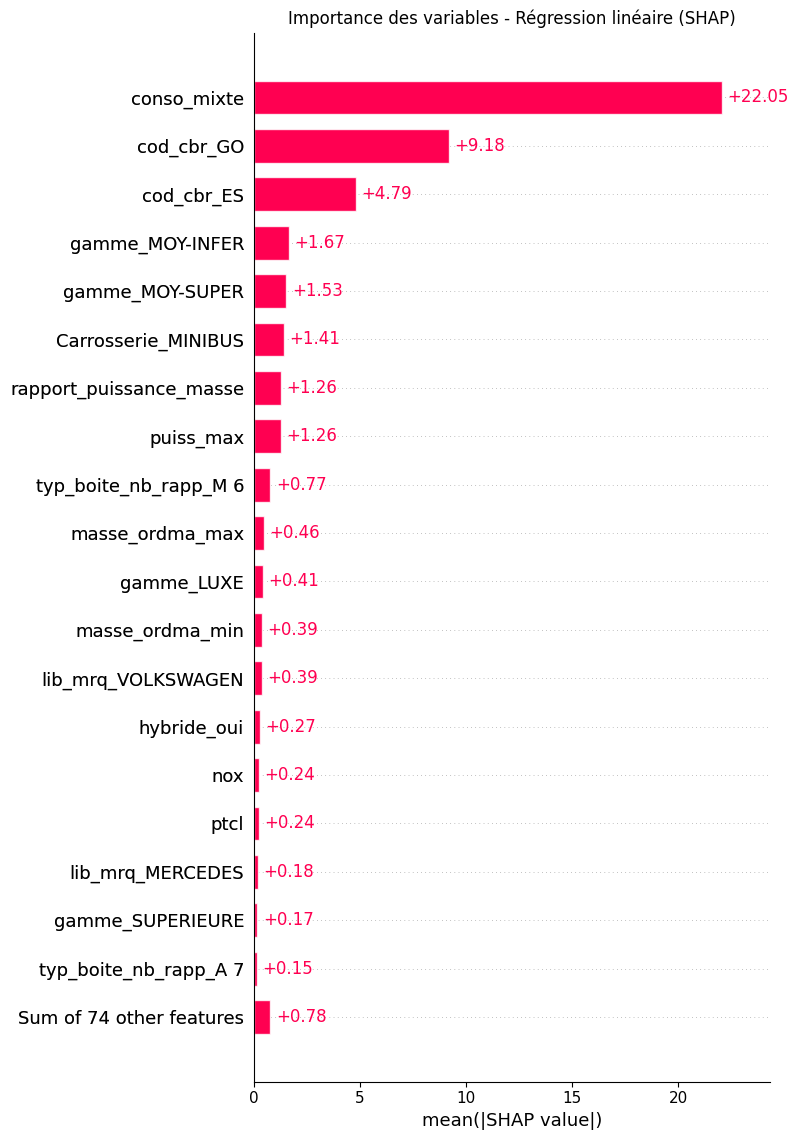

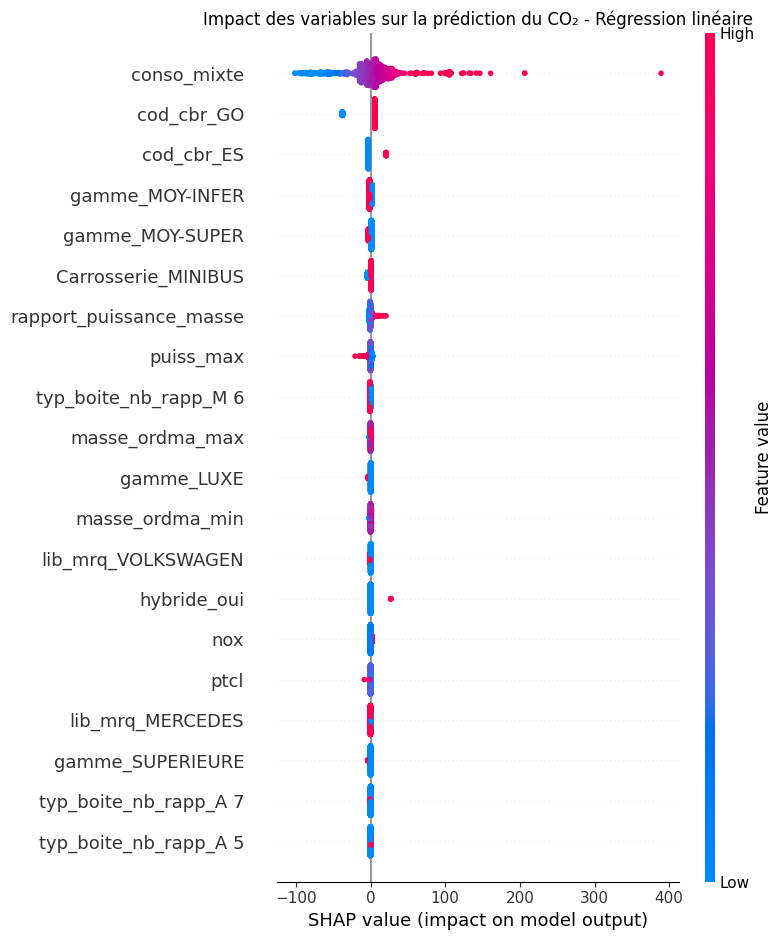

Observation analysée : 59
Index d'origine : 6887


,Variable,SHAP
1,conso_mixte,-19.418626
60,cod_cbr_GO,5.644392
52,cod_cbr_ES,-3.100551
0,puiss_max,1.797701
7,rapport_puissance_masse,-1.557159
75,gamme_MOY-INFER,-1.417314
77,gamme_MOY-SUPER,1.083152
49,lib_mrq_VOLKSWAGEN,-0.919995
68,Carrosserie_MINIBUS,0.912698
88,typ_boite_nb_rapp_M 6,-0.734980


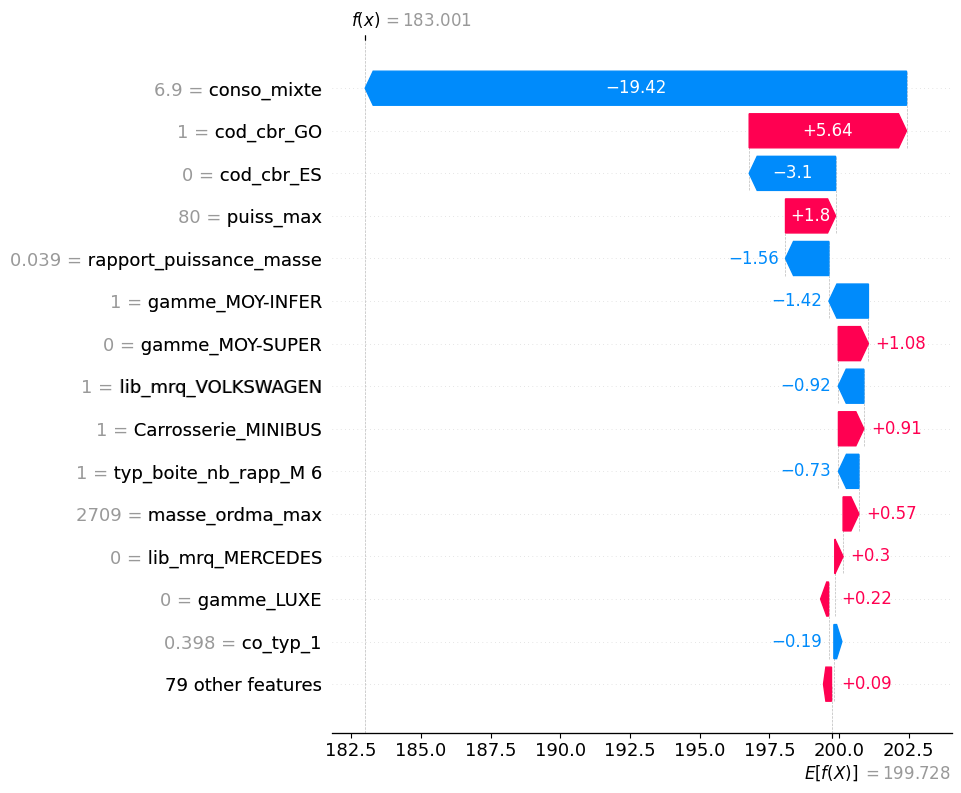

In [42]:
# ==========================================================
# SHAP - Régression linéaire
# ==========================================================


# ----------------------------------------------------------
# 1. Sélection d'un échantillon pour l'analyse SHAP
# ----------------------------------------------------------

X_test_sample = X_test.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 2. Création du jeu de référence (background)
# ----------------------------------------------------------

X_background = X_train.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 3. Construction de l'explainer SHAP
# ----------------------------------------------------------

explainer = shap.LinearExplainer(
    reg_lin,
    X_background
)

# ----------------------------------------------------------
# 4. Calcul des valeurs SHAP
# ----------------------------------------------------------

shap_values = explainer(X_test_sample)

print(
    "Dimension des valeurs SHAP :",
    shap_values.values.shape
)

# ==========================================================
# GRAPHIQUE 1 : IMPORTANCE GLOBALE DES VARIABLES
# ==========================================================

# Calcul de l'importance moyenne absolue des valeurs SHAP
importance_shap = pd.DataFrame({
    "Variable": X_test_sample.columns,
    "Importance SHAP moyenne": abs(shap_values.values).mean(axis=0)
})

display(
    importance_shap.sort_values(
        "Importance SHAP moyenne",
        ascending=False
    ).head(20)
)

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Importance des variables - Régression linéaire (SHAP)"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 2 : IMPACT DES VARIABLES SUR LES PRÉDICTIONS
# ==========================================================

shap.summary_plot(
    shap_values.values,
    X_test_sample,
    max_display=20,
    show=False
)

plt.title(
    "Impact des variables sur la prédiction du CO₂ - Régression linéaire"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 3 : EXPLICATION D'UNE PRÉDICTION INDIVIDUELLE
# ==========================================================

index = 59

print(
    "Observation analysée :",
    index
)

print(
    "Index d'origine :",
    X_test_sample.index[index]
)

# Contributions SHAP de l'observation sélectionnée
display(
    pd.DataFrame({
        "Variable": X_test_sample.columns,
        "SHAP": shap_values.values[index]
    })
    .sort_values(
        "SHAP",
        key=abs,
        ascending=False
    )
    .head(20)
)

shap.plots.waterfall(
    shap_values[index],
    max_display=15
)

### Interprétation des résultats

L'analyse SHAP apporte une interprétation complémentaire des performances de la régression linéaire en identifiant les variables qui contribuent le plus aux prédictions du modèle.

Le graphique d'importance globale montre que la consommation mixte (`conso_mixte`) constitue la variable la plus influente, avec une contribution absolue moyenne de 22,05 g/km. Les variables liées au type de carburant, notamment `cod_cbr_GO` (9,18 g/km) et `cod_cbr_ES` (4,79 g/km), occupent également une place importante dans les prédictions. D'autres caractéristiques techniques, comme la puissance maximale, le rapport puissance/masse ou la gamme du véhicule, présentent des contributions plus limitées.

Le graphique de synthèse (*summary plot*) met en évidence que les valeurs élevées de `conso_mixte` contribuent fortement à augmenter les émissions de CO₂ prédites, tandis que les faibles consommations contribuent à les diminuer. Les autres variables présentent généralement des contributions moins importantes, souvent concentrées autour de zéro. Ces résultats confirment le rôle prépondérant de la consommation mixte dans le fonctionnement du modèle.

L'explication individuelle permet d'illustrer plus précisément ces contributions. Pour l'observation étudiée (index d'origine 6887), le modèle prédit des émissions de 183,00 g/km, contre une valeur de référence SHAP de 199,73 g/km. La consommation mixte, égale à 6,9, contribue à diminuer cette prédiction de 19,42 g/km. Le carburant diesel (`cod_cbr_GO`) contribue à l'augmenter de 5,64 g/km, tandis que d'autres caractéristiques apportent des ajustements positifs ou négatifs de moindre ampleur.

Dans l'ensemble, l'analyse SHAP confirme que la régression linéaire s'appuie principalement sur la consommation mixte et, dans une moindre mesure, sur le type de carburant et certaines caractéristiques techniques des véhicules. Elle met également en évidence une forte dépendance du modèle à `conso_mixte`, variable étroitement liée aux émissions de CO₂.

Cette observation justifie l'intérêt d'expérimentations complémentaires sans les variables les plus fortement corrélées à la cible, notamment `conso_mixte`, `co_typ_1` et `nox`, afin d'évaluer la capacité des modèles à conserver de bonnes performances à partir d'autres caractéristiques des véhicules.

### Ridge

L'analyse SHAP est appliquée au modèle Ridge afin d'interpréter les variables qui influencent le plus ses prédictions. Les mêmes représentations que pour la régression linéaire sont utilisées afin de faciliter la comparaison entre les deux modèles et d'évaluer l'effet de la régularisation L2 sur l'importance des variables.

Dimension des valeurs SHAP : (1000, 93)


,Variable,Importance SHAP moyenne
1,conso_mixte,22.048106
60,cod_cbr_GO,2.167695
52,cod_cbr_ES,1.870443
75,gamme_MOY-INFER,1.655889
77,gamme_MOY-SUPER,1.522385
68,Carrosserie_MINIBUS,1.412128
7,rapport_puissance_masse,1.255641
0,puiss_max,1.250779
88,typ_boite_nb_rapp_M 6,0.764922
6,masse_ordma_max,0.460902


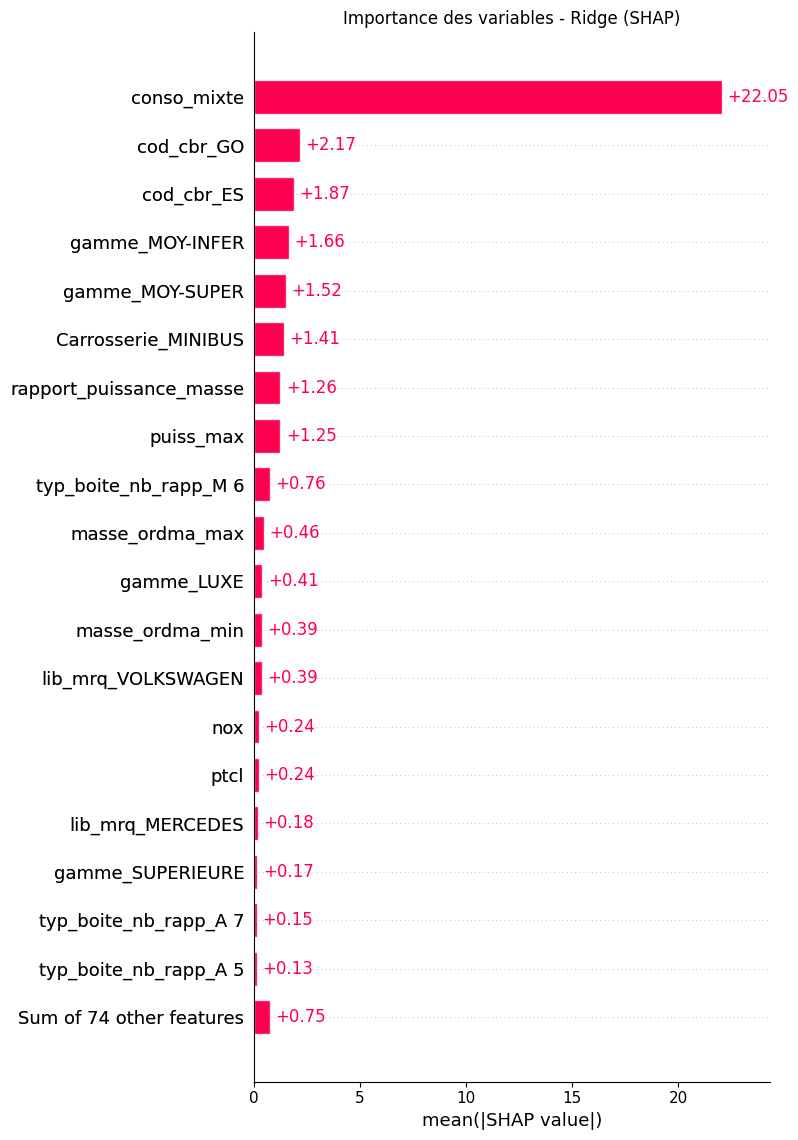

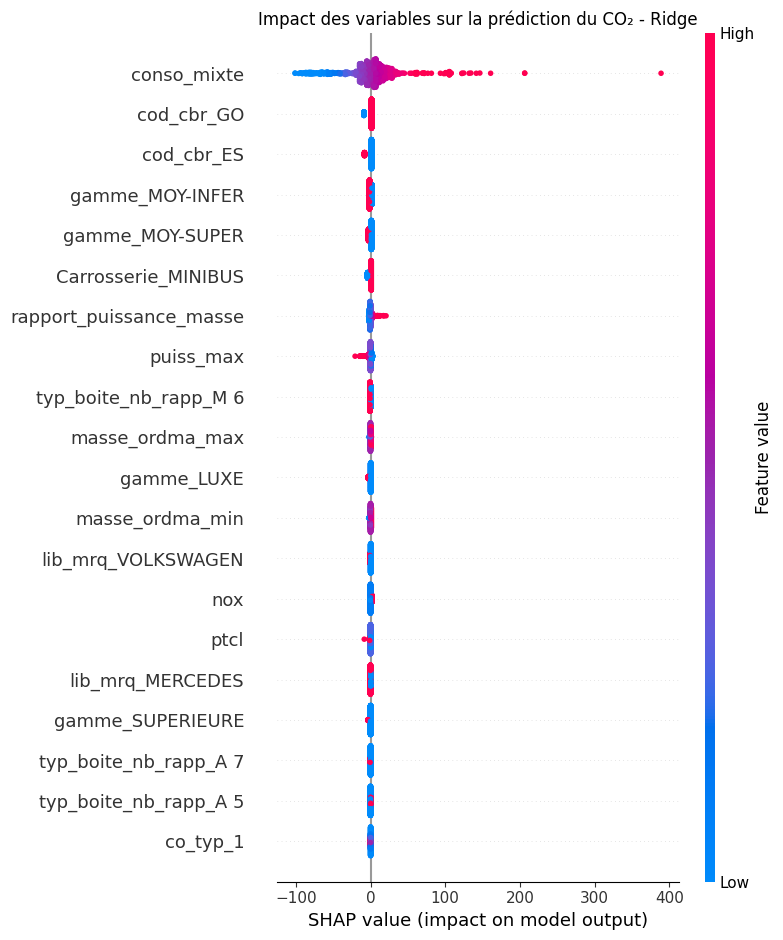

Observation analysée : 59
Index d'origine : 6887


,Variable,SHAP
1,conso_mixte,-19.415395
0,puiss_max,1.788365
7,rapport_puissance_masse,-1.549463
75,gamme_MOY-INFER,-1.407485
60,cod_cbr_GO,1.333020
52,cod_cbr_ES,1.209499
77,gamme_MOY-SUPER,1.076494
49,lib_mrq_VOLKSWAGEN,-0.918648
68,Carrosserie_MINIBUS,0.914030
88,typ_boite_nb_rapp_M 6,-0.726348


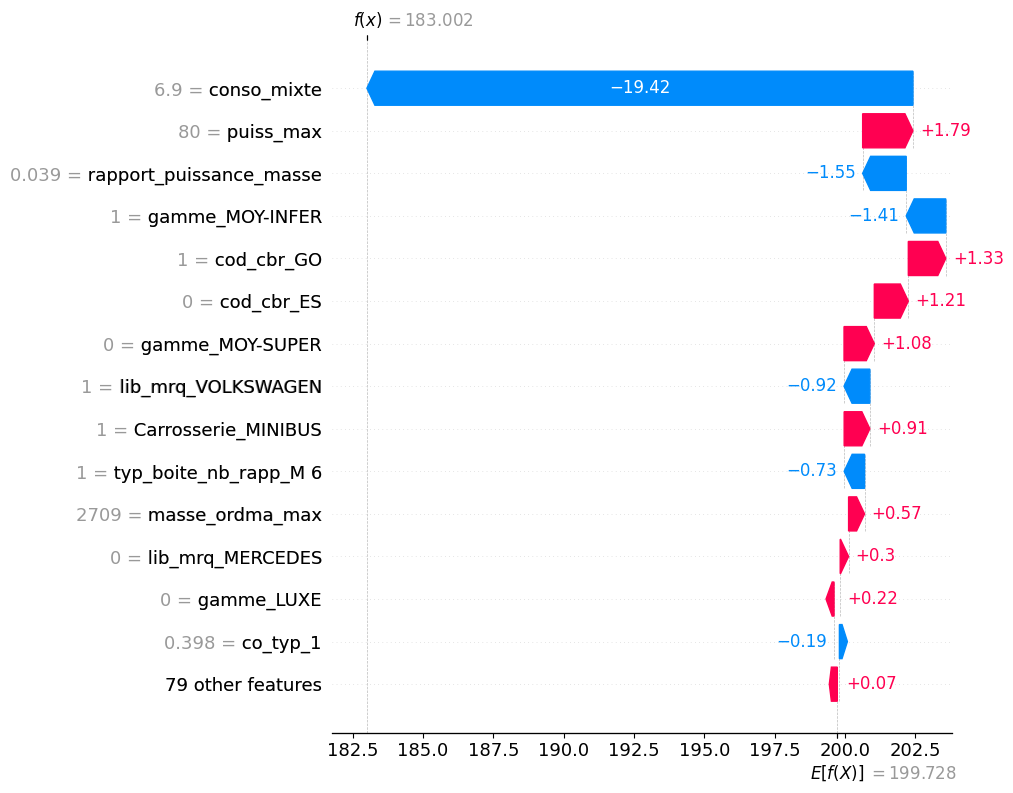

In [43]:
# ==========================================================
# SHAP - Ridge
# ==========================================================

# ----------------------------------------------------------
# 1. Sélection d'un échantillon pour l'analyse SHAP
# ----------------------------------------------------------

X_test_sample = X_test.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 2. Création du jeu de référence (background)
# ----------------------------------------------------------

X_background = X_train.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 3. Récupération du modèle Ridge et du scaler
# ----------------------------------------------------------

scaler = ridge.named_steps["scaler"]
ridge_model = ridge.named_steps["ridge"]

# Transformation des données avec le scaler entraîné
X_background_scaled = pd.DataFrame(
    scaler.transform(X_background),
    columns=X_background.columns,
    index=X_background.index
)

X_test_sample_scaled = pd.DataFrame(
    scaler.transform(X_test_sample),
    columns=X_test_sample.columns,
    index=X_test_sample.index
)

# ----------------------------------------------------------
# 4. Construction de l'explainer SHAP
# ----------------------------------------------------------

explainer_ridge = shap.LinearExplainer(
    ridge_model,
    X_background_scaled
)

# ----------------------------------------------------------
# 5. Calcul des valeurs SHAP
# ----------------------------------------------------------

shap_values_ridge = explainer_ridge(
    X_test_sample_scaled
)

# Conservation des valeurs originales pour les graphiques
shap_values_ridge.data = X_test_sample.to_numpy()

print(
    "Dimension des valeurs SHAP :",
    shap_values_ridge.values.shape
)

# ==========================================================
# GRAPHIQUE 1 : IMPORTANCE GLOBALE DES VARIABLES
# ==========================================================

importance_shap_ridge = pd.DataFrame({
    "Variable": X_test_sample.columns,
    "Importance SHAP moyenne": np.abs(
        shap_values_ridge.values
    ).mean(axis=0)
})

display(
    importance_shap_ridge.sort_values(
        "Importance SHAP moyenne",
        ascending=False
    ).head(20)
)

shap.plots.bar(
    shap_values_ridge,
    max_display=20,
    show=False
)

plt.title(
    "Importance des variables - Ridge (SHAP)"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 2 : IMPACT DES VARIABLES SUR LES PRÉDICTIONS
# ==========================================================

shap.summary_plot(
    shap_values_ridge.values,
    X_test_sample,
    max_display=20,
    show=False
)

plt.title(
    "Impact des variables sur la prédiction du CO₂ - Ridge"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 3 : EXPLICATION D'UNE PRÉDICTION INDIVIDUELLE
# ==========================================================

index = 59

print(
    "Observation analysée :",
    index
)

print(
    "Index d'origine :",
    X_test_sample.index[index]
)

display(
    pd.DataFrame({
        "Variable": X_test_sample.columns,
        "SHAP": shap_values_ridge.values[index]
    })
    .sort_values(
        "SHAP",
        key=abs,
        ascending=False
    )
    .head(20)
)

shap.plots.waterfall(
    shap_values_ridge[index],
    max_display=15
)

### Interprétation des résultats

L'analyse SHAP du modèle Ridge confirme globalement les observations obtenues avec la régression linéaire. La consommation mixte (`conso_mixte`) demeure de loin la variable la plus influente dans les prédictions, avec une importance SHAP absolue moyenne de 22,05 g/km, quasiment identique à celle observée pour la régression linéaire.

Les variables liées au type de carburant, notamment `cod_cbr_GO` (2,17 g/km) et `cod_cbr_ES` (1,87 g/km), occupent également une place importante, mais leur contribution moyenne est sensiblement inférieure à celle observée avec la régression linéaire (respectivement 9,18 et 4,79 g/km). Cette différence illustre l'effet de la régularisation L2 sur la répartition des contributions entre les variables explicatives.

Le graphique de synthèse (*summary plot*) montre que les valeurs élevées de `conso_mixte` contribuent fortement à augmenter les émissions de CO₂ prédites, tandis que les faibles consommations contribuent à les diminuer. Les autres variables présentent généralement des contributions plus limitées, majoritairement concentrées autour de zéro. La consommation mixte conserve ainsi un rôle prépondérant dans le fonctionnement du modèle.

L'explication individuelle confirme cette hiérarchie. Pour l'observation étudiée (index d'origine 6887), le modèle Ridge prédit des émissions de 183,00 g/km, contre une valeur de référence SHAP de 199,73 g/km. La consommation mixte, égale à 6,9, contribue à diminuer cette prédiction de 19,42 g/km. La puissance maximale contribue à l'augmenter de 1,79 g/km, tandis que les variables liées au carburant diesel et à l'essence apportent respectivement des contributions positives de 1,33 et 1,21 g/km.

La comparaison avec la régression linéaire montre que les deux modèles produisent des prédictions quasiment identiques pour cette observation, malgré des différences dans la répartition des contributions de certaines variables. Cette observation est cohérente avec leurs performances prédictives très proches (R² = 0,9974 pour les deux modèles).

Dans l'ensemble, l'analyse SHAP montre que la régularisation L2 ne modifie pas fondamentalement la hiérarchie des variables explicatives. Elle influence toutefois la contribution attribuée à certaines caractéristiques, particulièrement celles liées au type de carburant. Le modèle Ridge reste fortement dépendant de `conso_mixte`, ce qui renforce l'intérêt d'expérimentations complémentaires sans cette variable, ainsi que sans `co_typ_1` et `nox`, afin d'évaluer la robustesse des prédictions à partir des autres caractéristiques techniques des véhicules.

### Lasso

L'analyse SHAP est réalisée sur le modèle Lasso afin d'étudier l'influence de la régularisation L1 sur les contributions des variables explicatives. Les résultats sont comparés à ceux obtenus avec les modèles linéaires précédents.

Dimension des valeurs SHAP : (1000, 93)


,Variable,Importance SHAP moyenne
1,conso_mixte,2.069816e+01
60,cod_cbr_GO,2.909467e+00
68,Carrosserie_MINIBUS,1.737980e+00
5,masse_ordma_min,7.284083e-01
79,typ_boite_nb_rapp_A 5,2.392783e-01
61,cod_cbr_GP/ES,7.332421e-03
58,cod_cbr_GN,4.834362e-03
59,cod_cbr_GN/ES,1.001005e-17
55,cod_cbr_FE,4.973706e-18
4,ptcl,0.000000e+00


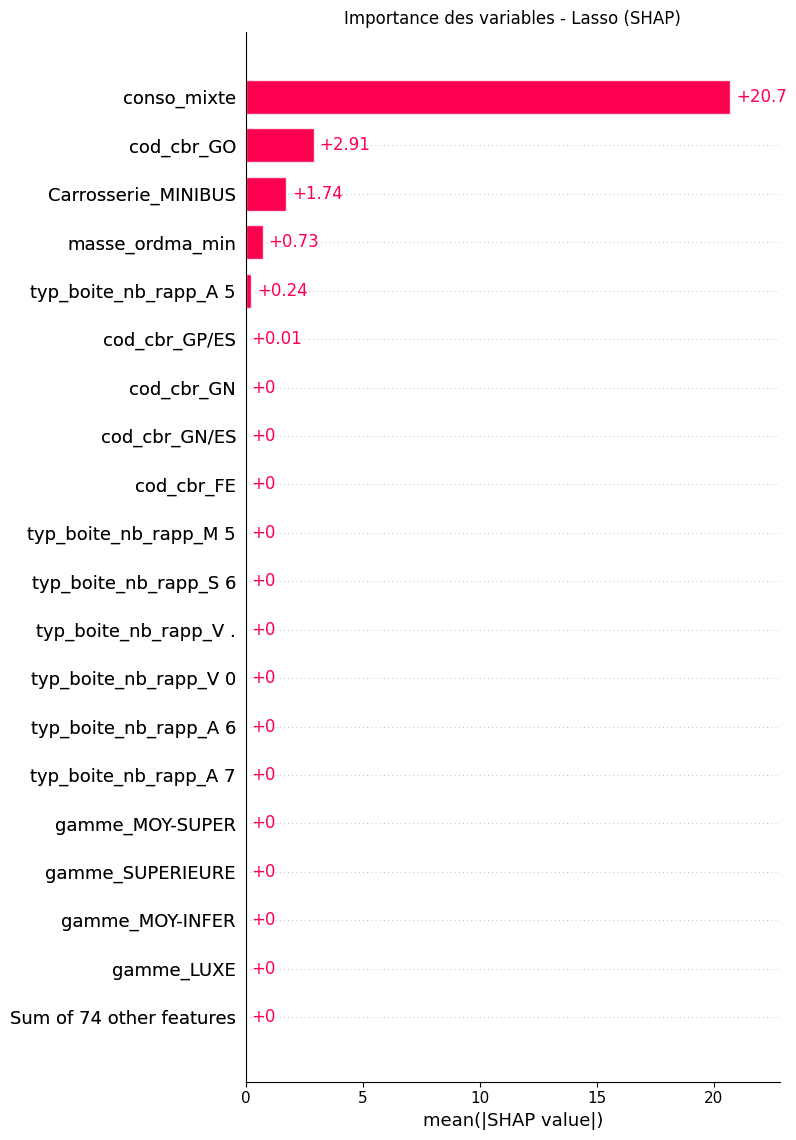

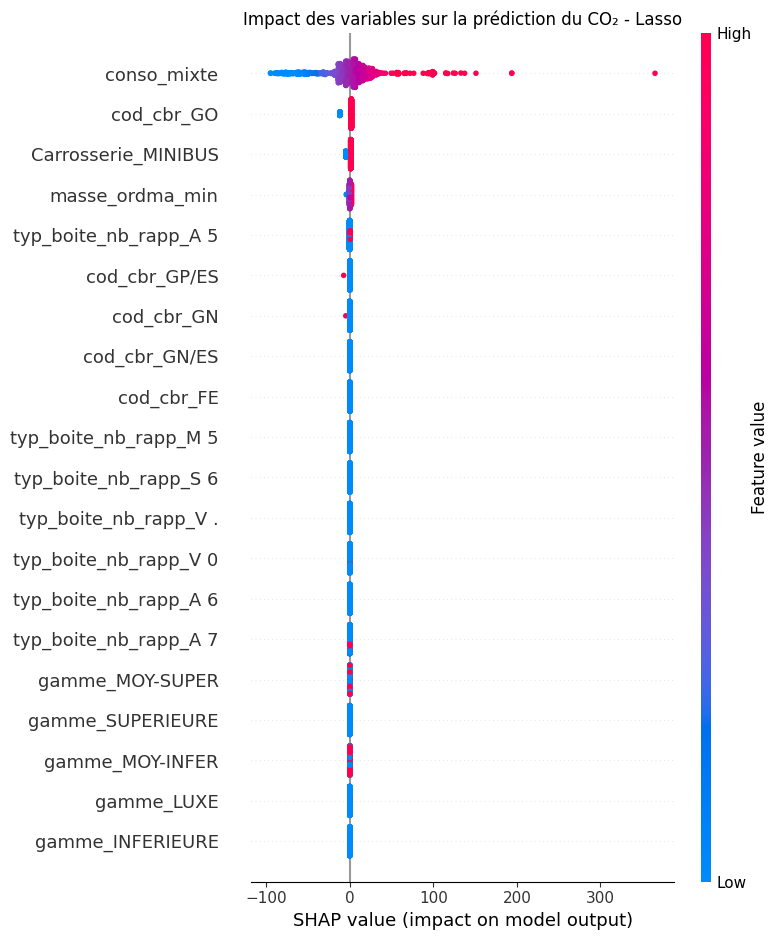

Observation analysée : 59
Index d'origine : 6887


,Variable,SHAP
1,conso_mixte,-1.822664e+01
60,cod_cbr_GO,1.789171e+00
68,Carrosserie_MINIBUS,1.124945e+00
79,typ_boite_nb_rapp_A 5,-1.833233e-01
5,masse_ordma_min,-5.991517e-02
59,cod_cbr_GN/ES,-1.001005e-17
55,cod_cbr_FE,4.973706e-18
61,cod_cbr_GP/ES,4.228092e-18
58,cod_cbr_GN,-3.296126e-18
4,ptcl,0.000000e+00


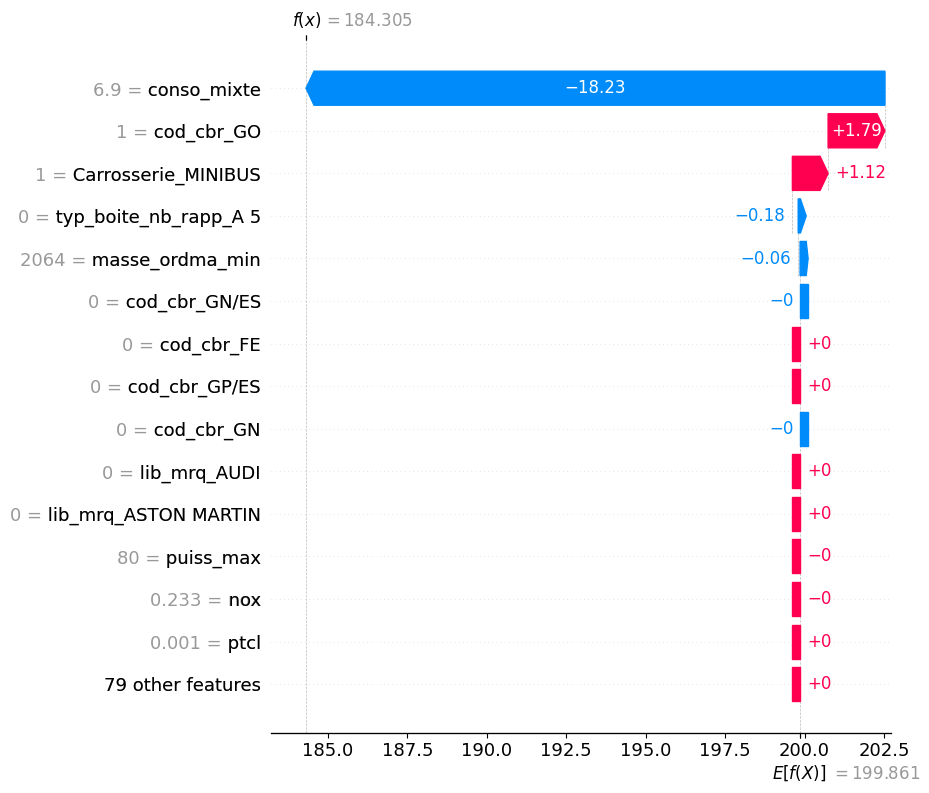

In [44]:
# ==========================================================
# SHAP - Lasso
# ==========================================================


# ----------------------------------------------------------
# 1. Sélection d'un échantillon pour l'analyse SHAP
# ----------------------------------------------------------

X_test_sample = X_test.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 2. Création du jeu de référence (background)
# ----------------------------------------------------------

X_background = X_train.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 3. Récupération du modèle Lasso et du scaler
# ----------------------------------------------------------

# Récupération des étapes du pipeline entraîné
scaler_lasso = lasso.named_steps["scaler"]
lasso_model = lasso.named_steps["lasso"]

# Transformation du jeu de référence
X_background_scaled = pd.DataFrame(
    scaler_lasso.transform(X_background),
    columns=X_background.columns,
    index=X_background.index
)

# Transformation des observations à expliquer
X_test_sample_scaled = pd.DataFrame(
    scaler_lasso.transform(X_test_sample),
    columns=X_test_sample.columns,
    index=X_test_sample.index
)

# ----------------------------------------------------------
# 4. Construction de l'explainer SHAP
# ----------------------------------------------------------

explainer_lasso = shap.LinearExplainer(
    lasso_model,
    X_background_scaled
)

# ----------------------------------------------------------
# 5. Calcul des valeurs SHAP
# ----------------------------------------------------------

shap_values_lasso = explainer_lasso(
    X_test_sample_scaled
)

# Conservation des valeurs originales pour les graphiques
shap_values_lasso.data = X_test_sample.to_numpy()

print(
    "Dimension des valeurs SHAP :",
    shap_values_lasso.values.shape
)

# ==========================================================
# GRAPHIQUE 1 : IMPORTANCE GLOBALE DES VARIABLES
# ==========================================================

importance_shap_lasso = pd.DataFrame({
    "Variable": X_test_sample.columns,
    "Importance SHAP moyenne": np.abs(
        shap_values_lasso.values
    ).mean(axis=0)
})

display(
    importance_shap_lasso.sort_values(
        "Importance SHAP moyenne",
        ascending=False
    ).head(20)
)

shap.plots.bar(
    shap_values_lasso,
    max_display=20,
    show=False
)

plt.title(
    "Importance des variables - Lasso (SHAP)"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 2 : IMPACT DES VARIABLES SUR LES PRÉDICTIONS
# ==========================================================

shap.summary_plot(
    shap_values_lasso.values,
    X_test_sample,
    max_display=20,
    show=False
)

plt.title(
    "Impact des variables sur la prédiction du CO₂ - Lasso"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 3 : EXPLICATION D'UNE PRÉDICTION INDIVIDUELLE
# ==========================================================

index = 59

print(
    "Observation analysée :",
    index
)

print(
    "Index d'origine :",
    X_test_sample.index[index]
)

# Contributions SHAP de l'observation sélectionnée
display(
    pd.DataFrame({
        "Variable": X_test_sample.columns,
        "SHAP": shap_values_lasso.values[index]
    })
    .sort_values(
        "SHAP",
        key=abs,
        ascending=False
    )
    .head(20)
)

shap.plots.waterfall(
    shap_values_lasso[index],
    max_display=15
)

### Interprétation des résultats

L'analyse SHAP du modèle Lasso met en évidence un fonctionnement sensiblement différent de celui des modèles de régression linéaire et Ridge. La consommation mixte (`conso_mixte`) reste la variable la plus influente dans les prédictions, mais le nombre de variables contribuant réellement au modèle est nettement plus réduit.

Le graphique d'importance globale montre que `conso_mixte` domine largement les prédictions, avec une importance SHAP absolue moyenne de 20,70 g/km. Les autres variables présentant les contributions les plus importantes sont `cod_cbr_GO` (2,91 g/km), `Carrosserie_MINIBUS` (1,74 g/km) et `masse_ordma_min` (0,73 g/km). À l'inverse, de nombreuses caractéristiques, notamment `puiss_max`, `nox` et `co_typ_1`, présentent une contribution nulle, traduisant l'effet de la régularisation L1, qui peut annuler les coefficients de certaines variables explicatives.

Le graphique de synthèse (*summary plot*) confirme cette simplification du modèle. Les valeurs élevées de `conso_mixte` contribuent fortement à augmenter les émissions de CO₂ prédites, tandis que les faibles consommations contribuent à les diminuer. Les autres variables exercent une influence beaucoup plus limitée. La majorité des caractéristiques restantes présente des contributions nulles ou quasiment nulles, ce qui montre qu'elles interviennent peu ou pas dans les prédictions.

L'explication individuelle illustre également ce comportement. Pour l'observation étudiée (index d'origine 6887), le modèle Lasso prédit des émissions de 184,31 g/km, contre une valeur de référence SHAP de 199,86 g/km. La consommation mixte, égale à 6,9, contribue à diminuer cette prédiction de 18,23 g/km. Le carburant diesel (`cod_cbr_GO`) et la carrosserie de type minibus contribuent respectivement à l'augmenter de 1,79 et 1,12 g/km. Les autres variables apportent des ajustements très faibles, voire nuls.

La comparaison avec les modèles précédents met en évidence l'effet de la régularisation L1. Alors que la régression linéaire et Ridge répartissent leurs contributions entre un plus grand nombre de caractéristiques, Lasso concentre les prédictions sur quelques variables principales. Cette simplification améliore la lisibilité du modèle, mais s'accompagne d'une diminution des performances prédictives, avec un R² de 0,9923 et un RMSE de 3,01 g/km, contre un R² de 0,9974 et un RMSE de 1,74 g/km pour les deux autres modèles linéaires.

Dans l'ensemble, l'analyse SHAP confirme que la régularisation L1 permet de réduire fortement la complexité du modèle en sélectionnant un nombre limité de variables explicatives. La consommation mixte demeure toutefois largement dominante, ce qui souligne la dépendance persistante du modèle à cette caractéristique et renforce l'intérêt des expérimentations complémentaires visant à évaluer les performances sans les variables les plus fortement liées aux émissions de CO₂.

### Arbre de décision

L'analyse SHAP est appliquée à l'Arbre de décision afin d'identifier les variables les plus influentes dans les prédictions et de comparer leur importance avec celles observées pour les modèles linéaires.

Dimension des valeurs SHAP : (1000, 93)


,Variable,Importance SHAP moyenne
1,conso_mixte,22.760145
3,nox,1.343091
60,cod_cbr_GO,1.104210
6,masse_ordma_max,0.419028
0,puiss_max,0.277645
52,cod_cbr_ES,0.198718
2,co_typ_1,0.144155
68,Carrosserie_MINIBUS,0.094069
5,masse_ordma_min,0.083919
7,rapport_puissance_masse,0.081332


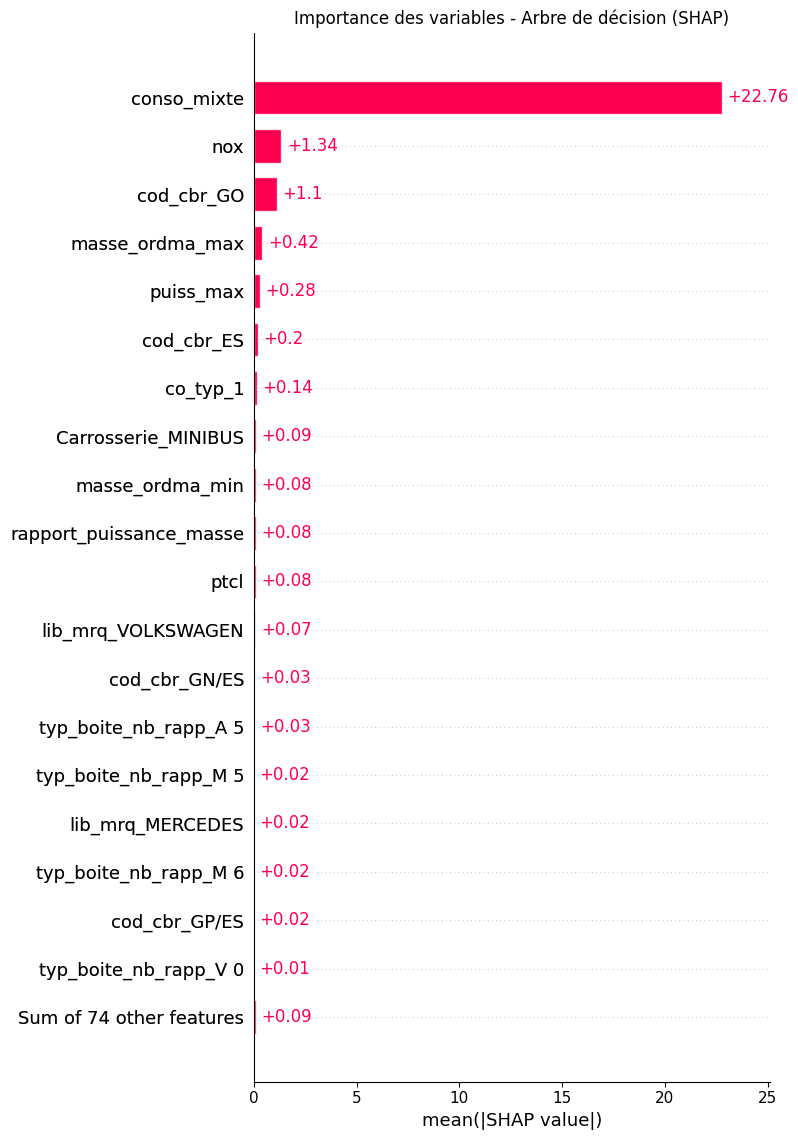

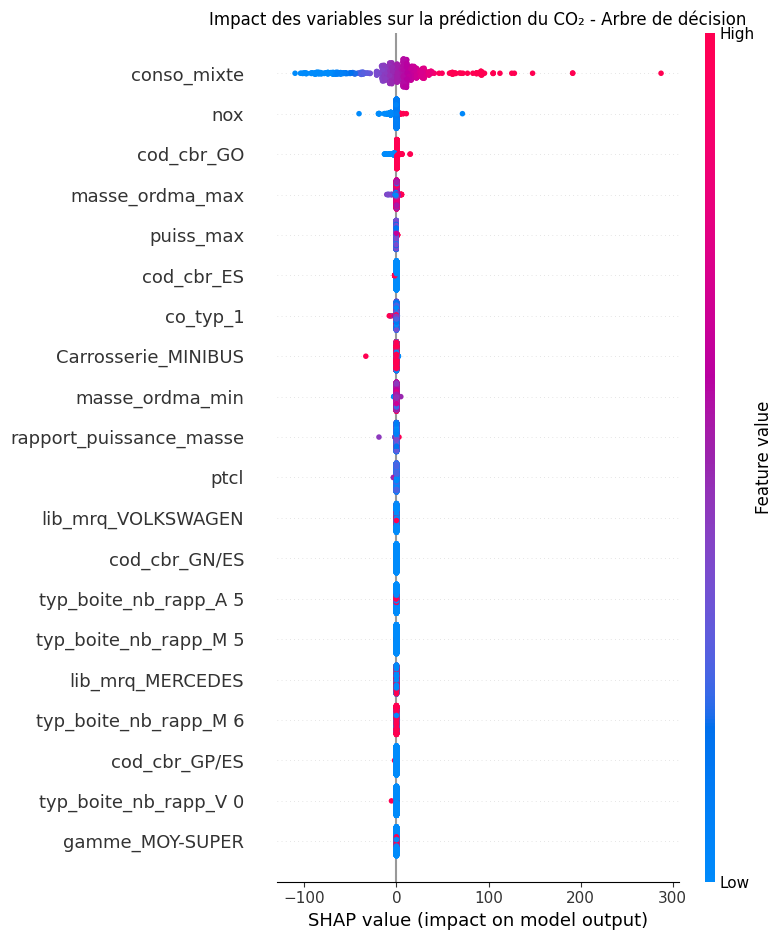

Observation analysée : 59
Index d'origine : 6887


,Variable,SHAP
1,conso_mixte,-21.390886
60,cod_cbr_GO,0.912280
0,puiss_max,-0.258472
2,co_typ_1,-0.124677
6,masse_ordma_max,0.119263
68,Carrosserie_MINIBUS,-0.062767
3,nox,0.032410
33,lib_mrq_MERCEDES,-0.019339
52,cod_cbr_ES,0.015393
59,cod_cbr_GN/ES,0.009057


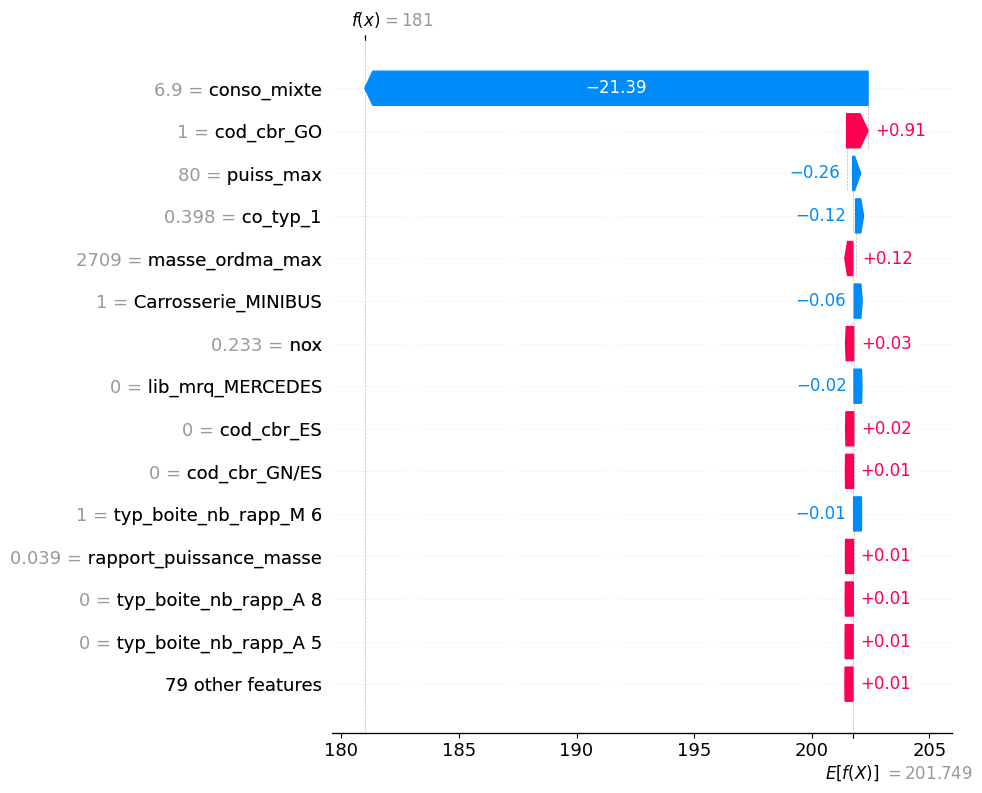

In [45]:
# ==========================================================
# SHAP - Arbre de décision
# ==========================================================


# ----------------------------------------------------------
# 1. Sélection d'un échantillon pour l'analyse SHAP
# ----------------------------------------------------------

X_test_sample = X_test.sample(
    n=1000,
    random_state=42
)

# ----------------------------------------------------------
# 2. Création de l'explainer SHAP
# ----------------------------------------------------------

explainer_tree = shap.TreeExplainer(
    tree
)

# ----------------------------------------------------------
# 3. Calcul des valeurs SHAP
# ----------------------------------------------------------

shap_values_tree = explainer_tree(
    X_test_sample
)

print(
    "Dimension des valeurs SHAP :",
    shap_values_tree.values.shape
)

# ==========================================================
# GRAPHIQUE 1 : IMPORTANCE GLOBALE DES VARIABLES
# ==========================================================

# Calcul de l'importance SHAP absolue moyenne
importance_shap_tree = pd.DataFrame({
    "Variable": X_test_sample.columns,
    "Importance SHAP moyenne": np.abs(
        shap_values_tree.values
    ).mean(axis=0)
})

# Affichage des 20 variables les plus importantes
display(
    importance_shap_tree.sort_values(
        "Importance SHAP moyenne",
        ascending=False
    ).head(20)
)

# Graphique d'importance globale
shap.plots.bar(
    shap_values_tree,
    max_display=20,
    show=False
)

plt.title(
    "Importance des variables - Arbre de décision (SHAP)"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 2 : IMPACT DES VARIABLES SUR LES PRÉDICTIONS
# ==========================================================

shap.summary_plot(
    shap_values_tree.values,
    X_test_sample,
    max_display=20,
    show=False
)

plt.title(
    "Impact des variables sur la prédiction du CO₂ - Arbre de décision"
)

plt.tight_layout()
plt.show()

# ==========================================================
# GRAPHIQUE 3 : EXPLICATION D'UNE PRÉDICTION INDIVIDUELLE
# ==========================================================

index = 59

print(
    "Observation analysée :",
    index
)

print(
    "Index d'origine :",
    X_test_sample.index[index]
)

# Contributions SHAP de l'observation sélectionnée
display(
    pd.DataFrame({
        "Variable": X_test_sample.columns,
        "SHAP": shap_values_tree.values[index]
    })
    .sort_values(
        "SHAP",
        key=abs,
        ascending=False
    )
    .head(20)
)

# Graphique Waterfall
shap.plots.waterfall(
    shap_values_tree[index],
    max_display=15
)

### Interprétation des résultats

L'analyse SHAP du modèle Arbre de décision montre que la consommation mixte (`conso_mixte`) reste, de très loin, la variable la plus influente dans les prédictions des émissions de CO₂. Avec une importance SHAP absolue moyenne de 22,76 g/km, sa contribution dépasse largement celle des autres caractéristiques, ce qui confirme les observations réalisées avec les modèles précédents.

Le graphique d'importance globale met également en évidence le rôle de certaines variables complémentaires, notamment `nox` (1,34 g/km), `cod_cbr_GO` (1,10 g/km), `masse_ordma_max` (0,42 g/km), `puiss_max` (0,28 g/km) et `co_typ_1` (0,14 g/km). Ces contributions restent nettement inférieures à celle de la consommation mixte, mais montrent que l'Arbre de décision exploite également d'autres caractéristiques techniques des véhicules.

Le graphique de synthèse (*summary plot*) confirme que les valeurs élevées de `conso_mixte` contribuent fortement à augmenter les émissions de CO₂ prédites, tandis que les faibles consommations contribuent à les diminuer. Les autres variables présentent des contributions plus localisées, qui varient selon les caractéristiques des véhicules. Cette répartition est cohérente avec le fonctionnement non linéaire de l'Arbre de décision, qui combine différentes règles de séparation pour produire ses prédictions.

L'explication individuelle illustre ce fonctionnement. Pour l'observation étudiée (index d'origine 6887), le modèle prédit des émissions de 181,00 g/km, contre une valeur de référence SHAP de 201,75 g/km. La consommation mixte, égale à 6,9, contribue à diminuer cette prédiction de 21,39 g/km. Le carburant diesel (`cod_cbr_GO`) contribue à l'augmenter de 0,91 g/km, tandis que la puissance maximale (`puiss_max`) et `co_typ_1` contribuent respectivement à la diminuer de 0,26 et 0,12 g/km. Les autres caractéristiques apportent des ajustements plus limités.

La comparaison avec les modèles linéaires montre que l'Arbre de décision mobilise différemment les variables explicatives. Alors que la régression linéaire et Ridge accordent une importance notable à certaines catégories de carburant, l'Arbre de décision fait davantage intervenir `nox` et certaines caractéristiques techniques, tout en conservant une forte dépendance à la consommation mixte.

Dans l'ensemble, l'analyse SHAP confirme que l'Arbre de décision exploite plusieurs caractéristiques des véhicules, mais que ses prédictions restent principalement déterminées par `conso_mixte`. Ces résultats sont cohérents avec les excellentes performances obtenues lors de l'évaluation du modèle (R² = 0,9991, RMSE = 1,04 g/km).

La prédominance de la consommation mixte souligne néanmoins l'intérêt d'expérimentations complémentaires sans les variables les plus fortement liées aux émissions de CO₂, notamment `conso_mixte`, `co_typ_1` et `nox`, afin d'évaluer la capacité du modèle à maintenir de bonnes performances à partir d'autres caractéristiques techniques.

## Synthèse des analyses SHAP

L'analyse d'interprétabilité réalisée à l'aide de SHAP confirme les principaux enseignements obtenus lors de l'analyse exploratoire et de l'évaluation des modèles. Réalisée sur un échantillon commun de 1 000 observations du jeu de test et sur les 93 variables explicatives issues du prétraitement, elle permet de comparer les contributions des caractéristiques techniques aux prédictions des quatre modèles étudiés.

Quel que soit le modèle, la consommation mixte (`conso_mixte`) apparaît systématiquement comme la variable la plus influente dans la prédiction des émissions de CO₂. Son importance SHAP absolue moyenne varie de 20,70 g/km pour Lasso à 22,76 g/km pour l'Arbre de décision. Cette prédominance confirme la relation particulièrement forte entre la consommation de carburant et les émissions de CO₂, déjà mise en évidence lors de l'analyse exploratoire.

La régression linéaire et Ridge présentent des comportements globalement proches, avec des performances prédictives quasiment identiques et une importance comparable accordée à `conso_mixte`. La régularisation L2 modifie toutefois la répartition des contributions entre certaines variables, notamment celles liées au type de carburant. Leur importance SHAP diminue sensiblement avec Ridge, sans entraîner de modification notable des performances globales du modèle.

À l'inverse, le modèle Lasso sélectionne automatiquement un nombre plus restreint de variables explicatives. Les prédictions reposent principalement sur `conso_mixte`, `cod_cbr_GO`, `Carrosserie_MINIBUS` et `masse_ordma_min`, tandis que de nombreuses autres caractéristiques présentent une contribution nulle. Cette simplification illustre l'effet de la régularisation L1, qui favorise un modèle plus parcimonieux et plus facilement interprétable, au prix d'une légère diminution des performances prédictives.

L'Arbre de décision exploite également plusieurs caractéristiques techniques et met en évidence des contributions liées notamment à `nox`, `cod_cbr_GO`, `masse_ordma_max` et `puiss_max`. Son fonctionnement permet de prendre en compte des relations non linéaires et des interactions entre les variables explicatives. Malgré cette capacité supplémentaire, `conso_mixte` demeure très largement dominante dans ses prédictions.

Les explications individuelles réalisées sur une même observation confirment cette cohérence entre les modèles. Les prédictions obtenues restent proches, comprises entre 181,00 et 184,31 g/km, mais les contributions attribuées aux différentes caractéristiques varient selon l'algorithme. Cette comparaison illustre l'intérêt de SHAP pour comprendre non seulement les variables mobilisées par chaque modèle, mais également leur influence sur une prédiction particulière.

Dans l'ensemble, les analyses SHAP mettent en évidence une forte cohérence entre les modèles étudiés et confirment que leurs excellentes performances reposent principalement sur la présence de variables très fortement liées à la cible, en particulier `conso_mixte`. Cette dépendance constitue un point de vigilance, notamment concernant la disponibilité de cette information au moment de la prédiction et le risque potentiel de fuite d'information.

Ces résultats renforcent l'intérêt des expérimentations complémentaires visant à évaluer les performances des modèles après suppression de `conso_mixte`, `co_typ_1` et `nox`. L'objectif est de déterminer dans quelle mesure les autres caractéristiques techniques des véhicules permettent de conserver une bonne qualité de prédiction et d'apprécier la robustesse des modèles dans un contexte où ces variables ne seraient pas disponibles.

## Optimisation des modèles

## Introduction

L'objectif de cette étape est d'améliorer les performances des modèles de régression en recherchant les combinaisons d'hyperparamètres les plus adaptées à notre jeu de données.

Contrairement aux paramètres appris lors de l'entraînement (coefficients de régression ou règles de séparation d'un arbre), les hyperparamètres sont définis avant l'apprentissage et influencent directement le comportement des algorithmes.

Pour cette étude, l'optimisation est réalisée à l'aide de `GridSearchCV`, une méthode de recherche exhaustive qui évalue différentes combinaisons d'hyperparamètres au moyen d'une validation croisée (*cross-validation*). Cette approche permet de sélectionner la meilleure configuration parmi celles testées, tout en estimant sa capacité de généralisation.

Les performances des modèles optimisés seront ensuite comparées à celles obtenues avec les configurations initiales, sur le même jeu de test, afin d'évaluer l'apport réel de cette étape.

## Choix de la méthode d'optimisation

Dans cette étude, `GridSearchCV` a été privilégié à `RandomizedSearchCV`.

Le nombre d'hyperparamètres à optimiser reste limité pour les modèles étudiés, ce qui permet d'explorer de manière exhaustive les combinaisons définies dans les grilles de recherche.

Cette approche garantit l'identification de la meilleure configuration parmi les valeurs testées, sans garantir qu'il s'agisse de l'optimum global de l'algorithme.

La validation croisée est réalisée uniquement sur les données d'entraînement, afin de préserver le jeu de test pour l'évaluation finale des modèles optimisés.

## Optimisation de Ridge avec GridSearchCV

La régression Ridge possède un hyperparamètre essentiel, `alpha`, qui contrôle l'intensité de la régularisation L2. Une valeur faible limite l'effet de la pénalisation, tandis qu'une valeur élevée contraint davantage les coefficients du modèle.

L'objectif de cette étape est d'identifier la valeur de `alpha` offrant les meilleures performances parmi celles proposées dans la grille de recherche, à l'aide de `GridSearchCV`.

L'optimisation est réalisée en conservant le pipeline comprenant la standardisation des variables et le modèle Ridge, afin d'appliquer correctement les transformations à chaque étape de la validation croisée.

### Définition de la grille de recherche

In [46]:
# ==========================================================
# Grille des hyperparamètres - Ridge
# ==========================================================

param_grid_ridge = {
    "ridge__alpha": [
        0.0001,
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

param_grid_ridge

{'ridge__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]}

### Création de GridSearchCV

In [47]:
# ==========================================================
# Création de GridSearchCV - Ridge
# ==========================================================

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

grid_ridge = GridSearchCV(
    estimator=clone(ridge),
    param_grid=param_grid_ridge,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

### Entraînement

In [48]:
# ==========================================================
# Entraînement - GridSearchCV Ridge
# ==========================================================

grid_ridge.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,estimator,"Pipeline(step...e', Ridge())])"
,param_grid,"{'ridge__alpha': [0.0001, 0.001, ...]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


### Meilleurs hyperparamètres

In [49]:
# ==========================================================
# Meilleurs hyperparamètres - Ridge
# ==========================================================

print("Meilleurs hyperparamètres :")
print(grid_ridge.best_params_)

print("\nMeilleur score moyen (validation croisée) :")
print(f"R² = {grid_ridge.best_score_:.4f}")

print("\nMeilleur modèle :")
print(grid_ridge.best_estimator_)

Meilleurs hyperparamètres :
{'ridge__alpha': 1}

Meilleur score moyen (validation croisée) :
R² = 0.9971

Meilleur modèle :
Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=1))])


Le meilleur hyperparamètre identifié par GridSearchCV est `alpha = 1`. Cette valeur correspond à une régularisation L2 modérée, permettant de limiter l'amplitude des coefficients du modèle tout en conservant d'excellentes performances prédictives.

Le score moyen obtenu en validation croisée (R² = 0,9971) confirme la très bonne capacité de généralisation estimée du modèle Ridge. Ce résultat montre que la configuration sélectionnée permet d'expliquer environ 99,71 % de la variabilité des émissions de CO₂ sur les plis de validation.

Il convient toutefois de noter que la valeur optimale d'`alpha` correspond à celle déjà utilisée dans le modèle Ridge initial. L'optimisation ne conduit donc pas à modifier sa configuration, ce qui suggère que le choix initial de cet hyperparamètre était déjà adapté au jeu de données.

L'évaluation du modèle optimisé sur le jeu de test permettra de confirmer si cette configuration conserve les performances observées précédemment.

### Création du modèle optimisé

In [50]:
# ==========================================================
# Création du modèle optimisé - Ridge
# ==========================================================

# Récupération du meilleur pipeline trouvé par GridSearchCV
ridge_optimise = grid_ridge.best_estimator_

# Affichage du modèle optimisé
print(ridge_optimise)

Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=1))])


### Prédictions

In [51]:
# ==========================================================
# Prédictions - Ridge optimisé
# ==========================================================

y_pred_ridge_opt = ridge_optimise.predict(X_test)

### Évaluation

In [52]:
# ==========================================================
# Évaluation - Ridge optimisé
# ==========================================================

mae_ridge_opt = mean_absolute_error(y_test, y_pred_ridge_opt)

rmse_ridge_opt = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge_opt)
)

r2_ridge_opt = r2_score(y_test, y_pred_ridge_opt)

mape_ridge_opt = mean_absolute_percentage_error(
    y_test, y_pred_ridge_opt
)

print(f"MAE  : {mae_ridge_opt:.2f}")
print(f"RMSE : {rmse_ridge_opt:.2f}")
print(f"R²   : {r2_ridge_opt:.4f}")
print(f"MAPE : {mape_ridge_opt:.4f}")

MAE  : 1.09
RMSE : 1.74
R²   : 0.9974
MAPE : 0.0060


L'optimisation de la régression Ridge par `GridSearchCV` identifie une valeur optimale de `alpha = 1`, identique à celle utilisée dans le modèle initial. Le meilleur score moyen obtenu en validation croisée atteint un R² de 0,9971, confirmant les très bonnes performances du modèle sur les différents plis d'entraînement et de validation.

L'évaluation du modèle optimisé sur le jeu de test montre des performances identiques à celles obtenues avant optimisation, avec une MAE de 1,09 g/km, une RMSE de 1,74 g/km, un R² de 0,9974 et une MAPE de 0,0060.

Ces résultats indiquent que la configuration initiale du modèle Ridge était déjà adaptée au jeu de données. La recherche d'hyperparamètres n'a donc pas permis d'améliorer les performances prédictives, mais elle a confirmé la pertinence du choix initial de `alpha` parmi les valeurs testées.

Dans ce contexte, l'optimisation ne présente pas de gain supplémentaire pour Ridge. Le modèle conserve néanmoins d'excellentes performances et constitue une référence pertinente pour la comparaison avec les autres algorithmes de régression.

### Comparaison avant / après optimisation

In [53]:
# ==========================================================
# Comparaison avant / après optimisation - Ridge
# ==========================================================

comparaison_ridge = pd.DataFrame({
    "Version": [
        "Ridge (par défaut)",
        "Ridge optimisé"
    ],
    "Alpha": [
        ridge.named_steps["ridge"].alpha,
        grid_ridge.best_params_["ridge__alpha"]
    ],
    "MAE": [
        mae_ridge,
        mae_ridge_opt
    ],
    "RMSE": [
        rmse_ridge,
        rmse_ridge_opt
    ],
    "R²": [
        r2_ridge,
        r2_ridge_opt
    ],
    "MAPE": [
        mape_ridge,
        mape_ridge_opt
    ]
})

display(comparaison_ridge.round(4))

,Version,Alpha,MAE,RMSE,R²,MAPE
0,Ridge (par défaut),1.0,1.0925,1.7401,0.9974,0.006
1,Ridge optimisé,1.0,1.0925,1.7401,0.9974,0.006


La comparaison des performances avant et après optimisation montre que `GridSearchCV` a sélectionné une valeur optimale de `alpha = 1`, identique à celle utilisée dans le modèle Ridge initial.

Les deux configurations obtiennent exactement les mêmes performances sur le jeu de test, avec une MAE de 1,0925 g/km, une RMSE de 1,7401 g/km, un R² de 0,9974 et une MAPE de 0,0060.

Ces résultats montrent que l'optimisation des hyperparamètres n'a pas permis d'améliorer les performances prédictives du modèle Ridge. La configuration initiale était déjà la meilleure parmi les valeurs d'`alpha` évaluées lors de la recherche.

L'optimisation a néanmoins permis de confirmer la pertinence du choix initial de `alpha = 1`, en s'appuyant sur une recherche systématique et une validation croisée à cinq plis.

Dans l'ensemble, le modèle Ridge conserve d'excellentes performances, mais aucune amélioration supplémentaire n'a été observée à l'issue de cette étape d'optimisation.

## Optimisation de Lasso avec GridSearchCV

### Introduction

La régression Lasso possède également un hyperparamètre essentiel, alpha, qui contrôle l'intensité de la pénalisation L1 appliquée aux coefficients du modèle. Cette régularisation favorise la sélection automatique des variables en annulant les coefficients les moins importants lorsque la pénalisation augmente.

L'objectif de cette étape est d'identifier la valeur d'alpha offrant les meilleures performances à l'aide de GridSearchCV, puis de comparer le modèle optimisé au modèle entraîné avec les paramètres initiaux.

### Définition de la grille

In [54]:
# ==========================================================
# Grille des hyperparamètres - Lasso
# ==========================================================

param_grid_lasso = {
    "lasso__alpha": [
        0.0001,
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

param_grid_lasso

{'lasso__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]}

### Création de GridSearchCV

In [55]:
# ==========================================================
# Création de GridSearchCV - Lasso
# ==========================================================

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

grid_lasso = GridSearchCV(
    estimator=clone(lasso),
    param_grid=param_grid_lasso,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

### Entraînement

In [56]:
# ==========================================================
# Entraînement - GridSearchCV Lasso
# ==========================================================

grid_lasso.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,estimator,Pipeline(step...iter=10000))])
,param_grid,"{'lasso__alpha': [0.0001, 0.001, ...]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


### Meilleurs hyperparamètres

In [57]:
# ==========================================================
# Meilleurs hyperparamètres - Lasso
# ==========================================================

print("Meilleurs hyperparamètres :")
print(grid_lasso.best_params_)

print("\nMeilleur score moyen (validation croisée) :")
print(f"R² = {grid_lasso.best_score_:.4f}")

print("\nMeilleur modèle :")
print(grid_lasso.best_estimator_)

Meilleurs hyperparamètres :
{'lasso__alpha': 0.0001}

Meilleur score moyen (validation croisée) :
R² = 0.9971

Meilleur modèle :
Pipeline(steps=[('scaler', StandardScaler()),
                ('lasso', Lasso(alpha=0.0001, max_iter=10000))])


L'optimisation du modèle Lasso par `GridSearchCV` identifie une valeur optimale de `alpha = 0.0001`, contre `alpha = 1` pour le modèle initial. Cette valeur correspond à une pénalisation L1 très faible, limitant la réduction et l'annulation des coefficients des variables explicatives.

Le score moyen obtenu en validation croisée (R² = 0,9971) confirme les excellentes performances prédictives de cette configuration parmi les valeurs testées.

Contrairement au modèle Ridge, pour lequel l'optimisation avait retrouvé la valeur initiale de `alpha = 1`, le modèle Lasso bénéficie d'une réduction importante de l'intensité de sa régularisation.

Ce résultat suggère que la pénalisation appliquée dans le modèle Lasso initial était trop importante pour maximiser la précision des prédictions. Une valeur plus faible d'`alpha` permet au modèle de conserver davantage d'informations issues des variables explicatives, au détriment potentiel de la parcimonie observée précédemment.

L'évaluation du modèle optimisé sur le jeu de test permettra de vérifier si cette nouvelle configuration améliore effectivement les performances prédictives par rapport au modèle Lasso initial.

### Création du modèle optimisé

In [58]:
# ==========================================================
# Création du modèle optimisé - Lasso
# ==========================================================

# Récupération du meilleur pipeline trouvé par GridSearchCV
lasso_optimise = grid_lasso.best_estimator_

# Affichage du modèle optimisé
print(lasso_optimise)

Pipeline(steps=[('scaler', StandardScaler()),
                ('lasso', Lasso(alpha=0.0001, max_iter=10000))])


### Prédictions

In [59]:
# ==========================================================
# Prédictions - Lasso optimisé
# ==========================================================

y_pred_lasso_opt = lasso_optimise.predict(X_test)

### Évaluation

In [60]:
# ==========================================================
# Évaluation - Lasso optimisé
# ==========================================================

mae_lasso_opt = mean_absolute_error(y_test, y_pred_lasso_opt)

rmse_lasso_opt = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso_opt)
)

r2_lasso_opt = r2_score(y_test, y_pred_lasso_opt)

mape_lasso_opt = mean_absolute_percentage_error(
    y_test, y_pred_lasso_opt
)

print(f"MAE  : {mae_lasso_opt:.2f}")
print(f"RMSE : {rmse_lasso_opt:.2f}")
print(f"R²   : {r2_lasso_opt:.4f}")
print(f"MAPE : {mape_lasso_opt:.4f}")

MAE  : 1.09
RMSE : 1.74
R²   : 0.9974
MAPE : 0.0059



L'optimisation de la régression Lasso par `GridSearchCV` permet d'améliorer sensiblement les performances prédictives du modèle. Le meilleur hyperparamètre identifié est `alpha = 0.0001`, contre `alpha = 1` pour le modèle initial.

Sur le jeu de test, la MAE passe de 1,91 à 1,09 g/km et la RMSE de 3,01 à 1,74 g/km, soit une diminution d'environ 43 % des erreurs pour ces deux métriques. Le coefficient de détermination progresse de 0,9923 à 0,9974, tandis que la MAPE diminue de 0,0102 à 0,0059.

Ces résultats montrent que la régularisation L1 appliquée initialement était trop importante pour maximiser la précision des prédictions. La réduction de la valeur d'`alpha` permet de limiter la pénalisation des coefficients et de conserver davantage d'informations issues des variables explicatives.

Contrairement à Ridge, dont les performances sont restées identiques après optimisation, Lasso bénéficie donc nettement de la recherche d'hyperparamètres. Le modèle optimisé atteint désormais des performances très proches de celles de la régression linéaire et de Ridge.

Cette amélioration s'accompagne toutefois d'un compromis potentiel sur la sélection des variables : une régularisation plus faible peut conduire à conserver davantage de coefficients non nuls, réduisant ainsi l'effet de simplification initialement recherché avec Lasso.

### Comparaison avant / après optimisation

In [61]:
# ==========================================================
# Comparaison avant / après optimisation - Lasso
# ==========================================================

comparaison_lasso = pd.DataFrame({
    "Version": [
        "Lasso (par défaut)",
        "Lasso optimisé"
    ],
    "Alpha": [
        lasso.named_steps["lasso"].alpha,
        grid_lasso.best_params_["lasso__alpha"]
    ],
    "MAE": [
        mae_lasso,
        mae_lasso_opt
    ],
    "RMSE": [
        rmse_lasso,
        rmse_lasso_opt
    ],
    "R²": [
        r2_lasso,
        r2_lasso_opt
    ],
    "MAPE": [
        mape_lasso,
        mape_lasso_opt
    ]
})

display(comparaison_lasso.round(4))

,Version,Alpha,MAE,RMSE,R²,MAPE
0,Lasso (par défaut),1.0000,1.9067,3.0057,0.9923,0.0102
1,Lasso optimisé,0.0001,1.0922,1.7401,0.9974,0.0059


L'optimisation de la régression Lasso met en évidence l'importance du choix de l'hyperparamètre `alpha`. Le modèle initial, entraîné avec `alpha = 1`, appliquait une pénalisation L1 trop importante pour maximiser ses performances prédictives.

La recherche par `GridSearchCV` identifie une valeur optimale de `alpha = 0.0001`, permettant une amélioration significative de l'ensemble des métriques d'évaluation. La MAE passe de 1,9067 à 1,0922 g/km et la RMSE de 3,0057 à 1,7401 g/km, soit une réduction d'environ 43 % et 42 % respectivement.

Le coefficient de détermination progresse de 0,9923 à 0,9974, tandis que la MAPE diminue de 0,0102 à 0,0059. Le modèle optimisé atteint ainsi des performances très proches de celles obtenues avec la régression linéaire et Ridge.

Cette amélioration s'explique par la diminution de l'intensité de la régularisation L1, qui permet de conserver davantage de coefficients non nuls et de limiter la perte d'information liée à une sélection trop restrictive des variables.

Dans l'ensemble, cette optimisation montre que les performances de Lasso sont particulièrement sensibles au choix de son hyperparamètre de régularisation. Elle confirme l'intérêt d'une recherche systématique des hyperparamètres, tout en soulignant le compromis entre précision prédictive et simplification du modèle.

## Optimisation de l'Arbre de décision avec GridSearchCV

### Introduction

L'Arbre de décision possède plusieurs hyperparamètres qui contrôlent sa complexité et influencent directement sa capacité à généraliser sur de nouvelles données.

Une profondeur excessive, un nombre trop faible d'observations nécessaires pour effectuer une division ou une taille minimale des feuilles trop petite peuvent favoriser le surapprentissage. À l'inverse, des contraintes trop importantes peuvent limiter la capacité du modèle à apprendre les relations présentes dans les données.

L'objectif de cette étape est d'identifier, à l'aide de `GridSearchCV`, la meilleure combinaison d'hyperparamètres parmi celles testées, afin de rechercher un compromis entre précision prédictive et capacité de généralisation.

### Définition de la grille

In [62]:
# ==========================================================
# Grille des hyperparamètres - Arbre de décision
# ==========================================================

param_grid_tree = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

param_grid_tree

{'max_depth': [5, 10, 15, 20, None],
 'min_samples_split': [2, 5, 10],
 'min_samples_leaf': [1, 2, 4]}

### Création de GridSearchCV

In [63]:
grid_tree = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_tree,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

### Entraînement

In [64]:
grid_tree.fit(X_train, y_train)

Fitting 5 folds for each of 45 candidates, totalling 225 fits


,estimator,DecisionTreeR...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


### Meilleurs hyperparamètres

In [65]:
print("Meilleurs paramètres :")
print(grid_tree.best_params_)

print("\nMeilleur score moyen (validation croisée) :")
print(f"{grid_tree.best_score_:.4f}")

Meilleurs paramètres :
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}

Meilleur score moyen (validation croisée) :
0.9991


L'optimisation par `GridSearchCV` montre que la meilleure configuration parmi celles testées correspond à un Arbre de décision dont la profondeur est limitée.

Les hyperparamètres optimaux sont :

- **`max_depth = 10`** : la profondeur de l'arbre est limitée à 10 niveaux, ce qui permet de contrôler sa complexité et de limiter le risque de surapprentissage.
- **`min_samples_split = 2`** : un nœud peut être divisé dès qu'il contient au moins deux observations, ce qui laisse au modèle une grande liberté pour effectuer ses séparations.
- **`min_samples_leaf = 1`** : une feuille peut contenir une seule observation, sans contrainte supplémentaire sur sa taille minimale.

Le score moyen obtenu en validation croisée (**R² = 0,9991**) confirme les excellentes performances prédictives de cette configuration.

Ces résultats montrent que, parmi les combinaisons évaluées, la limitation de la profondeur à 10 niveaux permet d'obtenir un très bon compromis entre précision et complexité, sans nécessiter de contraintes supplémentaires sur le nombre minimal d'observations par nœud ou par feuille.

L'évaluation du modèle optimisé sur le jeu de test permettra de vérifier si cette configuration améliore effectivement les performances par rapport à l'Arbre de décision initial.

### Création du modèle optimisé

In [66]:
tree_optimise = DecisionTreeRegressor(
    max_depth=grid_tree.best_params_["max_depth"],
    min_samples_split=grid_tree.best_params_["min_samples_split"],
    min_samples_leaf=grid_tree.best_params_["min_samples_leaf"],
    random_state=42
)

tree_optimise.fit(
    X_train,
    y_train
)

,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


### Prédictions

In [67]:
y_pred_tree_opt = tree_optimise.predict(X_test)

### Évaluation

In [68]:
mae_tree_opt = mean_absolute_error(y_test, y_pred_tree_opt)
rmse_tree_opt = np.sqrt(mean_squared_error(y_test, y_pred_tree_opt))
r2_tree_opt = r2_score(y_test, y_pred_tree_opt)
mape_tree_opt = mean_absolute_percentage_error(y_test, y_pred_tree_opt)

print(f"MAE  : {mae_tree_opt:.2f}")
print(f"RMSE : {rmse_tree_opt:.2f}")
print(f"R²   : {r2_tree_opt:.4f}")
print(f"MAPE : {mape_tree_opt:.4f}")

MAE  : 0.14
RMSE : 0.82
R²   : 0.9994
MAPE : 0.0010


L'optimisation de l'Arbre de décision par `GridSearchCV` permet d'améliorer certaines performances du modèle, sans toutefois obtenir un gain sur l'ensemble des métriques évaluées.

Les hyperparamètres retenus (`max_depth = 10`, `min_samples_split = 2` et `min_samples_leaf = 1`) permettent de limiter la profondeur de l'arbre tout en conservant une grande liberté dans la création des divisions.

Sur le jeu de test, la RMSE diminue de 1,04 à 0,82 g/km et le coefficient de détermination progresse de 0,9991 à 0,9994. Ces résultats indiquent une réduction des erreurs les plus importantes et une légère amélioration de la variance expliquée par le modèle.

En revanche, la MAE augmente de 0,09 à 0,14 g/km et la MAPE passe de 0,0007 à 0,0010. Cette évolution montre que l'optimisation ne réduit pas systématiquement toutes les erreurs de prédiction.

Dans l'ensemble, l'Arbre de décision optimisé conserve d'excellentes performances. La limitation de sa profondeur semble notamment contribuer à réduire les erreurs quadratiques, mais s'accompagne d'une légère augmentation de l'erreur absolue moyenne.

Ces résultats soulignent l'importance de comparer plusieurs métriques avant de retenir une configuration définitive, le choix du modèle dépendant du compromis recherché entre précision moyenne, limitation des erreurs importantes et capacité de généralisation.

### Comparaison avant / après optimisation

In [69]:
comparaison_tree = pd.DataFrame({
    "Version": [
        "Arbre (par défaut)",
        "Arbre optimisé"
    ],
    "Max depth": [
        "illimitée",
        grid_tree.best_params_["max_depth"]
    ],
    "Min samples split": [
        2,
        grid_tree.best_params_["min_samples_split"]
    ],
    "Min samples leaf": [
        1,
        grid_tree.best_params_["min_samples_leaf"]
    ],
    "MAE": [
        mae_tree,
        mae_tree_opt
    ],
    "RMSE": [
        rmse_tree,
        rmse_tree_opt
    ],
    "R²": [
        r2_tree,
        r2_tree_opt
    ],
    "MAPE": [
        mape_tree,
        mape_tree_opt
    ]
})

comparaison_tree.round(4)

,Version,Max depth,Min samples split,Min samples leaf,MAE,RMSE,R²,MAPE
0,Arbre (par défaut),illimitée,2,1,0.0872,1.0377,0.9991,0.0007
1,Arbre optimisé,10,2,1,0.1423,0.8176,0.9994,0.0010


L'optimisation de l'Arbre de décision conduit à une configuration moins complexe, avec une profondeur maximale limitée à 10 niveaux (`max_depth = 10`), contre une profondeur illimitée pour le modèle initial. Les paramètres `min_samples_split = 2` et `min_samples_leaf = 1` restent inchangés.

Les performances obtenues sur le jeu de test montrent des résultats contrastés. La RMSE diminue de **1,0377 à 0,8176 g/km**, tandis que le coefficient de détermination progresse de **0,9991 à 0,9994**. Cette amélioration traduit notamment une réduction de l'importance des erreurs de prédiction les plus élevées.

En revanche, la MAE augmente de **0,0872 à 0,1423 g/km** et la MAPE passe de **0,0007 à 0,0010**. Le modèle initial conserve donc un avantage en matière d'erreur absolue moyenne et d'erreur relative moyenne.

Ces résultats montrent que la limitation de la profondeur de l'arbre permet d'améliorer certaines métriques, mais ne garantit pas une amélioration systématique de toutes les performances.

Dans l'ensemble, les deux modèles présentent d'excellentes capacités prédictives. Le choix entre l'Arbre de décision initial et sa version optimisée dépend ainsi du critère privilégié : **la réduction des erreurs moyennes absolues pour le modèle initial, ou la limitation des erreurs quadratiques pour le modèle optimisé**.

Cette comparaison rappelle qu'une configuration sélectionnée par validation croisée ne surpasse pas nécessairement le modèle initial sur toutes les métriques du jeu de test.

## Random Forest (Bagging)

### Présentation du modèle

Après avoir étudié plusieurs modèles de régression classiques (régression linéaire, Ridge, Lasso et arbre de décision), nous nous intéressons à un modèle d'ensemble : Random Forest.

Contrairement à un arbre de décision unique, Random Forest repose sur une approche de bagging (Bootstrap Aggregating), qui consiste à entraîner un grand nombre d'arbres de décision sur des échantillons différents du jeu d'entraînement, puis à agréger leurs prédictions.

Cette stratégie permet de réduire la variance du modèle, d'améliorer sa capacité de généralisation et de limiter le risque de surapprentissage observé avec un arbre unique.

L'objectif est d'évaluer les performances de ce modèle sur la prédiction des émissions de CO₂, puis de les comparer aux modèles étudiés précédemment.

## Entraînement du modèle

In [70]:
# Création du modèle Random Forest

random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [71]:
# Entraînement du modèle

random_forest.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Évaluation du modèle

### Prédictions

In [72]:
# Prédictions sur le jeu de test
y_pred_rf = random_forest.predict(X_test)

### Évaluation des performances

In [73]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)
mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf)

print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R²   : {r2_rf:.4f}")
print(f"MAPE : {mape_rf:.4f}")

MAE  : 0.09
RMSE : 0.72
R²   : 0.9996
MAPE : 0.0006


### Comparaison avec le DummyRegressor

In [74]:
comparaison_dummy_rf = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Random Forest"],
    "MAE": [mae_dummy, mae_rf],
    "RMSE": [rmse_dummy, rmse_rf],
    "R²": [r2_dummy, r2_rf],
    "MAPE": [mape_dummy, mape_rf]
})

comparaison_dummy_rf = comparaison_dummy_rf.round(4)
comparaison_dummy_rf

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Random Forest,0.0925,0.7203,0.9996,0.0006


Le modèle Random Forest obtient d'excellentes performances sur le jeu de test. Grâce à l'agrégation de 100 arbres de décision entraînés sur des échantillons bootstrap, il permet de réduire la variance associée à un arbre unique et d'améliorer la précision des prédictions.

Avec un **R² de 0,9996**, le modèle explique plus de **99,9 % de la variabilité** des émissions de CO₂. Les erreurs de prédiction sont également très faibles, avec une **MAE de 0,0925 g/km**, une **RMSE de 0,7203 g/km** et une **MAPE de 0,0006**.

La comparaison avec le DummyRegressor met clairement en évidence l'efficacité du Random Forest. Alors que le modèle de référence présente une **MAE de 22,4525 g/km**, une **RMSE de 34,1556 g/km** et un **R² proche de zéro**, le Random Forest réduit considérablement les erreurs de prédiction.

Ces résultats montrent que le Random Forest exploite efficacement les caractéristiques techniques des véhicules pour prédire leurs émissions de CO₂. Il obtient également une RMSE et un R² meilleurs que ceux de l'Arbre de décision initial, tout en conservant une excellente précision moyenne.

Dans l'ensemble, cette approche d'ensemble confirme son intérêt pour la prédiction des émissions de CO₂. Les performances obtenues sur le jeu de test sont particulièrement élevées, même si elles restent fortement liées à la présence de variables très corrélées à la cible, notamment `conso_mixte`.

## Analyse de la capacité de généralisation

### Scores train / test

In [75]:
print(f"Score R² sur le jeu d'entraînement : {random_forest.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {random_forest.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 0.9999
Score R² sur le jeu de test         : 0.9996


Les scores obtenus sur les jeux d'entraînement (**R² = 0,9999**) et de test (**R² = 0,9996**) sont très proches, avec un écart de seulement **0,0003**.

Cette faible différence montre que le modèle Random Forest possède une excellente capacité de généralisation et ne présente pas de surapprentissage marqué sur cette répartition des données.

Les excellentes performances observées sur le jeu de test confirment que le modèle est capable de prédire efficacement les émissions de CO₂ sur des observations non utilisées lors de son entraînement.

Ces résultats sont cohérents avec les faibles erreurs de prédiction obtenues précédemment (MAE = 0,0925 g/km et RMSE = 0,7203 g/km).

## Analyse graphique

### Valeurs réelles vs valeurs prédites

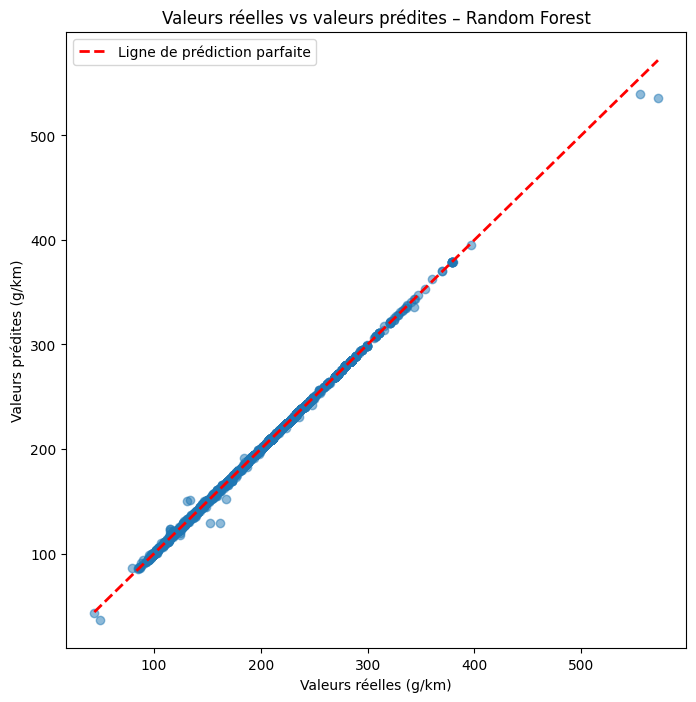

In [76]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Random Forest")
plt.legend()

plt.show()

Le nuage de points montre une excellente concordance entre les valeurs réelles et les valeurs prédites. La quasi-totalité des observations est alignée sur la diagonale représentant la prédiction parfaite, ce qui traduit une très grande précision du modèle Random Forest.

Quelques observations s'écartent néanmoins de cette droite, notamment certains véhicules présentant des émissions de CO₂ très élevées, pour lesquels le modèle tend à sous-estimer légèrement les valeurs réelles.

Ces écarts restent toutefois limités au regard de l'ensemble des prédictions. Le graphique confirme ainsi les excellentes performances du Random Forest observées à travers les différentes métriques d'évaluation, notamment le **R² de 0,9996** et la **RMSE de 0,7203 g/km**.

### Analyse des résidus

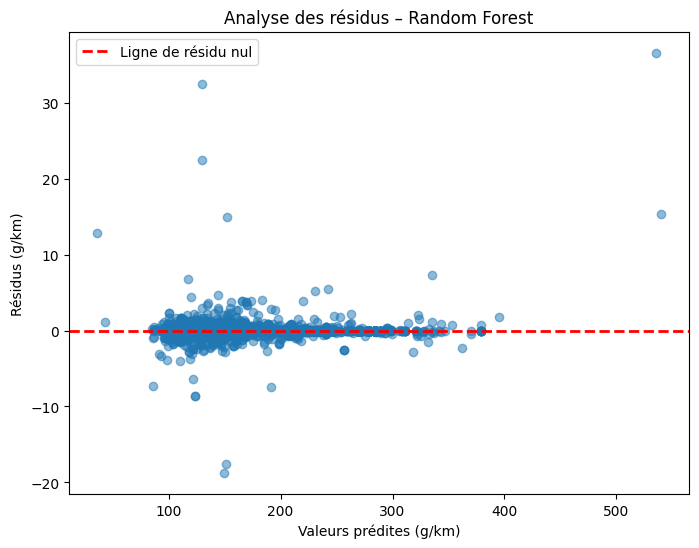

In [77]:
residus_rf = y_test - y_pred_rf

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_rf,
    residus_rf,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – Random Forest")
plt.legend()

plt.show()

Les résidus sont majoritairement concentrés autour de la ligne de résidu nul, sans tendance systématique clairement identifiable. Cette distribution suggère que le modèle Random Forest ne présente pas de biais global marqué dans ses prédictions.

La plupart des erreurs sont de faible amplitude, ce qui confirme la très bonne qualité des prédictions observée avec les différentes métriques d'évaluation.

Quelques observations atypiques présentent néanmoins des résidus plus importants, aussi bien pour certains véhicules aux émissions intermédiaires que pour des véhicules fortement émetteurs. Ces écarts correspondent à des situations ponctuelles dans lesquelles le modèle sous-estime ou surestime davantage les émissions réelles.

Dans l'ensemble, les résidus restent très proches de zéro pour la grande majorité des observations, ce qui est cohérent avec les excellentes performances du modèle (**MAE = 0,0925 g/km**, **RMSE = 0,7203 g/km** et **R² = 0,9996**).

### Courbe d'apprentissage

In [78]:
# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=random_forest,
    X=X_train,
    y=y_train,
    cv=3,
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

# Moyenne des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

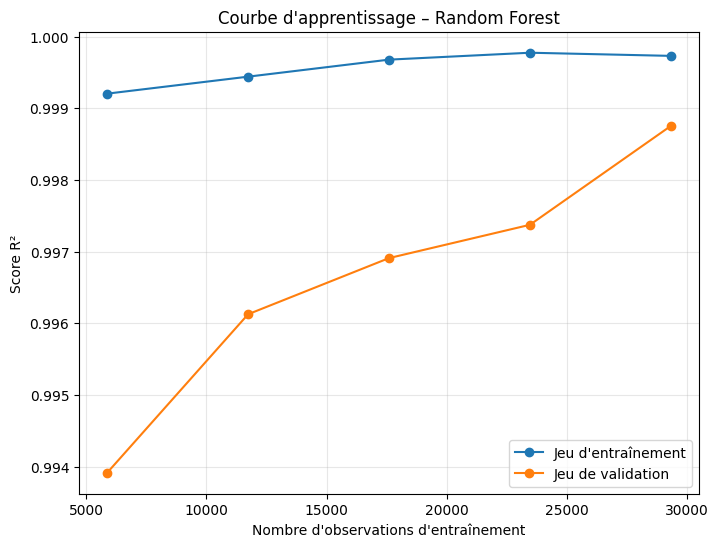

In [79]:
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – Random Forest")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

La courbe d'apprentissage montre que le modèle Random Forest obtient des performances très élevées, aussi bien sur le jeu d'entraînement que sur le jeu de validation.

Le score R² sur le jeu d'entraînement reste proche de 1, tandis que celui du jeu de validation progresse d'environ 0,994 à 0,999 lorsque le nombre d'observations augmente. Les deux courbes se rapprochent progressivement, ce qui traduit une amélioration de la capacité de généralisation du modèle.

L'écart entre les scores d'entraînement et de validation devient très faible avec davantage de données, indiquant un risque limité de surapprentissage. Le modèle conserve ainsi d'excellentes performances sur des observations non utilisées lors de son entraînement.

Dans l'ensemble, ces résultats confirment la stabilité et la bonne capacité de généralisation du Random Forest. La progression du score de validation suggère que l'ajout de données pourrait encore améliorer légèrement ses performances, même si celles-ci sont déjà très élevées.

## Optimisation du Random Forest avec GridSearchCV

### Introduction

Le Random Forest possède plusieurs hyperparamètres qui influencent ses performances, notamment le nombre d'arbres, leur profondeur maximale et les critères de division des nœuds.

L'objectif de cette étape est d'identifier la meilleure combinaison d'hyperparamètres à l'aide de **GridSearchCV**, afin d'améliorer les performances du modèle tout en conservant une bonne capacité de généralisation.

### Définition de la grille

In [80]:
# Grille des hyperparamètres à tester

param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

param_grid_rf

{'n_estimators': [100, 200],
 'max_depth': [10, 20, None],
 'min_samples_split': [2, 5],
 'min_samples_leaf': [1, 2]}

### Création de GridSearchCV

In [81]:
grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

### Entraînement

In [82]:
grid_rf.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


### Meilleurs hyperparamètres

In [83]:
print("Meilleurs paramètres :")
print(grid_rf.best_params_)

print("\nMeilleur score moyen (validation croisée) :")
print(f"{grid_rf.best_score_:.4f}")

Meilleurs paramètres :
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Meilleur score moyen (validation croisée) :
0.9991


L'optimisation par **GridSearchCV** identifie les hyperparamètres suivants pour le modèle Random Forest :

- **n_estimators = 100** : le modèle utilise 100 arbres de décision.
- **max_depth = 20** : la profondeur maximale des arbres est limitée à 20 niveaux, ce qui permet de contrôler leur complexité.
- **min_samples_split = 2** : un nœud peut être divisé lorsqu'il contient au moins deux observations.
- **min_samples_leaf = 1** : une feuille peut contenir une seule observation.

La principale différence avec le modèle initial concerne la profondeur maximale des arbres, désormais limitée à 20 niveaux. Cette configuration permet de réduire la complexité du modèle tout en conservant une grande capacité à représenter les relations présentes dans les données.

Le score moyen obtenu en validation croisée (**R² = 0,9991**) confirme les excellentes performances prédictives du Random Forest.

Ces résultats montrent que la limitation de la profondeur constitue, parmi les configurations évaluées, le meilleur compromis entre précision et complexité du modèle.

### Création du modèle optimisé

In [84]:
# Création du modèle optimisé

random_forest_opt = grid_rf.best_estimator_

### Prédiction

In [85]:
y_pred_rf_opt = random_forest_opt.predict(X_test)

### Évaluation

In [86]:
mae_rf_opt = mean_absolute_error(y_test, y_pred_rf_opt)
rmse_rf_opt = np.sqrt(mean_squared_error(y_test, y_pred_rf_opt))
r2_rf_opt = r2_score(y_test, y_pred_rf_opt)
mape_rf_opt = mean_absolute_percentage_error(y_test, y_pred_rf_opt)

print(f"MAE  : {mae_rf_opt:.2f}")
print(f"RMSE : {rmse_rf_opt:.2f}")
print(f"R²   : {r2_rf_opt:.4f}")
print(f"MAPE : {mape_rf_opt:.4f}")

MAE  : 0.09
RMSE : 0.71
R²   : 0.9996
MAPE : 0.0006


Le modèle Random Forest optimisé obtient d'excellentes performances sur le jeu de test, avec une **MAE de 0,09 g/km**, un **RMSE de 0,71 g/km**, un **R² de 0,9996** et un **MAPE de 0,0006**.

Ces résultats montrent que le modèle prédit les émissions de CO₂ avec une très grande précision. Le coefficient de détermination, proche de 1, indique que le modèle explique environ 99,96 % de la variabilité des émissions de CO₂ sur le jeu de test.

Les erreurs de prédiction restent particulièrement faibles, ce qui confirme la qualité des prédictions et la très bonne capacité de généralisation du Random Forest optimisé.

L'intérêt réel de l'optimisation sera évalué en comparant ces résultats à ceux du modèle initial.

### Comparaison avant / après optimisation

In [87]:
comparaison_rf = pd.DataFrame({
    "Version": [
        "Random Forest (par défaut)",
        "Random Forest optimisé"
    ],
    "N estimators": [
        100,
        grid_rf.best_params_["n_estimators"]
    ],
    "Max depth": [
        None,
        grid_rf.best_params_["max_depth"]
    ],
    "Min samples split": [
        2,
        grid_rf.best_params_["min_samples_split"]
    ],
    "Min samples leaf": [
        1,
        grid_rf.best_params_["min_samples_leaf"]
    ],
    "MAE": [
        mae_rf,
        mae_rf_opt
    ],
    "RMSE": [
        rmse_rf,
        rmse_rf_opt
    ],
    "R²": [
        r2_rf,
        r2_rf_opt
    ],
    "MAPE": [
        mape_rf,
        mape_rf_opt
    ]
})

comparaison_rf["Max depth"] = comparaison_rf["Max depth"].fillna("illimitée")

comparaison_rf.round(4)

,Version,N estimators,Max depth,Min samples split,Min samples leaf,MAE,RMSE,R²,MAPE
0,Random Forest (par défaut),100,illimitée,2,1,0.0925,0.7203,0.9996,0.0006
1,Random Forest optimisé,100,20.0,2,1,0.0925,0.7112,0.9996,0.0006


La comparaison entre le Random Forest initial et le modèle optimisé par **GridSearchCV** montre des performances très proches sur le jeu de test.

L'optimisation retient une profondeur maximale de **20 niveaux**, contre une profondeur illimitée pour le modèle initial. Les autres hyperparamètres restent inchangés : 100 arbres, `min_samples_split = 2` et `min_samples_leaf = 1`.

Cette configuration permet une légère diminution du **RMSE, qui passe de 0,7203 à 0,7112 g/km**, tandis que la MAE reste identique à 0,0925 g/km. Le coefficient de détermination (**R² = 0,9996**) et le MAPE (**0,0006**) demeurent également inchangés à la précision affichée.

Ces résultats montrent que l'optimisation apporte un gain limité en précision, tout en réduisant la profondeur maximale des arbres. Le modèle initial était déjà particulièrement performant.

Dans l'ensemble, **GridSearchCV** permet de retenir une configuration légèrement moins complexe, sans dégradation des performances prédictives, et confirme l'excellente capacité de généralisation du Random Forest.

## XGBoost (Boosting)

### Introduction

Le **XGBoost (Extreme Gradient Boosting)** est un algorithme d'ensemble basé sur le principe du **boosting**. Contrairement au Random Forest, qui construit les arbres de manière indépendante (bagging), XGBoost entraîne les arbres de façon séquentielle. Chaque nouvel arbre cherche à corriger les erreurs commises par les précédents, ce qui permet généralement d'obtenir d'excellentes performances prédictives.

Dans cette partie, nous entraînons un modèle XGBoost afin de le comparer aux modèles précédemment étudiés.

### Création du modèle

In [88]:
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

### Entraînement

In [89]:

xgb.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


### Prédictions

In [90]:
y_pred_xgb = xgb.predict(X_test)

### Évaluation

In [91]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)
mape_xgb = mean_absolute_percentage_error(y_test, y_pred_xgb)

print(f"MAE  : {mae_xgb:.2f}")
print(f"RMSE : {rmse_xgb:.2f}")
print(f"R²   : {r2_xgb:.4f}")
print(f"MAPE : {mape_xgb:.4f}")

MAE  : 0.29
RMSE : 0.59
R²   : 0.9997
MAPE : 0.0017


Les performances du modèle **XGBoost** sont excellentes, avec une **MAE de 0,29 g/km**, un **RMSE de 0,59 g/km**, un **R² de 0,9997** et un **MAPE de 0,0017**.

Ces résultats montrent que le modèle prédit les émissions de CO₂ avec une très grande précision. Le coefficient de détermination, proche de 1, indique que le modèle explique environ 99,97 % de la variabilité des émissions de CO₂ sur le jeu de test.

Comparé au Random Forest optimisé, XGBoost obtient un **RMSE plus faible (0,59 contre 0,71 g/km)** et un **R² légèrement supérieur (0,9997 contre 0,9996)**. En revanche, sa **MAE est plus élevée (0,29 contre 0,09 g/km)**, ce qui indique que ses erreurs absolues moyennes sont plus importantes.

Cette différence entre les métriques montre que les deux modèles présentent des avantages distincts. XGBoost limite davantage les erreurs importantes, auxquelles le RMSE accorde un poids plus élevé, tandis que le Random Forest réalise des prédictions plus précises en moyenne.

Dans l'ensemble, XGBoost constitue un modèle particulièrement performant, mais les résultats ne permettent pas de le considérer comme systématiquement supérieur au Random Forest. Le choix du meilleur modèle dépend notamment de la métrique d'évaluation privilégiée.

### Comparaison avec le DummyRegressor

In [92]:
comparaison_dummy_xgb = pd.DataFrame({
    "Modèle": ["DummyRegressor", "XGBoost"],
    "MAE": [mae_dummy, mae_xgb],
    "RMSE": [rmse_dummy, rmse_xgb],
    "R²": [r2_dummy, r2_xgb],
    "MAPE": [mape_dummy, mape_xgb]
})

comparaison_dummy_xgb = comparaison_dummy_xgb.round(4)

comparaison_dummy_xgb

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,XGBoost,0.2908,0.5940,0.9997,0.0017


La comparaison avec le **DummyRegressor** montre que le modèle **XGBoost** améliore très fortement les performances sur l'ensemble des métriques. Alors que le DummyRegressor se contente de prédire la moyenne des émissions de CO₂, XGBoost capture efficacement les relations entre les variables explicatives et la variable cible.

Les erreurs de prédiction diminuent considérablement, avec une **MAE passant de 22,4525 à 0,2908 g/km** et une **RMSE de 34,1556 à 0,5940 g/km**. Le coefficient de détermination atteint **R² = 0,9997**, contre une valeur proche de zéro pour le DummyRegressor.

Ces résultats confirment que le modèle possède une excellente capacité prédictive et constitue une amélioration majeure par rapport à un modèle de référence.

### Analyse de la capacité de généralisation

In [93]:
print(f"Score R² sur le jeu d'entraînement : {xgb.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {xgb.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 0.9998
Score R² sur le jeu de test         : 0.9997


Les scores obtenus sur les jeux d'entraînement (**R² = 0,9998**) et de test (**R² = 0,9997**) sont extrêmement proches. Cet écart très faible (0,0001) montre que le modèle généralise correctement et ne présente pas de signe de surapprentissage marqué.

Le modèle XGBoost conserve ainsi d'excellentes performances sur des données non vues pendant l'entraînement, ce qui confirme sa robustesse et sa capacité de généralisation.

### Valeurs réelles vs valeurs prédites

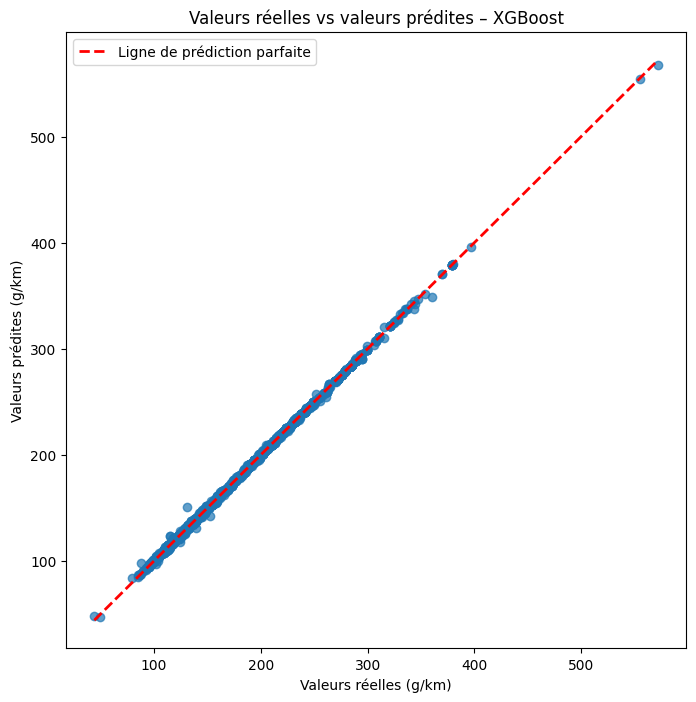

In [94]:

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – XGBoost")
plt.legend()

plt.show()

Le graphique montre que les prédictions du modèle XGBoost sont très proches des valeurs réelles. La quasi-totalité des observations est alignée sur la diagonale, qui représente une prédiction parfaite. Seuls quelques points présentent un léger écart, principalement pour les émissions les plus élevées.

Ces résultats confirment la très grande précision du modèle pour estimer les émissions de CO₂ sur l'ensemble du jeu de test.

### Analyse des résidus

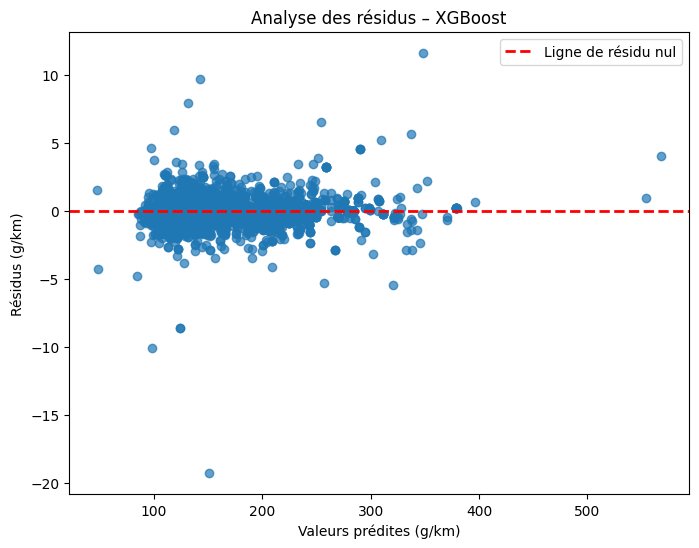

In [95]:
residus_xgb = y_test - y_pred_xgb

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_xgb,
    residus_xgb,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – XGBoost")

plt.legend()

plt.show()

Les résidus sont répartis de manière aléatoire autour de la ligne de résidu nul, sans tendance particulière. La majorité des erreurs reste proche de zéro, ce qui indique que le modèle ne présente pas de biais systématique apparent.

Quelques valeurs atypiques sont néanmoins observées, mais elles restent peu nombreuses et n'affectent pas les excellentes performances globales du modèle.

### Courbe d'apprentissage

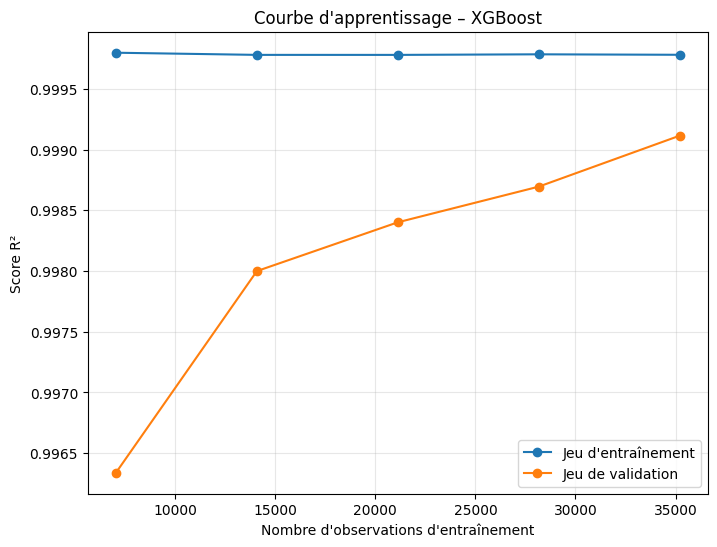

In [96]:
train_sizes, train_scores, test_scores = learning_curve(
    estimator=xgb,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

# Moyennes des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – XGBoost")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

Le score obtenu sur le jeu d'entraînement reste très élevé et stable (R² ≈ 0,9998), tandis que le score de validation augmente progressivement avec le nombre d'observations pour atteindre R² ≈ 0,9991.

L'écart entre les deux courbes diminue à mesure que le nombre d'observations augmente, ce qui montre que le modèle bénéficie de l'ajout de données tout en conservant une excellente capacité de généralisation. Aucun signe de sous-apprentissage ou de surapprentissage important n'est observé.

## Optimisation du XGBoost avec GridSearchCV

### Introduction

Les performances d'un modèle **XGBoost** dépendent fortement du choix de ses hyperparamètres. Afin d'identifier la combinaison la plus performante, une recherche par grille (**GridSearchCV**) est réalisée en utilisant une validation croisée.

Cette étape permet d'évaluer plusieurs configurations du modèle et de sélectionner automatiquement celle qui offre le meilleur score moyen en validation croisée. Le modèle optimisé sera ensuite comparé au modèle initial afin d'évaluer l'apport réel de cette optimisation.

### Définition de la grille

In [97]:
param_grid_xgb = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [4, 6, 8]
}

param_grid_xgb

{'n_estimators': [100, 200],
 'learning_rate': [0.05, 0.1],
 'max_depth': [4, 6, 8]}

### Création de GridSearchCV

In [98]:
grid_xgb = GridSearchCV(
    estimator=XGBRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid_xgb,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

### Entraînement

In [99]:
grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [4, 6, ...], 'n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


### Meilleurs hyperparamètres

In [100]:
print("Meilleurs paramètres :")
print(grid_xgb.best_params_)

print("\nMeilleur score moyen (validation croisée) :")
print(f"{grid_xgb.best_score_:.4f}")

Meilleurs paramètres :
{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200}

Meilleur score moyen (validation croisée) :
0.9992


L'optimisation par **GridSearchCV** identifie une configuration optimale composée de **200 arbres**, d'une **profondeur maximale de 4** et d'un **learning rate de 0,1**. Cette combinaison permet de limiter la complexité de chaque arbre tout en augmentant le nombre d'itérations par rapport au modèle initial.

Le score moyen obtenu en validation croisée (**R² = 0,9992**) confirme les excellentes performances du modèle et montre que cette configuration est la plus adaptée parmi celles évaluées.

### Création du modèle optimisé

In [101]:
# Création du modèle optimisé

xgb_opt = grid_xgb.best_estimator_

### Prédictions

In [102]:
y_pred_xgb_opt = xgb_opt.predict(X_test)

### Évaluation

In [103]:
mae_xgb_opt = mean_absolute_error(y_test, y_pred_xgb_opt)
rmse_xgb_opt = np.sqrt(mean_squared_error(y_test, y_pred_xgb_opt))
r2_xgb_opt = r2_score(y_test, y_pred_xgb_opt)
mape_xgb_opt = mean_absolute_percentage_error(y_test, y_pred_xgb_opt)

print(f"MAE  : {mae_xgb_opt:.2f}")
print(f"RMSE : {rmse_xgb_opt:.2f}")
print(f"R²   : {r2_xgb_opt:.4f}")
print(f"MAPE : {mape_xgb_opt:.4f}")

MAE  : 0.40
RMSE : 0.71
R²   : 0.9996
MAPE : 0.0023


Les performances du **XGBoost optimisé** restent excellentes, avec une **MAE de 0,40 g/km**, une **RMSE de 0,71 g/km**, un **R² de 0,9996** et un **MAPE de 0,0023**.

Malgré ces très bons résultats, le modèle optimisé présente des performances légèrement inférieures à celles du modèle XGBoost initial sur le jeu de test (**MAE = 0,29 g/km, RMSE = 0,59 g/km et R² = 0,9997**).

L'optimisation des hyperparamètres n'a donc pas permis d'améliorer la qualité des prédictions dans ce cas précis.

### Comparaison avant / après optimisation

### Scores train / test

In [104]:
comparaison_xgb = pd.DataFrame({
    "Version": [
        "XGBoost (par défaut)",
        "XGBoost optimisé"
    ],
    "Learning rate": [
        0.1,
        grid_xgb.best_params_["learning_rate"]
    ],
    "Max depth": [
        6,
        grid_xgb.best_params_["max_depth"]
    ],
    "N estimators": [
        100,
        grid_xgb.best_params_["n_estimators"]
    ],
    "MAE": [
        mae_xgb,
        mae_xgb_opt
    ],
    "RMSE": [
        rmse_xgb,
        rmse_xgb_opt
    ],
    "R²": [
        r2_xgb,
        r2_xgb_opt
    ],
    "MAPE": [
        mape_xgb,
        mape_xgb_opt
    ]
})

comparaison_xgb.round(4)

,Version,Learning rate,Max depth,N estimators,MAE,RMSE,R²,MAPE
0,XGBoost (par défaut),0.1,6,100,0.2908,0.5940,0.9997,0.0017
1,XGBoost optimisé,0.1,4,200,0.4025,0.7087,0.9996,0.0023


La comparaison entre le modèle XGBoost initial et le modèle optimisé montre que les performances sur le jeu de test restent très proches, mais que le modèle initial obtient des résultats légèrement meilleurs sur l'ensemble des métriques.

Bien que le GridSearchCV ait identifié une nouvelle combinaison d'hyperparamètres offrant le meilleur score moyen lors de la validation croisée, cette configuration ne se traduit pas par une amélioration des performances sur le jeu de test. Le modèle XGBoost initial est donc retenu comme version finale.

## Interprétabilité du modèle avec SHAP

## Introduction

Les performances d'un modèle ne suffisent pas toujours à justifier son utilisation. Il est également important de comprendre quelles variables influencent ses prédictions.

Pour cela, nous utilisons **SHAP (SHapley Additive exPlanations)**, une méthode d'interprétation des modèles de Machine Learning fondée sur la théorie des jeux. SHAP permet de mesurer la contribution de chaque variable aux prédictions réalisées par le modèle.

Cette analyse vise à identifier les variables les plus influentes dans l'estimation des émissions de CO₂ et à mieux comprendre le fonctionnement du modèle **XGBoost**, retenu pour ses excellentes performances prédictives, notamment en termes de **RMSE (0,5940 g/km)** et de **R² (0,9997)**, les meilleures parmi les modèles étudiés selon ces deux critères.

### Calcul des valeurs SHAP avec XGBoost

In [105]:
import xgboost as xgb_lib

X_test_dmatrix = xgb_lib.DMatrix(
    X_test,
    feature_names=list(X_test.columns)
)

shap_values_xgb = xgb.get_booster().predict(
    X_test_dmatrix,
    pred_contribs=True
)

print(shap_values_xgb.shape)
print(X_test.shape)

(11001, 94)
(11001, 93)


In [106]:
# Suppression de la dernière colonne correspondant au biais
shap_values = shap_values_xgb[:, :-1]

print("Dimensions des valeurs SHAP :", shap_values.shape)
print("Dimensions de X_test         :", X_test.shape)

Dimensions des valeurs SHAP : (11001, 93)
Dimensions de X_test         : (11001, 93)


### Visualisation globale des contributions SHAP

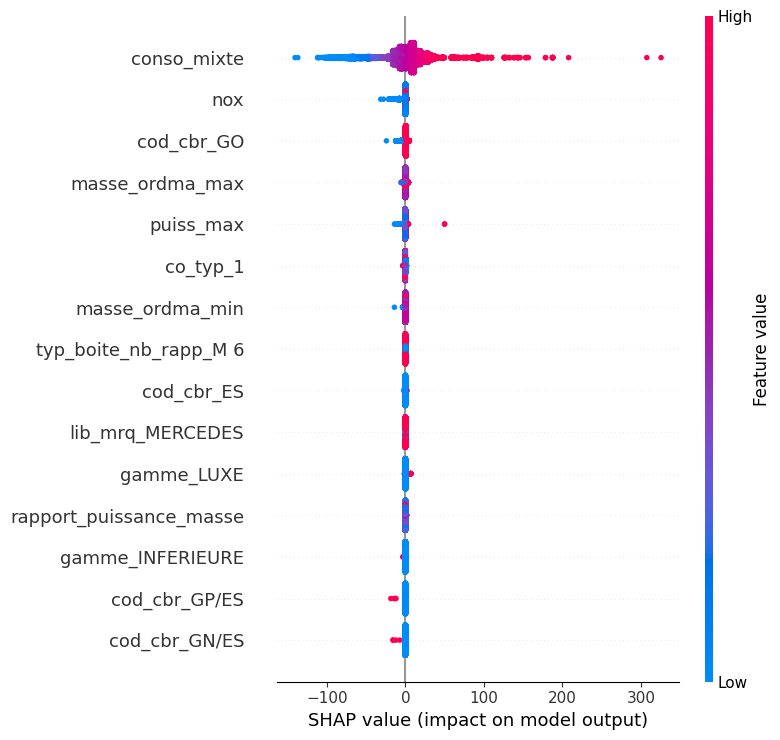

In [107]:
# Visualisation globale des contributions SHAP
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    max_display=15
)

L'analyse SHAP montre que la variable **conso_mixte** est de loin la plus influente dans les prédictions du modèle XGBoost. Les véhicules présentant une consommation mixte élevée contribuent fortement à une augmentation des émissions de CO₂ prédites, tandis qu'une faible consommation est associée à une diminution des émissions prédites.

Les autres variables, telles que les émissions de **NOx**, la **masse maximale**, la **puissance maximale** ou encore certaines caractéristiques liées au **carburant**, participent également aux prédictions, mais avec une influence nettement plus faible.

Ces résultats sont cohérents avec les connaissances métier : la consommation de carburant constitue l'un des principaux déterminants des émissions de CO₂. L'analyse SHAP permet ainsi de mieux comprendre le fonctionnement du modèle et montre que ses prédictions reposent principalement sur des variables dont l'influence est cohérente avec le phénomène étudié.

### Importance globale des variables selon SHAP

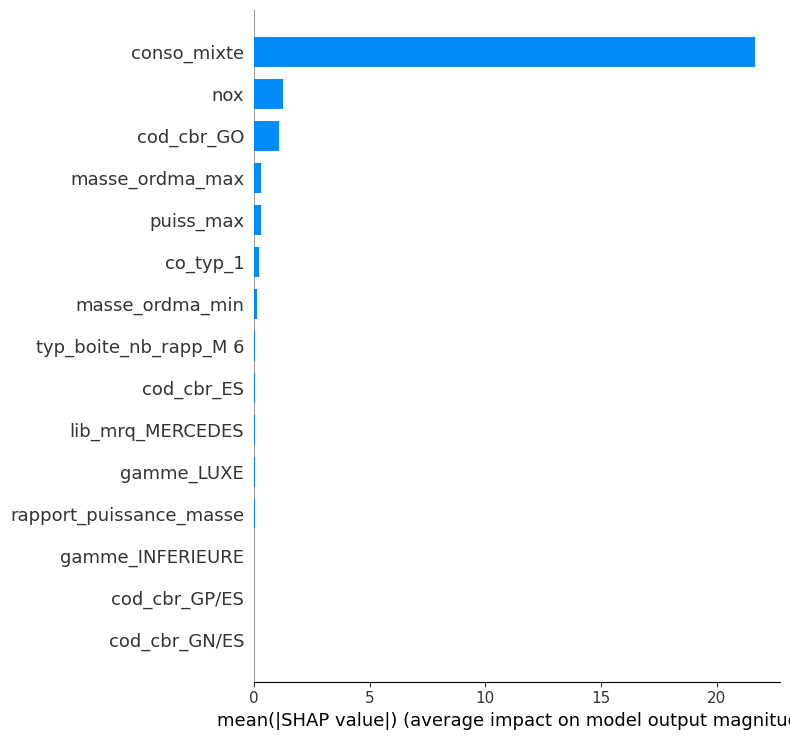

In [108]:
# Importance globale des variables selon les valeurs SHAP
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    plot_type="bar",
    max_display=15
)

Le graphique d'importance globale des variables confirme que **conso_mixte** est, de très loin, la variable la plus influente du modèle XGBoost. Avec une valeur SHAP absolue moyenne d'environ **22 g/km**, son importance dépasse largement celle des autres variables.

Les variables **nox**, **cod_cbr_GO**, **masse_ordma_max** et **puiss_max** participent également aux prédictions, mais leur contribution reste nettement plus faible.

Cette hiérarchie est cohérente avec les connaissances métier : la consommation de carburant constitue un facteur majeur des émissions de CO₂. Les résultats obtenus avec SHAP permettent ainsi de mieux comprendre le fonctionnement du modèle et mettent en évidence la prédominance de **conso_mixte** dans ses prédictions.

## LightGBM

### Introduction

Le **Light Gradient Boosting Machine (LightGBM)** est un algorithme de boosting développé par Microsoft. Comme XGBoost, il construit un ensemble d'arbres de décision de manière séquentielle afin de corriger progressivement les erreurs des arbres précédents.

Contrairement à XGBoost, LightGBM utilise une stratégie de croissance des arbres par feuilles (*leaf-wise growth*), ce qui lui permet généralement d'obtenir des temps d'entraînement plus rapides tout en conservant d'excellentes performances sur des jeux de données volumineux.

Dans cette partie, nous évaluons les performances de LightGBM sur notre problème de prédiction des émissions de CO₂, puis nous les comparerons aux autres modèles étudiés précédemment.

### Création du modèle

Nous commençons par entraîner un modèle LightGBM avec ses paramètres par défaut. Cette première version servira de référence avant d'éventuelles optimisations des hyperparamètres à l'aide de GridSearchCV.

In [109]:
# Création du modèle

lgbm = LGBMRegressor(
    random_state=42,
    verbose=-1
)

### Entraînement

In [110]:
# Entraînement du modèle

lgbm.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


### Prédictions

In [111]:
# Prédictions sur le jeu de test

y_pred_lgbm = lgbm.predict(X_test)

### Évaluation

In [112]:
mae_lgbm = mean_absolute_error(y_test, y_pred_lgbm)
rmse_lgbm = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))
r2_lgbm = r2_score(y_test, y_pred_lgbm)
mape_lgbm = mean_absolute_percentage_error(y_test, y_pred_lgbm)

print(f"MAE  : {mae_lgbm:.2f}")
print(f"RMSE : {rmse_lgbm:.2f}")
print(f"R²   : {r2_lgbm:.4f}")
print(f"MAPE : {mape_lgbm:.4f}")

MAE  : 0.37
RMSE : 1.75
R²   : 0.9974
MAPE : 0.0021


Le modèle **LightGBM** obtient d'excellentes performances avec un **R² de 0,9974**, traduisant une très bonne capacité à prédire les émissions de CO₂.

Toutefois, les erreurs de prédiction (**MAE = 0,37 g/km**, **RMSE = 1,75 g/km** et **MAPE = 0,0021**) restent plus élevées que celles obtenues avec **XGBoost** et **Random Forest**.

Cette première évaluation montre qu'avec ses paramètres par défaut, **LightGBM** reste performant, mais n'atteint pas encore le niveau des meilleurs modèles précédemment étudiés.

### Comparaison avec le DummyRegressor

In [113]:
comparaison_dummy_lgbm = pd.DataFrame({
    "Modèle": ["DummyRegressor", "LightGBM"],
    "MAE": [mae_dummy, mae_lgbm],
    "RMSE": [rmse_dummy, rmse_lgbm],
    "R²": [r2_dummy, r2_lgbm],
    "MAPE": [mape_dummy, mape_lgbm]
})

comparaison_dummy_lgbm = comparaison_dummy_lgbm.round(4)

comparaison_dummy_lgbm

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,LightGBM,0.3736,1.7499,0.9974,0.0021


Comparé au **DummyRegressor**, le modèle **LightGBM** améliore très fortement l'ensemble des métriques de performance. Cette différence confirme que le modèle exploite efficacement les variables explicatives pour prédire les émissions de CO₂ et constitue une approche de régression particulièrement performante.

## Analyse de la capacité de généralisation

### Scores train / test

In [114]:
print(f"Score R² sur le jeu d'entraînement : {lgbm.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {lgbm.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 0.9989
Score R² sur le jeu de test         : 0.9974


Les scores obtenus sur les jeux d'entraînement (**R² = 0,9989**) et de test (**R² = 0,9974**) sont très proches, ce qui indique que le modèle présente une bonne capacité de généralisation.

Le faible écart entre les deux performances suggère que **LightGBM ne présente pas de surapprentissage marqué** avec ses paramètres par défaut.

Les performances restent toutefois inférieures à celles de **Random Forest** et **XGBoost**, laissant envisager un potentiel d'amélioration par optimisation des hyperparamètres.

### Valeurs réelles vs valeurs prédites

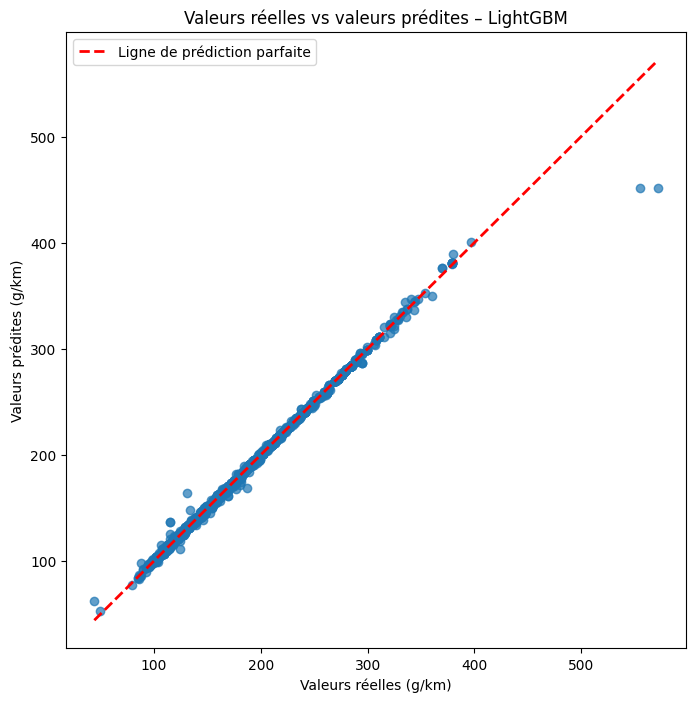

In [115]:
# Valeurs réelles vs valeurs prédites

plt.figure(figsize=(8, 8))

plt.scatter(y_test, y_pred_lgbm, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – LightGBM")
plt.legend()

plt.show()

Le graphique montre que la majorité des observations est bien alignée sur la diagonale, ce qui confirme la bonne qualité globale des prédictions.

En revanche, quelques observations correspondant aux émissions les plus élevées s'écartent davantage de cette diagonale. Le modèle tend notamment à sous-estimer les émissions de certains véhicules fortement émetteurs.

Ces erreurs de prédiction contribuent à expliquer les valeurs de **RMSE et de MAE plus élevées** que celles obtenues avec **XGBoost** et **Random Forest**.

### Analyse des résidus

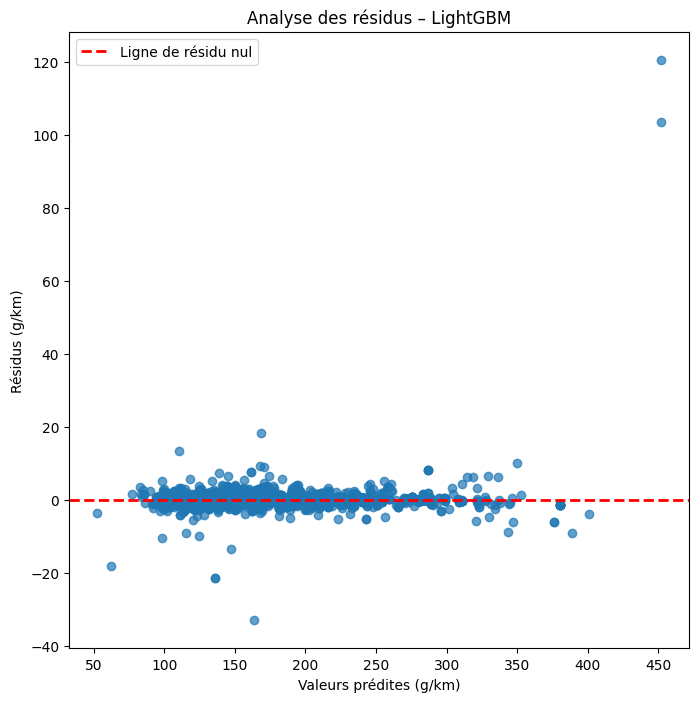

In [116]:
# Calcul des résidus

residus_lgbm = y_test - y_pred_lgbm

plt.figure(figsize=(8, 8))

plt.scatter(y_pred_lgbm, residus_lgbm, alpha=0.7)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – LightGBM")

plt.legend()

plt.show()

Les résidus sont globalement répartis autour de zéro, sans tendance particulière pour la majorité des observations, ce qui suggère que le modèle ne présente pas de biais systématique marqué.

En revanche, plusieurs observations atypiques présentent des résidus relativement importants. Deux observations se distinguent notamment par des résidus positifs supérieurs à **100 g/km**, traduisant une sous-estimation importante des émissions de CO₂ réelles.

Ces valeurs extrêmes contribuent à augmenter la **RMSE (1,75 g/km)** et expliquent en partie les performances inférieures à celles obtenues avec **XGBoost** et **Random Forest**.

### Courbe d'apprentissage

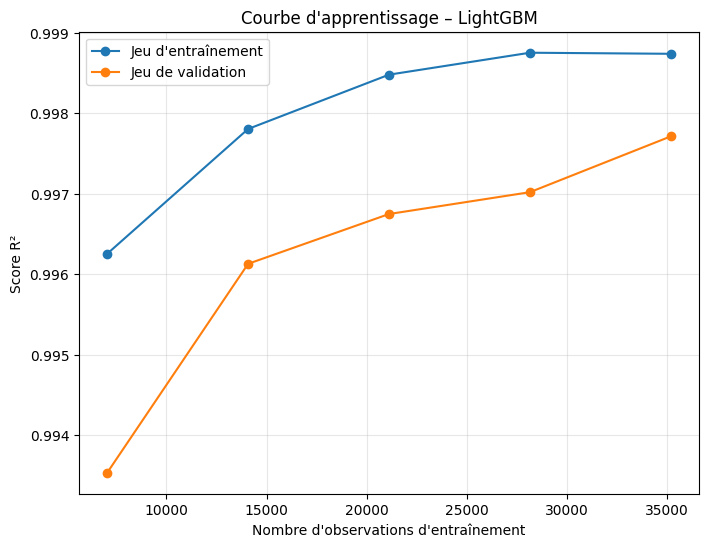

In [117]:
train_sizes, train_scores, test_scores = learning_curve(
    estimator=lgbm,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

# Moyennes des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage – LightGBM")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

La courbe d'apprentissage montre que les performances sur les jeux d'entraînement et de validation progressent globalement avec l'augmentation du nombre d'observations.

Le score d'entraînement se stabilise autour de **R² = 0,9987**, tandis que le score de validation continue de progresser pour atteindre environ **R² = 0,9977**. L'écart entre les deux courbes reste faible, ce qui confirme une bonne capacité de généralisation et un risque limité de surapprentissage.

Toutefois, les performances en validation restent légèrement inférieures à celles observées avec **XGBoost**, ce qui laisse envisager un potentiel d'amélioration de LightGBM par l'optimisation de ses hyperparamètres.

## Optimisation du LightGBM avec GridSearchCV

### Introduction

Les performances du modèle **LightGBM** dépendent du choix de ses hyperparamètres, notamment du nombre d'arbres, du taux d'apprentissage, de la profondeur maximale et du nombre de feuilles.

L'objectif de cette étape est d'identifier la meilleure combinaison d'hyperparamètres à l'aide de **GridSearchCV**, en utilisant une validation croisée à 5 plis.

Le modèle optimisé sera ensuite comparé au modèle initial afin d'évaluer l'apport réel de cette optimisation sur les performances prédictives.

### Définition de la grille

In [120]:
# Grille des hyperparamètres à tester

param_grid_lgbm = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [4, 6, 8],
    "num_leaves": [31, 50]
}

param_grid_lgbm

{'n_estimators': [100, 200],
 'learning_rate': [0.05, 0.1],
 'max_depth': [4, 6, 8],
 'num_leaves': [31, 50]}

### Création de GridSearchCV

In [121]:
grid_lgbm = GridSearchCV(
    estimator=LGBMRegressor(
        random_state=42,
        verbose=-1
    ),
    param_grid=param_grid_lgbm,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

### Entraînement

In [122]:
# Entraînement du GridSearchCV

grid_lgbm.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,estimator,"LGBMRegressor...2, verbose=-1)"
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [4, 6, ...], 'n_estimators': [100, 200], 'num_leaves': [31, 50]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,boosting_type,'gbdt'


### Meilleurs hyperparamètres

In [123]:
print("Meilleurs paramètres :")
print(grid_lgbm.best_params_)

print("\nMeilleur score moyen (validation croisée) :")
print(f"{grid_lgbm.best_score_:.4f}")

Meilleurs paramètres :
{'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 200, 'num_leaves': 31}

Meilleur score moyen (validation croisée) :
0.9980


L'optimisation par GridSearchCV identifie une configuration reposant sur 200 estimateurs, une profondeur maximale de 8 et un learning rate de 0,1, tandis que le paramètre num_leaves conserve sa valeur par défaut (31).

Le score moyen obtenu en validation croisée (R² = 0,9980) confirme les bonnes performances du modèle et suggère que l'augmentation du nombre d'arbres ainsi qu'une profondeur plus importante pourraient améliorer la qualité des prédictions. Cette hypothèse sera vérifiée sur le jeu de test.

### Création du modèle optimisé

In [124]:
# Création du modèle optimisé

lgbm_opt = grid_lgbm.best_estimator_


### Prédictions

In [125]:
# Prédictions sur le jeu de test

y_pred_lgbm_opt = lgbm_opt.predict(X_test)

### Évaluation

In [126]:
mae_lgbm_opt = mean_absolute_error(y_test, y_pred_lgbm_opt)
rmse_lgbm_opt = np.sqrt(mean_squared_error(y_test, y_pred_lgbm_opt))
r2_lgbm_opt = r2_score(y_test, y_pred_lgbm_opt)
mape_lgbm_opt = mean_absolute_percentage_error(y_test, y_pred_lgbm_opt)

print(f"MAE  : {mae_lgbm_opt:.2f}")
print(f"RMSE : {rmse_lgbm_opt:.2f}")
print(f"R²   : {r2_lgbm_opt:.4f}")
print(f"MAPE : {mape_lgbm_opt:.4f}")

MAE  : 0.37
RMSE : 1.29
R²   : 0.9986
MAPE : 0.0021


Le modèle LightGBM optimisé améliore les performances obtenues avec les paramètres par défaut. Le RMSE diminue de 1,75 g/km à 1,29 g/km et le coefficient de détermination augmente de R² = 0,9974 à R² = 0,9986. La MAE reste proche de 0,37 g/km et la MAPE se maintient à 0,0021.

Ces résultats montrent que l'optimisation des hyperparamètres permet de mieux adapter le modèle au jeu de données étudié, notamment en réduisant les erreurs les plus importantes.

### Comparaison avant / après optimisation

In [127]:
comparaison_lgbm = pd.DataFrame({
    "Version": [
        "LightGBM (par défaut)",
        "LightGBM optimisé"
    ],
    "Learning rate": [0.1, 0.1],
    "Max depth": [6, 8],
    "N estimators": [100, 200],
    "Num leaves": [31, 31],
    "MAE": [mae_lgbm, mae_lgbm_opt],
    "RMSE": [rmse_lgbm, rmse_lgbm_opt],
    "R²": [r2_lgbm, r2_lgbm_opt],
    "MAPE": [mape_lgbm, mape_lgbm_opt]
})

comparaison_lgbm = comparaison_lgbm.round(4)

comparaison_lgbm

,Version,Learning rate,Max depth,N estimators,Num leaves,MAE,RMSE,R²,MAPE
0,LightGBM (par défaut),0.1,6,100,31,0.3736,1.7499,0.9974,0.0021
1,LightGBM optimisé,0.1,8,200,31,0.3701,1.2902,0.9986,0.0021


La comparaison entre le modèle LightGBM initial et le modèle optimisé montre que l'optimisation des hyperparamètres améliore les performances sur le jeu de test. Les erreurs de prédiction diminuent (MAE de 0,3736 à 0,3701 et RMSE de 1,7499 à 1,2902), tandis que la MAPE reste stable à 0,0021 et que le coefficient de détermination progresse de 0,9974 à 0,9986.

Contrairement aux résultats obtenus avec Random Forest et XGBoost, où les gains étaient limités ou inexistants selon les métriques, le GridSearchCV permet ici d'identifier une configuration globalement plus performante. Le modèle LightGBM optimisé est donc retenu comme version finale pour cet algorithme.

# Expérimentations complémentaires

Cette section présente plusieurs expérimentations complémentaires réalisées afin de répondre aux recommandations formulées au cours du projet et d'évaluer des pistes d'amélioration des modèles développés précédemment.

Ces expérimentations portent notamment sur la transformation de la variable cible, l'utilisation de la validation croisée ainsi que l'évaluation d'approches alternatives de modélisation.

## Transformation logarithmique de la variable cible

### Introduction

### Objectif

Les modèles linéaires peuvent être sensibles à la distribution de la variable cible. Lorsque celle-ci présente une forte asymétrie ou quelques valeurs élevées, une transformation logarithmique permet parfois de stabiliser la variance et d'améliorer les performances des modèles.

L'objectif de cette expérimentation est d'évaluer l'impact d'une transformation logarithmique des émissions de CO₂ sur les performances des modèles linéaires (**Régression linéaire**, **Ridge** et **Lasso**) et de comparer les résultats obtenus avec ceux de la modélisation initiale.

### Préparation des données

Avant d'entraîner les modèles, la variable cible est transformée à l'aide de la fonction logarithmique `log1p`. Cette transformation permet de réduire l'influence des valeurs les plus élevées tout en conservant les valeurs nulles éventuelles.

Une fois les prédictions réalisées, une transformation inverse (`expm1`) sera appliquée afin d'exprimer les résultats dans l'unité d'origine (g/km de CO₂) et de permettre une comparaison directe avec les modèles précédents.

### Création de la variable cible transformée

In [128]:
# Transformation logarithmique de la variable cible

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

### Vérification

In [129]:
print("Avant transformation :")
print(y_train.head())

print("\nAprès transformation logarithmique :")
print(y_train_log.head())

Avant transformation :
0    190.0
1    121.0
2    195.0
3    203.0
4    203.0
Name: co2, dtype: float64

Après transformation logarithmique :
0    5.252273
1    4.804021
2    5.278115
3    5.318120
4    5.318120
Name: co2, dtype: float64


## Régression linéaire

### Entraînement du modèle

In [130]:
# Création du modèle

lin_log = LinearRegression()

# Entraînement

lin_log.fit(X_train, y_train_log)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Prédictions

In [131]:
# Prédictions sur l'échelle logarithmique

y_pred_log = lin_log.predict(X_test)

# Retour à l'échelle d'origine

y_pred_lin_log = np.expm1(y_pred_log)

### Évaluation

In [132]:
mae_lin_log = mean_absolute_error(y_test, y_pred_lin_log)
rmse_lin_log = np.sqrt(mean_squared_error(y_test, y_pred_lin_log))
r2_lin_log = r2_score(y_test, y_pred_lin_log)
mape_lin_log = mean_absolute_percentage_error(y_test, y_pred_lin_log)

print(f"MAE  : {mae_lin_log:.2f}")
print(f"RMSE : {rmse_lin_log:.2f}")
print(f"R²   : {r2_lin_log:.4f}")
print(f"MAPE : {mape_lin_log:.4f}")

MAE  : 2.73
RMSE : 8.43
R²   : 0.9390
MAPE : 0.0139


Les résultats montrent que la transformation logarithmique de la variable cible dégrade les performances de la Régression linéaire. Les quatre métriques d'évaluation (MAE, RMSE, R² et MAPE) sont moins bonnes que celles obtenues avec le modèle entraîné sur la variable cible d'origine.

Dans ce contexte, la transformation logarithmique n'apporte donc aucun bénéfice pour la Régression linéaire. Le modèle initial est conservé comme la meilleure version pour cette approche.

## Régression Ridge

### Entraînement du modèle

In [133]:
# Création du modèle

ridge_log = Ridge(alpha=1.0)

# Entraînement

ridge_log.fit(X_train, y_train_log)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


### Prédictions

In [134]:
# Prédictions sur l'échelle logarithmique

y_pred_log = ridge_log.predict(X_test)

# Retour à l'échelle d'origine

y_pred_ridge_log = np.expm1(y_pred_log)

### Évaluation

In [135]:
mae_ridge_log = mean_absolute_error(y_test, y_pred_ridge_log)
rmse_ridge_log = np.sqrt(mean_squared_error(y_test, y_pred_ridge_log))
r2_ridge_log = r2_score(y_test, y_pred_ridge_log)
mape_ridge_log = mean_absolute_percentage_error(y_test, y_pred_ridge_log)

print(f"MAE  : {mae_ridge_log:.2f}")
print(f"RMSE : {rmse_ridge_log:.2f}")
print(f"R²   : {r2_ridge_log:.4f}")
print(f"MAPE : {mape_ridge_log:.4f}")

MAE  : 2.73
RMSE : 8.23
R²   : 0.9419
MAPE : 0.0139


Les résultats montrent que la transformation logarithmique de la variable cible dégrade également les performances du modèle Ridge. Les erreurs de prédiction (MAE, RMSE et MAPE) augmentent sensiblement, tandis que le coefficient de détermination (R²) diminue par rapport au modèle entraîné sur la variable cible d'origine.

Comme pour la Régression linéaire, cette transformation n'apporte donc aucun bénéfice dans le cadre de cette étude. Le modèle Ridge entraîné sur la variable cible initiale est conservé comme version de référence.

## Régression Lasso

### Entraînement du modèle

In [136]:
# Création du modèle

lasso_log = Lasso(alpha=0.1)

# Entraînement

lasso_log.fit(X_train, y_train_log)

,alpha,0.1
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


### Prédictions

In [137]:
# Prédictions sur l'échelle logarithmique

y_pred_log = lasso_log.predict(X_test)

# Retour à l'échelle d'origine

y_pred_lasso_log = np.expm1(y_pred_log)

### Évaluation

In [138]:
mae_lasso_log = mean_absolute_error(y_test, y_pred_lasso_log)
rmse_lasso_log = np.sqrt(mean_squared_error(y_test, y_pred_lasso_log))
r2_lasso_log = r2_score(y_test, y_pred_lasso_log)
mape_lasso_log = mean_absolute_percentage_error(y_test, y_pred_lasso_log)

print(f"MAE  : {mae_lasso_log:.2f}")
print(f"RMSE : {rmse_lasso_log:.2f}")
print(f"R²   : {r2_lasso_log:.4f}")
print(f"MAPE : {mape_lasso_log:.4f}")

MAE  : 16.81
RMSE : 22.30
R²   : 0.5737
MAPE : 0.0865


Les résultats montrent que le modèle Lasso entraîné sur la variable cible transformée logarithmiquement présente des performances nettement inférieures à celles du Lasso initial. Les erreurs de prédiction sont importantes (MAE = 16,81 g/km, RMSE = 22,30 g/km et MAPE = 0,0865), tandis que le coefficient de détermination chute à R² = 0,5737, contre 0,9923 pour le Lasso initial.

Cette expérimentation ne permet donc pas de mettre en évidence un bénéfice de la transformation logarithmique pour le modèle Lasso. Toutefois, le paramètre de régularisation utilisé (alpha = 0,1) étant différent de celui du modèle initial (alpha = 1), la dégradation observée ne peut pas être attribuée uniquement à la transformation logarithmique.

Le modèle entraîné sur la variable cible d'origine est conservé comme version de référence.

### Tableau comparatif

In [139]:
comparaison_log = pd.DataFrame({
    "Modèle": [
        "Régression linéaire",
        "Ridge",
        "Lasso"
    ],
    "R² (sans log)": [
        r2_lin,
        r2_ridge,
        r2_lasso
    ],
    "R² (avec log)": [
        r2_lin_log,
        r2_ridge_log,
        r2_lasso_log
    ],
    "RMSE (sans log)": [
        rmse_lin,
        rmse_ridge,
        rmse_lasso
    ],
    "RMSE (avec log)": [
        rmse_lin_log,
        rmse_ridge_log,
        rmse_lasso_log
    ],
    "Conclusion": [
        "Dégradation",
        "Dégradation",
        "Dégradation"
    ]
})

comparaison_log.round(4)

,Modèle,R² (sans log),R² (avec log),RMSE (sans log),RMSE (avec log),Conclusion
0,Régression linéaire,0.9974,0.9390,1.7402,8.4343,Dégradation
1,Ridge,0.9974,0.9419,1.7401,8.2347,Dégradation
2,Lasso,0.9923,0.5737,3.0057,22.2996,Dégradation


Les résultats obtenus montrent que la transformation logarithmique de la variable cible ne permet pas d'améliorer les performances des modèles linéaires évalués. Pour les trois modèles testés (Régression linéaire, Ridge et Lasso), les erreurs de prédiction (MAE, RMSE et MAPE) augmentent, tandis que le coefficient de détermination (R²) diminue par rapport aux modèles entraînés sur la variable cible d'origine.

Ces résultats indiquent que, dans les configurations testées, les modèles linéaires obtiennent de meilleures performances lorsqu'ils sont entraînés directement sur la variable cible initiale.

Cette expérimentation répond ainsi à la recommandation formulée au cours du projet et montre que, sur ce jeu de données, la transformation logarithmique n'apporte pas de gain en termes de qualité de prédiction.

## Validation croisée (K-Fold Cross Validation)

### Introduction

Jusqu'à présent, les performances des modèles ont été évaluées à l'aide d'un découpage unique des données en ensembles d'entraînement et de test.

Afin d'obtenir une estimation plus robuste des performances, une validation croisée de type **K-Fold Cross Validation** est réalisée sur les meilleurs modèles retenus. Cette méthode consiste à diviser le jeu de données en plusieurs sous-ensembles (folds), chacun étant utilisé successivement comme jeu de validation tandis que les autres servent à l'entraînement.


## Préparation des données pour la validation croisée

La validation croisée est réalisée uniquement sur le jeu d'entraînement (`X_train` et `y_train`) afin de préserver l'indépendance du jeu de test.

Le jeu d'entraînement est divisé en plusieurs sous-ensembles (folds), permettant d'évaluer la stabilité des performances des modèles sur différentes partitions des données.

Le jeu de test (`X_test` et `y_test`) reste réservé à l'évaluation finale.

In [140]:
# Préparation des données pour la validation croisée

X_cv = X_train.copy()
y_cv = y_train.copy()

### Vérification

In [141]:
print("Dimensions de X_cv :", X_cv.shape)
print("Dimensions de y_cv :", y_cv.shape)

Dimensions de X_cv : (44002, 93)
Dimensions de y_cv : (44002,)


## Random Forest

In [142]:
scores_rf = cross_val_score(
    random_forest_opt,
    X_cv,
    y_cv,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print(scores_rf)

print(f"R² moyen : {scores_rf.mean():.4f}")
print(f"Écart-type : {scores_rf.std():.4f}")

[0.99907568 0.99949506 0.99946154 0.99958833 0.9978082 ]
R² moyen : 0.9991
Écart-type : 0.0007


Les résultats de la validation croisée montrent que le modèle Random Forest conserve d'excellentes performances sur les différents sous-ensembles de données. Le coefficient de détermination moyen atteint 0,9991, avec un écart-type très faible (0,0007), ce qui traduit une excellente stabilité du modèle.

Cette validation montre que les performances élevées observées lors du découpage initial en jeux d'entraînement et de test se retrouvent également sur différentes partitions du jeu d'entraînement. Le modèle présente ainsi une très bonne capacité de généralisation sur les données évaluées.

## XGBoost

In [143]:
scores_xgb = cross_val_score(
    xgb,
    X_cv,
    y_cv,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print(scores_xgb)

print(f"R² moyen : {scores_xgb.mean():.4f}")
print(f"Écart-type : {scores_xgb.std():.4f}")

[0.99835733 0.99951891 0.99954544 0.99955938 0.99858376]
R² moyen : 0.9991
Écart-type : 0.0005


Les résultats de la validation croisée confirment les excellentes performances du modèle XGBoost. Le coefficient de détermination moyen atteint 0,9991, avec un écart-type très faible (0,0005), ce qui traduit une grande stabilité des performances sur les différents découpages des données.

Cette expérimentation montre que les performances élevées observées lors de l'évaluation initiale se retrouvent également sur différentes partitions du jeu d'entraînement. Le modèle présente ainsi une très bonne capacité de généralisation sur les données évaluées.

## LightGBM

In [144]:
scores_lgbm = cross_val_score(
    lgbm_opt,
    X_cv,
    y_cv,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print(scores_lgbm)

print(f"R² moyen : {scores_lgbm.mean():.4f}")
print(f"Écart-type : {scores_lgbm.std():.4f}")

[0.99780421 0.99867296 0.99909528 0.99890539 0.99545997]
R² moyen : 0.9980
Écart-type : 0.0013


Les résultats de la validation croisée montrent que le modèle LightGBM conserve d'excellentes performances sur les différents sous-ensembles de données. Le coefficient de détermination moyen atteint 0,9980, avec un écart-type de 0,0013, ce qui traduit une bonne stabilité globale du modèle, malgré des variations légèrement plus importantes entre les plis.

Bien que ses performances restent très élevées, elles demeurent légèrement inférieures à celles obtenues par Random Forest et XGBoost (R² moyen de 0,9991 pour chacun). La validation croisée confirme ainsi que LightGBM constitue une alternative performante, mais qu'il ne surpasse pas les deux meilleurs modèles de cette étude.

## Tableau comparatif

In [145]:
comparaison_cv = pd.DataFrame({
    "Modèle": [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "R² moyen": [
        scores_rf.mean(),
        scores_xgb.mean(),
        scores_lgbm.mean()
    ],
    "Écart-type": [
        scores_rf.std(),
        scores_xgb.std(),
        scores_lgbm.std()
    ]
})

comparaison_cv = comparaison_cv.sort_values(
    by="R² moyen",
    ascending=False
).reset_index(drop=True)

comparaison_cv.round(4)

,Modèle,R² moyen,Écart-type
0,XGBoost,0.9991,0.0005
1,Random Forest,0.9991,0.0007
2,LightGBM,0.9980,0.0013


## Conclusion générale de la validation croisée

La validation croisée (K-Fold Cross Validation) confirme les excellentes performances des trois modèles retenus. Les coefficients de détermination moyens sont tous supérieurs ou égaux à 0,9980, tandis que les écarts-types restent faibles, ce qui traduit une bonne stabilité des modèles sur les différentes partitions du jeu d'entraînement.

Parmi les modèles évalués, XGBoost obtient les meilleurs résultats avec un R² moyen de 0,9991 et l'écart-type le plus faible (0,0005), confirmant la stabilité de ses performances. Random Forest affiche également des performances remarquables, avec un R² moyen très proche (0,9991), tandis que LightGBM reste très performant, bien qu'il soit légèrement en retrait (R² = 0,9980).

Cette expérimentation répond à la recommandation formulée au cours du projet et montre que les performances élevées observées lors du découpage initial se retrouvent également sur différentes partitions du jeu d'entraînement. Elle renforce ainsi le choix de XGBoost comme modèle de référence pour la prédiction des émissions de CO₂.

## Perceptron Multicouche (MLP)

### Introduction

Afin de compléter les expérimentations réalisées au cours de cette étude, un **Perceptron Multicouche (MLP)** est également évalué.

Contrairement aux modèles précédents reposant sur des approches linéaires ou des ensembles d'arbres de décision, le MLP est un réseau de neurones artificiel capable d'apprendre des relations non linéaires complexes entre les variables explicatives et la variable cible.

L'objectif de cette expérimentation est d'évaluer les performances d'un réseau de neurones simple et de les comparer à celles des modèles de Machine Learning précédemment étudiés.

### Création du MLP

In [146]:
# Fixer la graine aléatoire pour rendre l'entraînement reproductible
tf.keras.utils.set_random_seed(42)

mlp = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])

mlp.summary()

E0000 00:00:1791753136.609383    4035 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,129 (31.75 KB)

 Trainable params: 8,129 (31.75 KB)

 Non-trainable params: 0 (0.00 B)

### Préparation et standardisation des données pour le MLP

In [147]:
# Séparation entraînement / validation
X_mlp_train, X_mlp_val, y_mlp_train, y_mlp_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# Standardisation sans utiliser les données de validation ou de test
scaler_mlp = StandardScaler()

X_mlp_train_scaled = scaler_mlp.fit_transform(X_mlp_train)
X_mlp_val_scaled = scaler_mlp.transform(X_mlp_val)
X_mlp_test_scaled = scaler_mlp.transform(X_test)

### Compilation

In [148]:
# Compilation du modèle

mlp.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

### Entraînement

In [149]:
# Entraînement du MLP sur les données standardisées

history = mlp.fit(
    X_mlp_train_scaled,
    y_mlp_train,
    validation_data=(X_mlp_val_scaled, y_mlp_val),
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 5549.5156 - mae: 37.9459 - val_loss: 191.1491 - val_mae: 5.7912
Epoch 2/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 72.0364 - mae: 4.2372 - val_loss: 64.5386 - val_mae: 3.5186
Epoch 3/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 32.9078 - mae: 2.8978 - val_loss: 30.1916 - val_mae: 2.6499
Epoch 4/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 18.7915 - mae: 2.2100 - val_loss: 18.3771 - val_mae: 2.0771
Epoch 5/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 12.5537 - mae: 1.7546 - val_loss: 13.3849 - val_mae: 1.6714
Epoch 6/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 9.3178 - mae: 1.4787 - val_loss: 11.4016 - val_mae: 1.4484
Epoch 7/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 7.5452 - mae: 1.3001 - val_loss: 9.8879 - val_mae: 1.2682
Epoch 8/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 6.2273 - mae: 1.1777 - val_loss: 9.5430 - val_mae: 1.1811
Epoch 9/100
1101/

### Prédictions

In [150]:
# Prédictions

y_pred_mlp = mlp.predict(X_mlp_test_scaled).flatten()

344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 956us/step


### Évaluation

In [151]:
mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
r2_mlp = r2_score(y_test, y_pred_mlp)
mape_mlp = mean_absolute_percentage_error(y_test, y_pred_mlp)

print(f"MAE  : {mae_mlp:.2f}")
print(f"RMSE : {rmse_mlp:.2f}")
print(f"R²   : {r2_mlp:.4f}")
print(f"MAPE : {mape_mlp:.4f}")

MAE  : 0.59
RMSE : 1.59
R²   : 0.9978
MAPE : 0.0034


Le Perceptron Multicouche (MLP) obtient de très bonnes performances sur le jeu de test, avec une **MAE de 0,59 g/km**, un **RMSE de 1,59 g/km**, un **R² de 0,9978** et une **MAPE de 0,0034**. Ces résultats montrent qu'un réseau de neurones simple, entraîné sur des données standardisées, est capable de modéliser efficacement les émissions de CO₂.

Le MLP présente notamment un **R² supérieur à ceux de la régression linéaire et de Ridge**, ainsi qu'à celui du LightGBM initial. Il reste toutefois légèrement en retrait par rapport au LightGBM optimisé (R² = 0,9986) et aux meilleurs modèles d'ensemble, notamment XGBoost et Random Forest.

Cette expérimentation montre que les approches de Deep Learning peuvent être envisagées pour ce type de problématique, même si, dans le cadre de cette étude, les meilleurs résultats restent obtenus par les méthodes d'ensemble fondées sur les arbres.

### Valeurs réelles vs valeurs prédites

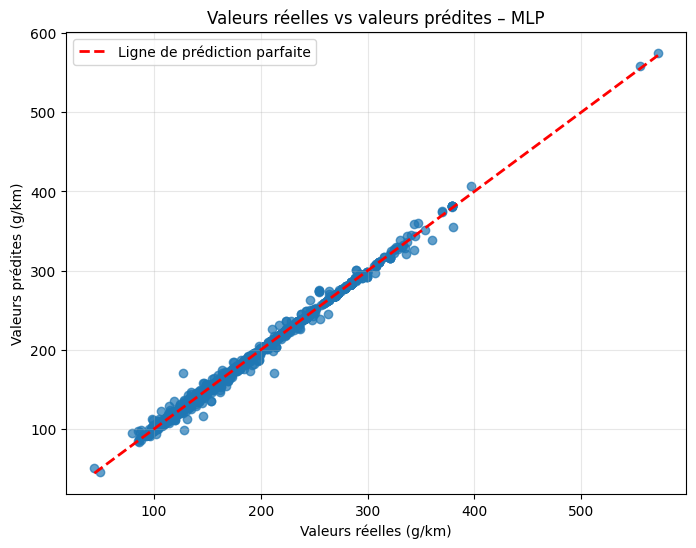

In [152]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred_mlp,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – MLP")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

Le graphique met en évidence une très forte concordance entre les valeurs réelles et les valeurs prédites par le Perceptron Multicouche (MLP). La majorité des observations est répartie le long de la diagonale représentant la prédiction parfaite, ce qui confirme la très bonne capacité du modèle à estimer les émissions de CO₂.

Quelques écarts ponctuels sont néanmoins observés, mais ils restent limités au regard de l'ensemble des prédictions et n'altèrent pas les bonnes performances globales du modèle.

### Analyse des résidus

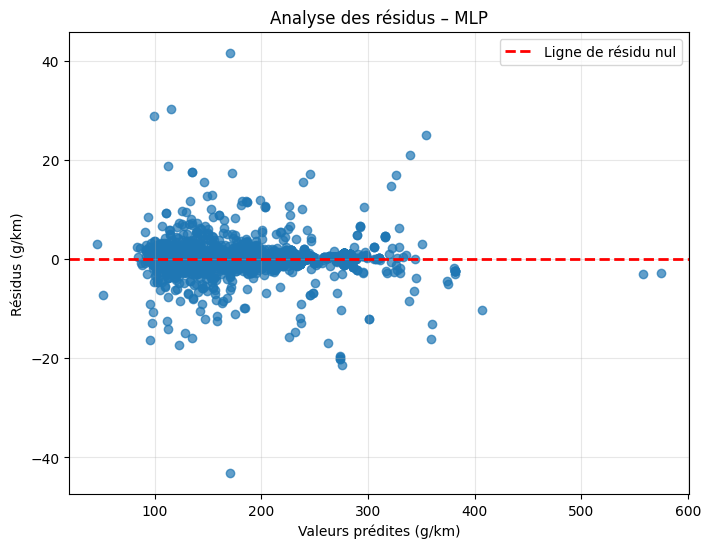

In [153]:
residus_mlp = y_test - y_pred_mlp

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_mlp,
    residus_mlp,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus – MLP")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

L'analyse des résidus montre que la majorité des erreurs de prédiction du Perceptron Multicouche (MLP) reste concentrée autour de zéro, ce qui traduit globalement une bonne qualité des prédictions.

On observe néanmoins quelques erreurs ponctuelles plus importantes, avec des résidus positifs et négatifs, sans tendance systématique clairement identifiable. Ces observations restent toutefois limitées au regard de l'ensemble des données et sont cohérentes avec les bonnes performances globales obtenues par le modèle.

### Courbe d'apprentissage

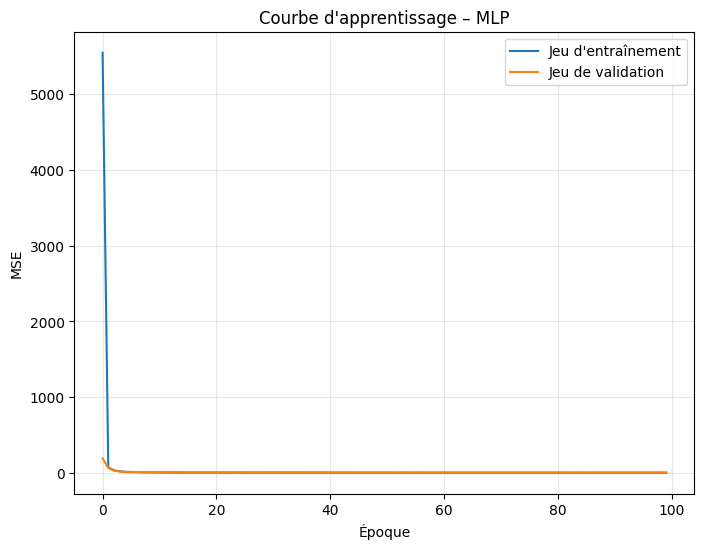

In [154]:
plt.figure(figsize=(8,6))

plt.plot(
    history.history["loss"],
    label="Jeu d'entraînement"
)

plt.plot(
    history.history["val_loss"],
    label="Jeu de validation"
)

plt.xlabel("Époque")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage – MLP")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

La courbe d'apprentissage montre que le Perceptron Multicouche converge rapidement au cours des premières époques d'entraînement. Les erreurs sur les jeux d'entraînement et de validation diminuent fortement avant de se stabiliser, ce qui traduit un apprentissage efficace du réseau.

Les deux courbes présentent une évolution globalement similaire, sans divergence durable clairement visible à cette échelle. Toutefois, les valeurs initiales élevées de la fonction de coût rendent difficile l'observation des écarts entre les courbes en fin d'entraînement.

Les résultats obtenus sur le jeu de validation restent encourageants et ne mettent pas en évidence de surapprentissage majeur, même si une analyse plus détaillée des dernières époques serait nécessaire pour confirmer ce constat.

### Comparaison avec les autres modèles

In [155]:
comparaison_mlp = pd.DataFrame({
    "Modèle": [
        "MLP",
        "XGBoost",
        "Random Forest",
        "LightGBM"
    ],
    "MAE": [
        mae_mlp,
        mae_xgb,
        mae_rf_opt,
        mae_lgbm_opt
    ],
    "RMSE": [
        rmse_mlp,
        rmse_xgb,
        rmse_rf_opt,
        rmse_lgbm_opt
    ],
    "R²": [
        r2_mlp,
        r2_xgb,
        r2_rf_opt,
        r2_lgbm_opt
    ],
    "MAPE": [
        mape_mlp,
        mape_xgb,
        mape_rf_opt,
        mape_lgbm_opt
    ]
})

comparaison_mlp = comparaison_mlp.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

comparaison_mlp.round(4)

,Modèle,MAE,RMSE,R²,MAPE
0,XGBoost,0.2908,0.5940,0.9997,0.0017
1,Random Forest,0.0925,0.7112,0.9996,0.0006
2,LightGBM,0.3701,1.2902,0.9986,0.0021
3,MLP,0.5863,1.5947,0.9978,0.0034


## Comparaison globale des modèles

### Introduction

Après avoir entraîné et évalué plusieurs modèles de régression, il est nécessaire de comparer leurs performances afin d'identifier celui qui prédit le plus précisément les émissions de CO₂.

Cette comparaison s'appuie sur les principales métriques d'évaluation (MAE, RMSE, R² et MAPE) calculées sur le jeu de test. Elle permet de mettre en évidence les forces et les limites de chaque approche, depuis les modèles linéaires jusqu'aux méthodes d'ensemble et au réseau de neurones artificiel.

## Tableau comparatif final

### Analyse comparative

In [156]:
comparaison_modeles = pd.DataFrame({
    "Modèle": [
        "DummyRegressor",
        "Régression linéaire",
        "Ridge",
        "Lasso",
        "Arbre de décision",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "MLP"
    ],
    "MAE": [
        mae_dummy,
        mae_lin,
        mae_ridge_opt,
        mae_lasso_opt,
        mae_tree_opt,
        mae_rf_opt,
        mae_xgb,
        mae_lgbm_opt,
        mae_mlp
    ],
    "RMSE": [
        rmse_dummy,
        rmse_lin,
        rmse_ridge_opt,
        rmse_lasso_opt,
        rmse_tree_opt,
        rmse_rf_opt,
        rmse_xgb,
        rmse_lgbm_opt,
        rmse_mlp
    ],
    "R²": [
        r2_dummy,
        r2_lin,
        r2_ridge_opt,
        r2_lasso_opt,
        r2_tree_opt,
        r2_rf_opt,
        r2_xgb,
        r2_lgbm_opt,
        r2_mlp
    ],
    "MAPE": [
        mape_dummy,
        mape_lin,
        mape_ridge_opt,
        mape_lasso_opt,
        mape_tree_opt,
        mape_rf_opt,
        mape_xgb,
        mape_lgbm_opt,
        mape_mlp
    ]
})

comparaison_modeles = comparaison_modeles.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

comparaison_modeles.round(4)

,Modèle,MAE,RMSE,R²,MAPE
0,XGBoost,0.2908,0.5940,0.9997,0.0017
1,Random Forest,0.0925,0.7112,0.9996,0.0006
2,Arbre de décision,0.1423,0.8176,0.9994,0.0010
3,LightGBM,0.3701,1.2902,0.9986,0.0021
4,MLP,0.5863,1.5947,0.9978,0.0034
5,Lasso,1.0922,1.7401,0.9974,0.0059
6,Ridge,1.0925,1.7401,0.9974,0.0060
7,Régression linéaire,1.0922,1.7402,0.9974,0.0059
8,DummyRegressor,22.4525,34.1556,-0.0000,0.1298


L'analyse comparative montre que l'ensemble des modèles de Machine Learning et de Deep Learning surpasse très largement le DummyRegressor, ce qui confirme que les variables explicatives retenues contiennent une information importante pour prédire les émissions de CO₂.

Parmi les modèles étudiés, XGBoost présente le **R² le plus élevé (0,9997)** ainsi que le **RMSE le plus faible (0,5940 g/km)**, traduisant une excellente capacité prédictive.

Random Forest obtient également d'excellentes performances, avec un **R² de 0,9996** et un **RMSE de 0,7112 g/km**. Il se distingue notamment par la **MAE et la MAPE les plus faibles**, avec respectivement **0,0925 g/km** et **0,0006**.

L'Arbre de décision conserve des performances remarquables, avec un **R² de 0,9994**, un **RMSE de 0,8176 g/km**, une **MAE de 0,1423 g/km** et une **MAPE de 0,0010**.

Le Perceptron Multicouche (MLP) obtient également de très bonnes performances, avec un **R² de 0,9978** et un **RMSE de 1,5947 g/km**. Il reste toutefois en retrait par rapport à LightGBM optimisé, qui obtient de meilleurs résultats sur l'ensemble des métriques.

Les modèles linéaires obtiennent également de bons résultats, mais restent globalement en retrait par rapport aux modèles les plus performants de cette étude. Après optimisation, Lasso, Ridge et la Régression linéaire présentent des performances très proches, avec un **R² de 0,9974**.

Au regard de l'ensemble de ces résultats, **XGBoost est retenu comme modèle principal de l'étude**, notamment en raison de son R² élevé et de son RMSE particulièrement faible. Random Forest constitue néanmoins une excellente alternative, notamment pour minimiser les erreurs absolues moyennes.

## Conclusion générale de la modélisation

Cette étude a permis de comparer plusieurs familles de modèles afin de prédire les émissions de CO₂ des véhicules.

Les modèles linéaires constituent une première approche pertinente et offrent des performances satisfaisantes. Toutefois, leurs performances restent inférieures à celles obtenues par les méthodes d'ensemble sur ce jeu de données.

Les arbres de décision et les méthodes d'ensemble améliorent significativement les performances. En particulier, Random Forest, LightGBM et surtout XGBoost obtiennent des résultats remarquables, démontrant leur capacité à modéliser efficacement les relations présentes dans les données.

L'expérimentation menée avec un Perceptron Multicouche (MLP) montre également qu'un réseau de neurones simple constitue une alternative performante. Avec un **R² de 0,9978** et un **RMSE de 1,5947 g/km**, il obtient de très bonnes performances, même s'il reste en retrait par rapport aux modèles les plus performants de cette étude.

Les expérimentations complémentaires, notamment la validation croisée et la transformation logarithmique de la variable cible, ont permis de renforcer l'analyse des modèles. La validation croisée met en évidence la stabilité des performances observées sur différentes partitions du jeu d'entraînement, tandis que la transformation logarithmique n'apporte pas d'amélioration dans les configurations testées.

Enfin, l'analyse d'interprétabilité réalisée avec SHAP met en évidence les variables les plus influentes dans les prédictions de XGBoost. Elle révèle notamment la contribution prédominante de la consommation mixte (`conso_mixte`), fortement liée aux émissions de CO₂. Cette relation contribue à expliquer les performances particulièrement élevées des modèles et constitue un élément important à prendre en compte dans l'interprétation des résultats.

Au regard de l'ensemble des expérimentations réalisées, **XGBoost est retenu comme modèle principal de cette étude**. Il présente le **R² le plus élevé (0,9997)** ainsi que le **RMSE le plus faible (0,5940 g/km)**, tout en présentant des performances stables lors de la validation croisée. Random Forest constitue également une alternative particulièrement performante, avec les erreurs absolues moyennes les plus faibles.

# Perspectives d'évolution

### Introduction

Bien que les résultats obtenus soient très satisfaisants, plusieurs pistes d'amélioration ont été identifiées au cours du projet. Certaines ont déjà été mises en œuvre afin d'en évaluer l'intérêt, tandis que d'autres constituent des axes de travail pouvant être explorés dans le cadre de futurs développements. Ces perspectives pourraient permettre d'améliorer encore les performances des modèles ou de renforcer la robustesse de l'approche proposée.

### 1. Généraliser le Target Encoding

Au cours du projet, le Target Encoding a été testé en remplacement du One-Hot Encoding sur certaines variables catégorielles. Cette approche a permis de réduire significativement le nombre de variables créées tout en conservant des performances très proches de celles obtenues avec le One-Hot Encoding.

Une perspective intéressante consisterait à appliquer systématiquement le Target Encoding à l'ensemble des modèles afin d'évaluer son impact sur leurs performances, leur temps d'entraînement et leur capacité de généralisation.

### 2. Approfondir les architectures de Deep Learning

Le Perceptron Multicouche testé dans cette étude repose sur une architecture volontairement simple. L'exploration de réseaux plus profonds, ainsi que l'utilisation de techniques telles que Dropout, Batch Normalization ou EarlyStopping, pourrait permettre d'améliorer encore les performances du modèle.

### 3. Poursuivre l'optimisation des hyperparamètres

Les modèles les plus performants pourraient faire l'objet d'une optimisation plus poussée à l'aide de méthodes avancées telles que l'optimisation bayésienne ou Optuna, afin d'identifier des configurations encore plus performantes.

### 4. Explorer d'autres approches de Machine Learning

Enfin, il serait pertinent d'évaluer d'autres algorithmes performants, tels que CatBoost, ExtraTrees ou d'autres architectures de réseaux de neurones, afin de comparer leurs performances à celles des modèles étudiés et de confirmer le choix de XGBoost comme modèle de référence.

## Export du modèle final

Le modèle XGBoost retenu est sauvegardé afin de pouvoir être réutilisé dans l'application Streamlit sans nécessiter un nouvel entraînement.

In [177]:
from pathlib import Path

# Création du dossier models s'il n'existe pas
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarde du modèle XGBoost final
xgb.save_model(models_dir / "xgboost_co2.json")

print("Modèle sauvegardé :", models_dir / "xgboost_co2.json")

Modèle sauvegardé : ../models/xgboost_co2.json
